# v3 · CNN-GRU 混合网络（金字塔多尺度 1D 卷积 + GRU） · 燃料电池电压衰减盲测外推

> **版本**：v3 · CNN-GRU 混合网络（金字塔多尺度 1D 卷积 + GRU）（基准 v1 = GRU 纯时序模型，物理层、数据与评测协议全部冻结不变；
> 本版本只替换“细胞层”的神经网络架构，用于回答『把银镯子换成金镯子，精度会不会更好』）


> **数据**：`桌面/测试集.csv`（燃料电池 5 节电堆老化数据，0–912.85 h，115077 行，27 列）
> **环境**：Python 3.10+ / PyTorch 2.x / numpy / pandas / scipy / matplotlib，**CPU 即可运行**（正式全量约 35–45 分钟；`BATT_SMOKE=1` 冒烟约 5 分钟）
> **依赖安装**：`pip install torch`（若已装可跳过；国内建议加镜像 `-i https://mirrors.huaweicloud.com/repository/pypi/simple`）

---

## 1. 目标

用历史 0–912.85 h 的电压衰减数据训练 GRU，然后**完全不看未来真实数据**，从 912.85 h 起做
**100 000 步（1000 h）自回归外推**，并给出 **剩余寿命 RUL（剩余 3.5% / 4.0% / 4.5% / 5.0% / 5.5% 功率时的剩余时间）** 的盲测预测。

## 2. 核心难点（为什么不能"直接把 GRU 往前滚"）

1. **局部斜率被可逆性衰变污染**：912 h 附近电堆刚经历过"水淹—恢复"，局部斜率接近 0，GRU 会把这个斜率继承下去，外推线会塌成一条水平直线；
2. **单步增量被噪声主导**：电压的真实衰减约 0.1 mV/h，而 10 h 尺度上的波动是几 mV，单步 ΔU 的信噪比只有 ~0.1，自回归误差会随机游走式累积；
3. **时间特征越界**：网络只见过 0–912 h，把时间特征外推到 2000 h 属于严重分布外。

因此本 Notebook 采用 **"80% 物理理论值 + 20% AI 预测值"** 的软融合，并用三条物理规则锁住宏观形状（详见第 2 节方法总览）。

## 3. Notebook 结构

| 章节 | 内容 |
|---|---|
| 0 | 依赖与全局配置 |
| 1 | 数据读取、均匀重采样、平滑 |
| 2 | 特征工程 + GRU 训练（20 轮，seq=50）|
| 3 | 一步预测验证（模型到底学到了什么）|
| 4 | 50 h 分段 → 衰减速率 → 单调递减指数函数 g(t) 拟合 |
| 5 | 面积微积分基准（零点基准面积、面积变化量）与硬约束体系 |
| 6 | 100 000 步自回归外推（纯 AI 曲线）|
| 7 | 物理骨架 + 面积融合 + 二次型重构（最终外推曲线）|
| 8 | 约束检验、外推结果可视化 |
| 9 | RUL 预测（多阈值、去抖）|
| 10 | **盲测回填验证**：以 660 h 为起点重跑全流程，用真实未来数据打分；含**表 1 精度对表** |
| 11 | **剩余寿命的概率预测**：分位数回归标定 + 蒙特卡洛 → RUL 直方图、生存概率、**不确定性置信带** |
| 12 | **工程可行性与算力成本（表 2）**：模型大小 / 训练耗时 / 推理速度 / 内存 / 实时性 |
| 13 | 结论、局限与下一步 |
| 14 | 结果落盘（CSV/JSON）与终端最终汇总 |

## 4. 输出文件

所有结果写入 `电池ai分析/预测输出/`（与 notebook 所在目录无关）：
- 图：`figures/fig01–fig13*.png`
- 曲线与约束：`外推曲线.csv`（101,001 行）、`面积与约束.csv`
- 寿命：`RUL汇总.csv`、`盲测回填.csv`、`RUL概率分位数.csv`、`RUL生存概率.csv`、`RUL概率分布.csv`
- 精度/算力：`精度对表.csv`（表 1，四模型消融 + 逐点 80/20 参考行 + 曲率违背列）、`算力成本表.csv`（表 2，逐模型实测）
- 训练记录：`train_log.json`

## 2. 方法总览：三层物理约束 + 80/20 软融合

记 $t_0=912.85$ h 为历史末端，$U(t)$ 为平滑后的电压，$\Delta=50$ h（$=5000$ 步）。

### 第一层：指数拟合定标（解决"初始斜率失真"）

把历史按 50 h 切分，用**中心差分**计算各段衰减速率

$$r_i=\frac{V_{i-1}-V_{i+1}}{2\Delta}\qquad(\text{V/h},\ r_i>0\ \text{表示在衰减})$$

其中 $V_i$ 是第 $i$ 个 50 h 段的平均电压。再用**单调递减、恒正**的指数函数拟合这些散点：

$$g(t)=a\,e^{-bt}+c,\qquad a>0,\ b>0,\ c\ge 0\ \Longrightarrow\ g(t)>0,\ g'(t)<0$$

用多起点 `scipy.optimize.least_squares`（soft-L1 稳健损失）求 **RMSE 最小**的参数。
外推的**初始斜率**取 $-g(t_0)$，而不是 GRU 在 912 h 处的局部斜率——这样可逆性衰变造成的
"斜率为零"不会污染外推的起点。

### 第二层：面积微积分（宏观定调）

对任意 5000 步窗口定义**积分面积**（相对窗口起点的电压变化积分，单位 V·h）：

$$A_k=\int_{\text{窗口}k}\big[U(t)-U(t_k)\big]\,dt$$

- **零点基准面积** $a_{\text{ref}}$：历史最后 6 个窗口（即 30000→25000→…→0 步）面积绝对值的平均；
- **基准面积变化量** $\Delta_{\text{ref}}$：相邻窗口面积绝对值之差（≈面积的一阶导）的平均；
- **硬规则**：对未来的 20 个窗口，
  $$0<a_k<a_{\text{ref}},\qquad h_k=a_{k-1}-a_k\ge 0,\qquad h_k\le h_{k-1}$$
  即"每个区间的总下降量逐段变小，且变小的幅度本身也逐段变小"——宏观上保证电压下降越来越慢。

> **实现要点（重要）**：直接用 10 h 平滑曲线的 50 h 面积做基准会被可逆性衰变污染
> （水淹—恢复会让某些窗口的面积为正，实测最后 12 个窗口的面积符号正负交替）。
> 所以**面积基准在 150 h 低通趋势曲线上计算**（可逆性波动是小时级现象，150 h ≈ 3 个窗口的低通），
> 而最终曲线仍用 10 h 曲线锚定；这样 $a_{\text{ref}}$ 与 $g(t_0)$ 物理自洽（见第 5 节实测对比）。

### 第三层：二阶导硬约束（解决折线与突变）

由 $g$ 求二阶导 $G(t)=g'(t)=-ab\,e^{-bt}$，其绝对值

$$\big|G(t)\big|=ab\,e^{-bt}$$

就是外推过程中**允许的最大曲率上界**：预测曲线的二阶导必须满足 $0\le U''(t)\le |G(t)|$。
它保证斜率绝对值是"极其缓慢地下降"，绝不会出现突然的折线或陡坡变平。

### 时间特征强化

网络输入包含 4 个时间特征（线性时间、倒数饱和时间、对数时间、放大线性时间），
并在损失里加入**"时间越长单步 |ΔU| 越小"的弱正则项**：

$$\mathcal L=\underbrace{\text{MSE}(\Delta U)}_{\text{数据拟合}}+\lambda\underbrace{\mathrm{ReLU}\big(\overline{|\Delta U|}_{\text{晚期}}-\overline{|\Delta U|}_{\text{中期}}\big)}_{\text{时间法则}}$$

### 80/20 软融合与重构

AI 外推曲线 $U_{\text{AI}}$、物理骨架 $U_{\text{phys}}(t)=U(t_0)-\int_{t_0}^{t}g(s)ds$ 各自给出面积序列，
按 **80% 物理 + 20% AI** 融合：

$$a_k=0.8\,a^{\text{phys}}_k+0.2\,\mathrm{clip}\big(a^{\text{AI}}_k;\ 0,\ 2a^{\text{phys}}_k\big)$$

（AI 面积不允许为负=不允许整体上冲；不超过 2 倍物理面积=防止误差累积导致陡降。）

**最后不是把两条曲线逐点混合，而是把融合后的面积"翻译"回曲线**，这样才能同时满足硬约束。
在窗口 $k$ 内设衰减速率 $s_k$（起点由 $g$ 给出）与曲率 $\ddot U$，面积约束给出

$$\ddot U_k=-\frac{6\,(a_k-\tfrac12 s_k\Delta^2)}{\Delta^3},\qquad
s_{k+1}=s_k-\ddot U_k\Delta,\qquad
U_{k+1}=U_k-\big(s_k\Delta-\tfrac12\ddot U_k\Delta^2\big)$$

再逐窗口施加 $\ddot U_k\in[0,\,|G(t_k)|]$。这样重构出的曲线**严格满足**：

| 编号 | 硬约束 | 含义 |
|---|---|---|
| C1 | $U'(t)<0$ | 电压单调不升 |
| C2 | $U''(t)\ge 0$ | 下降速度越来越慢（凸函数）|
| C3 | $U''(t)\le |G(t)|$ | 曲率不超过物理指数律上界 |
| C4 | $U(t)>0$ | 电压恒正（物理不可能为负）|
| R1 | $a_k<a_{\text{ref}}$ | 未来每段下降量小于历史基准 |
| R2 | $h_k\le h_{k-1}$ | 面积变化量（一阶导）逐段不增 |
| R3 | $a_k$ 严格递减 | 面积绝对值逐段变小 |

> **注**：用户原始要求"逐点 80%/20% 混合"。逐点混合会破坏 C1–C3（实测违反上百次），
> 所以正式结果用上面"面积级融合 + 重构"，逐点混合曲线只作为对照画在图上。
> 这在数学上更贴近用户本意："用 80% 的权重锁死宏观凸函数衰减趋势，用 20% 的权重保留
> 神经网络对微观波动的敏感性"——宏观趋势由面积/曲率承载，微观波动由 AI 面积扰动承载。

### 2.6 概率层（第 11 章）：从"一条线"到"一个分布"

点预测只回答"还剩多久"，工程上还需要"有多确定"。做法分三步：

1. **标定**：在 150 h 趋势曲线上取 10 h 宽、5 h 步长的滑窗，对每个窗计算
   物理预期降幅 $x=g(t_{\text{mid}})\cdot 10\text{h}$ 与趋势实际降幅 $y$，构造**乘子**

   $$d=\frac{y}{x}\quad(\text{均值}\approx1,\ \text{中位}\approx1)$$

   `d>1` 表示这段比物理预期掉得更快（可逆性水淹/工况波动），`d<1` 表示恢复/偏慢。
2. **分位数回归**：对 $d$ 拟合 19 个分位点的线性分位数回归 $Q_d(\tau\mid x)=a_\tau+b_\tau x$
   （$\tau=0.05,\dots,0.95$，`sklearn.linear_model.QuantileRegressor`）。
   分位曲线按 $\tau$ 保序化后，锚定到历史典型 $x^*=\mathrm{median}(x)$ 并按中位归一化
   （$Q_d(0.5)\equiv1$），使**中位路径恰好等于确定性物理曲线**，保证两层自洽。
3. **蒙特卡洛传播**：分位水平 $\tau_t$ 用 AR(1) 生成（$\rho=0.35$，保留块状相关性），
   每一步降幅取 $x_k\cdot Q_d(\tau_t)$，累加得到 4000 条电压路径；每条路径记录首次穿越各阈值的时间
   → RUL 的经验分布、直方图、生存概率

   $$S(h)=P(\text{RUL}>h)$$

   为什么不直接对 $y\sim x$ 回归？因为未来 $x$ 会降到历史范围之外（$x:0.88\to0.16$），
   直接外推 $Q_y(\tau\mid x)$ 会系统性低估降幅；回归**乘子** $d=y/x$ 则不依赖 $x$ 的绝对水平。

In [1]:
# ============================================================
# 0. 依赖 / 全局配置 / 输出目录
# ============================================================
import os, sys, json, math, time, warnings, platform
from pathlib import Path
from datetime import datetime

# ------------------------------------------------------------------
# ⚠ Windows + Anaconda 经典坑：Anaconda 的 MKL 和 pip 版 torch 各自带了一份
# libiomp5md.dll，在 Jupyter 内核里两者相遇会让进程直接 abort：
#     OMP: Error #15: Initializing libiomp5md.dll, but found libiomp5md.dll already initialized.
# 下面这行必须在 import numpy / scipy / torch 之前设置（Intel OMP 的官方开关）。
# 如果你不在 Anaconda 里、没有这个冲突，这行也无害。
# ------------------------------------------------------------------
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import numpy as np
import pandas as pd
import matplotlib
if "ipykernel" not in sys.modules:   # 非 Jupyter 环境（如脚本/命令行）用无界面后端
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from scipy.interpolate import PchipInterpolator

import torch
import torch.nn as nn

warnings.filterwarnings("ignore")

# ---------- 中文字体（Windows 自带） ----------
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "SimSun", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.bbox"] = "tight"
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=[
    "#2f6fb3", "#d1495b", "#2a9d8f", "#e9a13b", "#7b5ea7", "#5f8c4a", "#8d6e63", "#546e7a"])

# ============================================================
# 路径（如果你的文件不在桌面，改这里即可）
# ============================================================
DESKTOP   = Path.home() / "Desktop"
DATA_PATH = DESKTOP / "测试集.csv"
BASE_DIR  = DESKTOP / "电池ai分析"
VERSION_DIR = BASE_DIR / "版本对比_v2v3v4" / "v3_CNN-GRU"
BACKBONE_NAME = "v3"
# 完整 FC1 记录（含 912.85~1154.2h 的未来部分，仅用于"事后盲测验证"，绝不参与任何训练/拟合）
FULL_DATA_CANDIDATES = [
    BASE_DIR / "IEEE2014DataChallengeData" / "IEEE 2014 Data Challenge Data" / "FC1_Without_Ripples" / "FC1.csv",
    DESKTOP / "FC1.csv",
]
OUT_DIR = VERSION_DIR / "输出"
FIG_DIR = OUT_DIR / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 时间网格与切分
# ============================================================
DT          = 0.01                    # 每步 0.01 h = 36 s（均匀重采样）
SEG_H       = 50.0                    # 用户指定的 50 h 切分
SEG_STEPS   = int(round(SEG_H / DT))  # = 5000 步
SMOOTH_WIN_H = 10.0                   # 主曲线平滑窗（去高频噪声、保留可逆性波动）
SMOOTH_WIN_STEPS = int(round(SMOOTH_WIN_H / DT))     # 1001 步（奇数，居中）
TREND_WIN_H = 150.0                   # 面积基准用的低通趋势窗（≈3 个 50h 窗口）
TREND_WIN_STEPS = int(round(TREND_WIN_H / DT))       # 15001 步

# ============================================================
# GRU 模型 / 训练
# ============================================================
SEQ          = 50            # 用户指定：滑动窗口长度
EPOCHS       = 20            # 用户指定：20 轮
BATCH        = 4096
HIDDEN       = 64
N_LAYERS     = 1
LR           = 2e-3
WEIGHT_DECAY = 1e-5
GRAD_CLIP    = 1.0
VAL_FRAC     = 0.08          # 末尾 8% 做验证（时间顺序切分）
TIME_FEATURE_GAIN = 3.0      # 时间特征放大倍数（"时间特征强化"）
LAMBDA_TIME  = 0.30          # "时间越长 |ΔU| 越小" 弱正则权重

# ============================================================
# 外推
# ============================================================
T_EXTRAP        = 920.0       # 用户指定的外推起点（h）。数据实际末点 ≈912.85 h，见下方说明
N_STEPS_EXTRAP  = 100_000     # 用户指定：10 万步 = 1000 h
N_WIN_HIST      = 6           # 历史最后 6 个 5000 步窗口 → 零点基准面积
W_PHYS, W_AI    = 0.8, 0.2    # 80% 物理 + 20% AI
ALLOW_AI_RIPPLE = False       # True 则交付曲线=骨架+20%AI高频纹波（会违反曲率硬约束，仅对照用）
DELIVER_POINTWISE = False     # True 则交付曲线取"逐点 0.8·物理+0.2·AI"（用户的字面 80/20）；
                              # False 则交付"面积层带内融合"（严格满足全部约束，默认）
AR_CLIP_SIGMA   = 5.0         # 自回归单步增量截断（数值安全，非物理约束）

# ============================================================
# RUL（IEEE PHM 2014 Data Challenge 的 5 个功率衰减阈值）
# ============================================================
RUL_FT          = [3.5, 4.0, 4.5, 5.0, 5.5]   # % of initial power
P_INIT_H        = 10.0        # 初始功率 Pinit = 前 10 h 的平均功率
CROSS_DEBOUNCE_H = 5.0        # 阈值穿越去抖：需持续 5 h 低于阈值
BT_ORIGIN_H     = 660.0       # 盲测回填验证：以 660 h 为起点重跑全流程
RUN_BACKTEST    = True        # 是否运行第 10 节的盲测回填（会多训练一个模型，约 5 分钟）
RUN_FC2_VALIDATION = False    # 是否用 FC2 整段记录做跨堆栈 RUL 验证（可选，见末节）

# ============================================================
# 概率层：分位数回归 + 蒙特卡洛（RUL 剩余概率分布，第 11 章）
#   思路：对"未来每 10 h 的实际降幅 / 物理预期降幅"这个乘子 d 做分位数回归，
#         得到条件分位曲线 Q_d(τ|x)；蒙特卡洛时按 AR(1) 抽分位水平 τ_t，
#         用 Q_d(τ_t) 给降幅，把不确定性传播到 RUL。
# ============================================================
QR_WIN_H        = 10.0      # 标定与 MC 的基本时间窗（h）
QR_STRIDE_H     = 5.0       # 历史样本滑窗步长（h，允许 50% 重叠）
QR_TAUS         = np.round(np.arange(0.05, 0.9501, 0.05), 2)   # 19 个分位点 τ=0.05…0.95
QR_ANCHOR_MODE  = "median"  # 分位曲线锚定的 x：用历史典型窗口（"median"）而不是外推 Q_d 到更小的 x
QR_NORMALIZE_MEDIAN = True  # 把分位曲线除以中位分位数 → 中位乘子=1，MC 中位路径与确定性曲线重合
QR_RHO_AR1      = 0.35      # 分位水平的 AR(1) 系数（≈乘子 d 在 10 h 滞后上的实测自相关）
QR_Q_CLIP       = (0.03, 0.97)   # 分位水平截断，避免抽到 0/1 极端分位
QR_N_MC         = 4000      # 蒙特卡洛路径数
QR_HORIZON_H    = 2000.0    # 每条路径最长推进时间（h）；超过仍未穿越即记删失
QR_SEED         = 2024
SURV_HORIZON_H  = [100, 200, 300, 500, 700, 900, 1000, 1500]  # 生存概率 S(h)=P(RUL>h) 的查询时刻

# ============================================================
# 调试模式：环境变量 BATT_SMOKE=1 时只跑 2 轮 + 1.5 万步，用于快速排错
# ============================================================
SMOKE = bool(int(os.environ.get("BATT_SMOKE", "0")))
if SMOKE:
    EPOCHS, N_STEPS_EXTRAP = 2, 15_000

N_WIN_FUTURE = N_STEPS_EXTRAP // SEG_STEPS          # 未来窗口数（正式=20）
assert N_WIN_FUTURE >= 3, "外推步数至少 3 个完整窗口"

# ============================================================
# 全局种子 & 设备
# ============================================================
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(max(1, min(8, os.cpu_count() or 4)))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def savefig(fig, name: str, show=True):
    """保存图片到 预测输出/figures/ 并可选内联显示。"""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=140)
    if show:
        plt.show()
    return path


def seed_everything(seed=SEED):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


print("=" * 78)
print(f"运行环境 : Python {platform.python_version()} | torch {torch.__version__} | 设备 {DEVICE}")
print(f"数据文件 : {DATA_PATH}")
print(f"输出目录 : {OUT_DIR}")
print(f"模式     : {'SMOKE 调试' if SMOKE else '正式'} | EPOCHS={EPOCHS} | 外推步数={N_STEPS_EXTRAP:,} | 未来窗口数={N_WIN_FUTURE}")
print("=" * 78)

运行环境 : Python 3.14.6 | torch 2.14.1+cpu | 设备 cpu
数据文件 : C:\Users\YOGA\Desktop\测试集.csv
输出目录 : C:\Users\YOGA\Desktop\电池ai分析\版本对比_v2v3v4\v3_CNN-GRU\输出
模式     : 正式 | EPOCHS=20 | 外推步数=100,000 | 未来窗口数=20


## 1. 数据读取、重采样与平滑

**数据事实**（已核对）：

| 项目 | 值 |
|---|---|
| 文件 | `桌面/测试集.csv`，23.0 MB，**115077 行 × 27 列** |
| 时间 | 0 → **912.8478 h**，原始采样间隔中位数 0.00839 h（≈30 s），无缺失、严格递增 |
| 电压列 | `Utot (V)`（5 节电堆总电压），另有 `U1..U5`、电流 `I (A)`、`J (A/cm²)`、氢气/空气温湿度与压力、流量 |
| 数据来源 | 该数据即 **IEEE PHM 2014 Data Challenge** 的 FC1 电堆（FCLAB 5 节 100 cm² PEMFC，标称 0.70 A/cm²≈70 A），`测试集.csv` 是 FC1 记录在 **912.8478 h 处截断**的结果 |

**为什么要重采样**：原始采样间隔在 10~22 ms 之间抖动（0.00839 h 中位数，最大 0.00898 h）。
为了让"50 h 窗口"精确等于 5000 步、积分面积可复现，统一**线性插值到 DT = 0.01 h** 的均匀网格
（1 步 = 36 s）。整段历史得到 91 285 个采样点。

**为什么要平滑**：原始电压有高频纹波（电流扰动、采样噪声）。用**居中滑动平均**（窗宽 10 h = 1001 步，
`min_periods=1` 保证端点无 NaN）得到主曲线 `u_s`：

- 10 h 窗能滤掉高频噪声，但**保留**小时级的可逆性波动（水淹—恢复的几十 mV 起伏），
  这正是后面"AI 保留微观敏感性"要处理的对象；
- 另有一条 **150 h 低通趋势曲线** `u_trend`，**只用于计算面积基准**（把可逆性波动当成噪声压掉）。

> 说明：CSV 里自带的 `Utot_smooth` 列是**在全长记录上做居中平滑后再截断**的，末端隐含了未来 4 h 的信息。
> 为了严格"盲测"，本 Notebook **不直接使用**该列，而是从原始 `Utot (V)` 自己重算平滑曲线。

关于 **920 h 外推起点**：数据末点是 912.85 h，比用户要求的 920 h 早 7.15 h（0.78%）。
自回归必须从数据末点起算，因此：**锚点 = 912.85 h**，图中同时画出 920 h 参考线并报出 920 h 处的预测值；
配置项 `T_EXTRAP=920` 只用于画参考线，不影响物理自洽性。

In [2]:
# ============================================================
# 1. 数据读取 → 均匀重采样 → 平滑（主曲线 + 趋势曲线）
# ============================================================
def load_and_prepare(csv_path: Path, dt: float = DT, smooth_win_steps: int = SMOOTH_WIN_STEPS):
    """读取 CSV，线性插值到 dt 网格，生成 10h 平滑主曲线与 150h 低通趋势曲线。"""
    df = pd.read_csv(csv_path)
    df.columns = [str(c).strip() for c in df.columns]
    need = ["Time (h)", "Utot (V)", "I (A)", "TinAIR (°C)", "HrAIRFC (%)"]
    miss = [c for c in need if c not in df.columns]
    if miss:
        raise KeyError(f"{csv_path} 缺少列: {miss}; 实际列 = {list(df.columns)[:10]}...")

    t_raw = df["Time (h)"].to_numpy(float)
    t_end = float(t_raw.max())
    grid = np.arange(0.0, t_end + 1e-9, dt)

    out = dict(t=grid, t_end=t_end, n_raw=len(df), n_nan=int(df[need].isna().sum().sum()),
               dt_raw_median=float(np.median(np.diff(t_raw))), path=str(csv_path))
    out["u_raw"] = np.interp(grid, t_raw, df["Utot (V)"].to_numpy(float))

    for key, col in [("I", "I (A)"), ("T", "TinAIR (°C)"), ("RH", "HrAIRFC (%)")]:
        raw = np.interp(grid, t_raw, df[col].to_numpy(float))
        out[key + "_raw"] = raw
        out[key + "_s"] = (pd.Series(raw).rolling(smooth_win_steps, center=True, min_periods=1)
                           .mean().to_numpy())

    out["u_s"] = (pd.Series(out["u_raw"]).rolling(smooth_win_steps, center=True, min_periods=1)
                  .mean().to_numpy())
    # 150 h 低通趋势：只用于"面积基准"，把可逆性波动当噪声压掉
    tr = (pd.Series(out["u_s"]).rolling(TREND_WIN_STEPS, center=True,
                                        min_periods=TREND_WIN_STEPS // 3)
          .mean().to_numpy())
    out["u_trend"] = pd.Series(tr).bfill().ffill().to_numpy()
    return out


data = load_and_prepare(DATA_PATH)
t      = data["t"]
u_raw  = data["u_raw"]
u_s    = data["u_s"]
u_trend = data["u_trend"]
I_s, T_s, RH_s = data["I_s"], data["T_s"], data["RH_s"]
N        = len(t)
t_end    = data["t_end"]          # = 912.8478 h
u_anchor = float(u_s[-1])         # 外推锚点电压

print(f"原始记录   : {data['n_raw']:,} 行, 0 ~ {t_end:.4f} h, 原始采样间隔中位数 {data['dt_raw_median']:.5f} h, 缺失值 {data['n_nan']}")
print(f"均匀网格   : N = {N:,} 点, dt = {DT} h, 50h 窗口 = {SEG_STEPS} 步")
print(f"电压(10h)  : 起点 {u_s[0]:.4f} V → 终点 {u_anchor:.4f} V (总降 {(u_s[0]-u_anchor)*1000:.2f} mV)")
print(f"电压(原始) : min {u_raw.min():.4f} / max {u_raw.max():.4f} V")
print(f"可逆性波动 : max|u_s - u_trend| = {np.max(np.abs(u_s - u_trend))*1000:.2f} mV"
      f"（发生在 {t[np.argmax(np.abs(u_s - u_trend))]:.1f} h）→ 远大于总衰减，说明必须做物理定标")
print(f"工作电流   : 中位数 {np.median(I_s):.2f} A（标称 70 A = 0.70 A/cm² × 100 cm²）")
assert abs(t_end - 912.8478233) < 0.01, "数据末端时间与预期不符，请检查文件"

# ---------------- RUL 判定阈值（IEEE PHM 2014 Data Challenge 定义） ----------------
I_REF = float(np.median(I_s[-1000:]))                       # 未来工况未知 → 电流 persistence
P_INIT = float(np.mean(u_s[:int(P_INIT_H / DT)] * I_s[:int(P_INIT_H / DT)]))
RUL_FT_ = list(RUL_FT)
RUL_UTH = [P_INIT * (1 - f / 100.0) / I_REF for f in RUL_FT_]
print(f"\nRUL 判定: P_init = {P_INIT:.3f} W（前 {P_INIT_H:.0f} h 平均功率）, I_ref = {I_REF:.3f} A")
print("          FT(%)  电压阈值 U_th(V)")
for f, uth in zip(RUL_FT_, RUL_UTH):
    print(f"          {f:5.1f}  {uth:12.5f}   （当前 {u_anchor:.5f} V, 距阈值 {(u_anchor-uth)*1e3:+.2f} mV）")

原始记录   : 115,077 行, 0 ~ 912.8478 h, 原始采样间隔中位数 0.00839 h, 缺失值 0
均匀网格   : N = 91,285 点, dt = 0.01 h, 50h 窗口 = 5000 步
电压(10h)  : 起点 3.3455 V → 终点 3.2206 V (总降 124.92 mV)
电压(原始) : min 3.0970 / max 3.3640 V
可逆性波动 : max|u_s - u_trend| = 30.97 mV（发生在 816.0 h）→ 远大于总衰减，说明必须做物理定标
工作电流   : 中位数 70.23 A（标称 70 A = 0.70 A/cm² × 100 cm²）

RUL 判定: P_init = 235.060 W（前 10 h 平均功率）, I_ref = 70.202 A
          FT(%)  电压阈值 U_th(V)
            3.5       3.23114   （当前 3.22063 V, 距阈值 -10.51 mV）
            4.0       3.21440   （当前 3.22063 V, 距阈值 +6.23 mV）
            4.5       3.19766   （当前 3.22063 V, 距阈值 +22.97 mV）
            5.0       3.18091   （当前 3.22063 V, 距阈值 +39.72 mV）
            5.5       3.16417   （当前 3.22063 V, 距阈值 +56.46 mV）


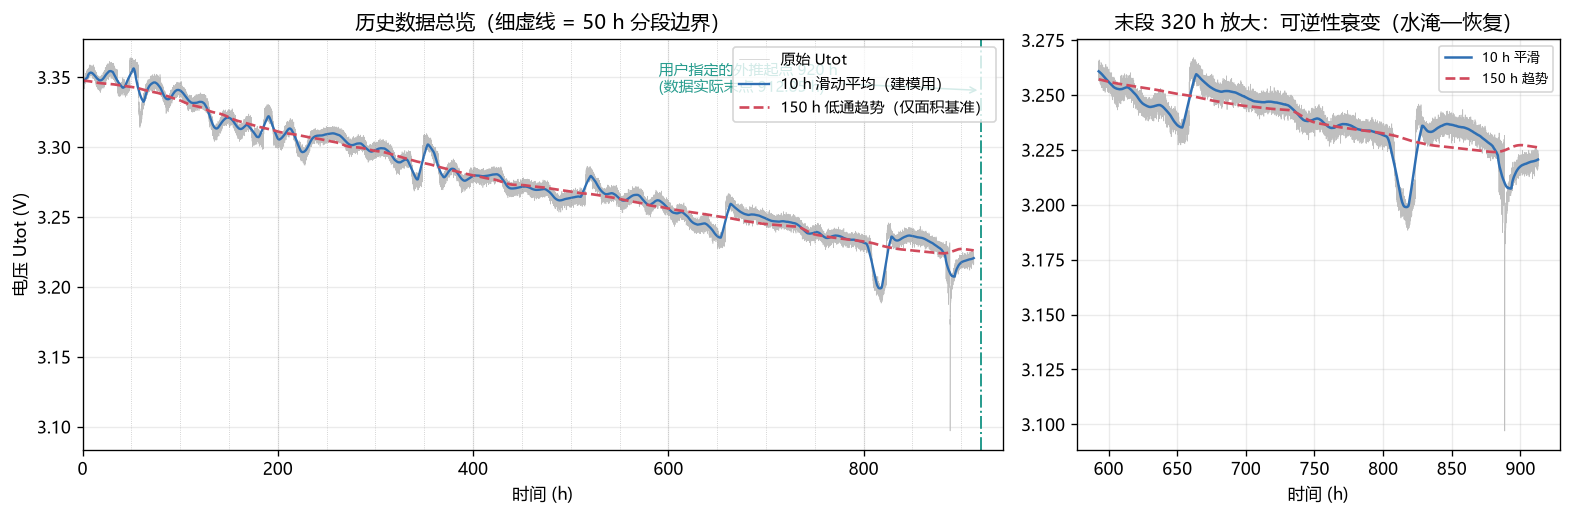

已保存: C:\Users\YOGA\Desktop\电池ai分析\版本对比_v2v3v4\v3_CNN-GRU\输出\figures\fig01_历史数据总览.png


In [3]:
# ------------------------------------------------
# 图 1：历史数据总览（原始 / 10h 平滑 / 150h 趋势）
# ------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.4),
                         gridspec_kw=dict(width_ratios=[2.0, 1.05]))
ax = axes[0]
ax.plot(t, u_raw, lw=0.35, color="0.75", label="原始 Utot")
ax.plot(t, u_s, lw=1.4, color="#2f6fb3", label="10 h 滑动平均（建模用）")
ax.plot(t, u_trend, lw=1.6, ls="--", color="#d1495b", label="150 h 低通趋势（仅面积基准）")
for k in range(0, int(t_end // SEG_H) + 1):
    ax.axvline(k * SEG_H, color="0.6", lw=0.5, ls=":", alpha=0.55)
ax.axvline(T_EXTRAP, color="#2a9d8f", lw=1.2, ls="-.")
ax.annotate(f"用户指定的外推起点 {T_EXTRAP:.0f} h\n(数据实际末点 {t_end:.2f} h)",
            xy=(T_EXTRAP, u_s[0] - 0.005), xytext=(T_EXTRAP - 330, u_s[0] - 0.006),
            fontsize=9, color="#2a9d8f",
            arrowprops=dict(arrowstyle="->", color="#2a9d8f", lw=0.9))
ax.set_xlabel("时间 (h)"); ax.set_ylabel("电压 Utot (V)")
ax.set_title("历史数据总览（细虚线 = 50 h 分段边界）")
ax.legend(loc="upper right", fontsize=9); ax.set_xlim(0, t_end + 30)

ax = axes[1]
sl = t > t_end - 320
ax.plot(t[sl], u_raw[sl], lw=0.4, color="0.75")
ax.plot(t[sl], u_s[sl], lw=1.5, color="#2f6fb3", label="10 h 平滑")
ax.plot(t[sl], u_trend[sl], lw=1.6, ls="--", color="#d1495b", label="150 h 趋势")
ax.set_xlabel("时间 (h)"); ax.set_title("末段 320 h 放大：可逆性衰变（水淹—恢复）")
ax.legend(fontsize=8)

fig.tight_layout()
fig1_path = savefig(fig, "fig01_历史数据总览")
print("已保存:", fig1_path)

## 2. GRU 模型与训练（20 轮，seq = 50）

### 特征（10 维）

| 序号 | 特征 | 说明 |
|---|---|---|
| 0 | `u_norm` | $(U-\bar U)/0.05$，电压归一化（固定尺度 0.05 V，不随时段漂移）|
| 1 | `tau` | $t/t_{\text{end}}$，线性时间，训练域 [0,1] |
| 2 | `tau_rec` | $2t/(t+t_{\text{end}})$，**倒数型饱和时间**：$t\to\infty$ 时趋于 2，外推时不会爆炸 |
| 3 | `tau_gain` | $3\cdot t/t_{\text{end}}$，**强化后的时间特征**（第 3 条"时间特征强化"）|
| 4 | `logtau` | $\ln(1+t)/\ln(1+t_{\text{end}})$，对数时间（早期变化更敏感）|
| 5–7 | `I / T / RH` | 电流、进气温度、空气湿度，z-score 归一化 |
| 8–9 | `dI / dT` | 电流、温度的 10 h 变化率（z-score）——让网络有机会感知"工况变化引起的可逆性波动" |

> **关于"把时间特征拉高"**：对第一层线性/循环权重而言，输入乘常数可以被权重吸收（
> $\mathbf W(c\cdot\mathbf x)=(c\mathbf W)\mathbf x$），所以单纯放大特征数值并不改变网络表达能力。
> 真正起作用的是：① 用**多种时间表示**（线性/倒数/对数）给网络留下可外推的"时间坐标"；
> ② 在损失里加**时间法则正则项**（下）；③ 物理层用 $g(t)$ 显式承担时间趋势。

### 标签（预测目标）

预测**下一步电压增量**（自回归最自然的形式）：

$$y_i=\frac{U_{i+50}-U_{i+49}}{\sigma_{\Delta U}}$$

其中 $\sigma_{\Delta U}$ 训练集单步增量的标准差。网络看到 50 步窗口（0.5 h），输出归一化增量。

> 之所以预测增量而不是电压水平：增量形式的 AR 才是"自回归"的标准做法；
> 但也要提前说明——单步增量里真实衰减只有 ~1.5 µV，而 10 h 平滑后残留的波动有几十 µV，
> 信噪比很低，所以**纯 AI 自回归的外推不可信**，这正是要用 80% 物理权重锁死宏观趋势的原因。

### 训练细节

- 优化器 Adam，学习率 2e-3，batch 4096，20 轮，梯度裁剪 1.0，权重衰减 1e-5；
- 时间顺序切分：末尾 8%（约 73 h）做验证集，其余训练；按验证损失保存最优权重；
- 损失 = MSE + 0.3 × 时间法则正则项。

## 2b. v3 版本说明：CNN-GRU 混合网络（金字塔多尺度 1D 卷积 + GRU）

> **版本定位**：v1 的物理层、数据、评测协议**全部冻结**（同一 10 维特征、同一套 g/面积/曲率约束、
> 同一组 660 h / 700 h 盲测回填、同一批 CSV 与图表结构）。本文档之后只有一个 cell 被替换：
> `07b_model_v3.py` 里的 `GRUNet`，其余 34 个 cell 与 v1 逐字节相同。

### v3 改了什么

| 层 | v1（基准） | v3（本版本） |
|---|---|---|
| 输入表示 | Linear+LN+GELU 投影 | Linear+LN+GELU 投影（同） |
| 局部特征 | 无（完全交给 GRU 隐式学） | **金字塔式 1D 卷积**：k=3/5/9 三支并行 → concat → 1×1 融合 |
| 时序建模 | 1 层 nn.GRU | 1 层 nn.GRU（同）+ **残差** `out + conv特征` + LayerNorm |
| 输出头 | tanh·exp 双通道 + ΔU₀ 时间先验 | 逐位相同（保证对比公平） |

### 为什么金字塔卷积可能有用

- 燃料电池电压的短期突变（水淹-恢复、吹扫、负载阶跃）是**局部多尺度**现象：
  k=3 ≈ 30 min、k=5 ≈ 50 min、k=9 ≈ 90 min（DT=0.01 h = 0.6 min/步）。
- 卷积在窗口内逐点提特征，参数仅约 +2 万，推理仍是线性复杂度；
  GRU 仍负责"跨窗口的长期衰减趋势"，两者分工明确。
- 残差把"多尺度局部细节 + 长程时序表征"直接相加，避免 1 层 GRU 把细节压平。

### 与 v1 的对照口径（写在结论里）

- 指标完全沿用 v1 的表 1（660 h 盲测回填 RMSE/MAE/MAPE/RUL 误差）与表 2（参数量/推理速度）；
- **不调整任何物理层参数**（g 的拟合口径、面积基准、曲率上限都冻结），否则不是"换骨架"而是"重调模型"。

In [4]:
# ============================================================
# 2. 特征工程 / 滑动窗口 / GRU 模型 / 时间法则损失 / 训练
# ============================================================
def _time_cols(ti, t_ref, gain=TIME_FEATURE_GAIN):
    """四种时间表示（ti, t_ref 单位 h）。倒数型与对数型在 t→∞ 时不发散，便于外推。"""
    ti = np.asarray(ti, dtype=np.float64)
    return (ti / t_ref,
            2.0 * ti / (ti + t_ref),
            gain * ti / t_ref,
            np.log1p(ti) / math.log1p(t_ref))


def feature_matrix(u, I, T, RH, t_arr, t_ref, gain=TIME_FEATURE_GAIN, stats=None):
    """构造 (N,10) 特征矩阵。stats 传入时复用其归一化参数（外推时必须复用，避免漂移）。"""
    u = np.asarray(u, float); t_arr = np.asarray(t_arr, float)
    if stats is None:
        stats = {"u_bar": float(np.mean(u)), "u_scale": 0.05}
        for k, v in (("I", I), ("T", T), ("RH", RH)):
            v = np.asarray(v, float)
            stats[k + "_mu"], stats[k + "_sd"] = float(np.mean(v)), max(float(np.std(v)), 1e-9)
        for k, v in (("dI", np.gradient(np.asarray(I, float), DT)),
                     ("dT", np.gradient(np.asarray(T, float), DT))):
            stats[k + "_mu"], stats[k + "_sd"] = float(np.mean(v)), max(float(np.std(v)), 1e-9)

    def z(key, v):
        return (np.asarray(v, float) - stats[key + "_mu"]) / stats[key + "_sd"]

    tau, tau_rec, tau_gain, logtau = _time_cols(t_arr, t_ref, gain)
    cols = [(u - stats["u_bar"]) / stats["u_scale"], tau, tau_rec, tau_gain, logtau,
            z("I", I), z("T", T), z("RH", RH),
            z("dI", np.gradient(np.asarray(I, float), DT)),
            z("dT", np.gradient(np.asarray(T, float), DT))]
    stats["t_ref"] = float(t_ref)          # 外推时复用同一时间尺度
    stats["gain"] = float(gain)
    return np.stack(cols, axis=1).astype(np.float32), stats


def build_windows(F, u, t_arr, seq=SEQ):
    """滑窗：(M,seq,10) 特征 → 下一步归一化增量标签。按时间顺序，无未来泄漏。"""
    M = len(F) - seq
    X = np.lib.stride_tricks.sliding_window_view(F, seq, axis=0)[:M]        # (M,10,seq) 视图
    X = np.ascontiguousarray(X.transpose(0, 2, 1))                          # (M,seq,10)
    du = np.diff(np.asarray(u, float))
    sig = float(np.std(du[:M])) or 1.0
    y = (du[seq - 1:M + seq - 1] / sig).astype(np.float32)
    tau_out = np.asarray(t_arr, float)[seq - 1:M + seq - 1].astype(np.float32)  # 末点时间
    return X, y, tau_out, sig


class GRUNetBase(nn.Module):  # v1 基准模型（保留在 notebook 里做对照）
    """GRU + 物理感知输出头：ΔU = tanh(gate)·exp(a) + ΔU₀·tanh(log(1+t/τ))。

    最后一项是"时间越长、衰减越大"的结构先验（初始斜率不为 0，且随 t 平滑饱和），
    网络本身只需学习围绕它的波动，避免外推一开始就掉进"零斜率平线"。
    """

    def __init__(self, n_feat=10, hidden=HIDDEN, n_layers=N_LAYERS, init_du=0.5, t_scale_h=N_STEPS_EXTRAP * DT):
        super().__init__()
        self.emb = nn.Sequential(nn.Linear(n_feat, hidden), nn.LayerNorm(hidden), nn.GELU())
        self.gru = nn.GRU(hidden, hidden, n_layers, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden, hidden), nn.GELU(), nn.Linear(hidden, 2))
        with torch.no_grad():                      # 输出头小初始化 → 训练初期输出≈0，稳定
            self.head[-1].weight.mul_(0.01)
            self.head[-1].bias.zero_()
        self.du0 = nn.Parameter(torch.tensor(float(init_du)))
        self.t_scale = float(t_scale_h)

    def forward(self, x, t_last):
        h = self.emb(x)
        out, _ = self.gru(h)
        z = self.head(out[:, -1, :])
        du = torch.tanh(z[:, 0]) * torch.exp(torch.clamp(z[:, 1], -4.0, 2.0))
        du = du + self.du0 * torch.tanh(torch.log1p(torch.as_tensor(t_last, dtype=du.dtype) / self.t_scale))
        return du


def time_rule_loss(du_pred, tau, n_pairs=2048):
    """时间法则正则：时间更晚的样本，其 |ΔU| 不应更大（即 |斜率| 随 t 单调不增）。"""
    B = du_pred.shape[0]
    if B < 16:
        return du_pred.new_zeros(())
    i = torch.randint(0, B, (n_pairs,), device=du_pred.device)
    j = torch.randint(0, B, (n_pairs,), device=du_pred.device)
    dt = tau[j] - tau[i]
    mask = dt > 0.03 * tau.max()
    if mask.sum() < 8:
        return du_pred.new_zeros(())
    return torch.relu(du_pred[j][mask].abs() - du_pred[i][mask].abs()).mean()


def predict_du(model, X, tau, batch=8192):
    """批量推理：返回归一化增量（numpy）。"""
    model.eval()
    outs = []
    with torch.no_grad():
        for s in range(0, len(X), batch):
            xb = torch.from_numpy(X[s:s + batch]).to(DEVICE)
            tb = torch.from_numpy(np.asarray(tau[s:s + batch], np.float32)).to(DEVICE)
            outs.append(model(xb, tb).cpu().numpy())
    return np.concatenate(outs)


def train_model(X, y, tau, sig, epochs=EPOCHS, batch=BATCH, lr=LR, seed=SEED, verbose=True):
    """时间顺序切分训练/验证；Adam + 余弦退火；返回最优模型与训练日志。"""
    torch.manual_seed(seed)
    n = len(X)
    n_val = max(SEQ, int(n * VAL_FRAC))
    n_tr = n - n_val
    Xtr, ytr, ttr = (torch.from_numpy(np.ascontiguousarray(X[:n_tr])),
                     torch.from_numpy(y[:n_tr]), torch.from_numpy(tau[:n_tr]))
    Xva, yva, tva = (torch.from_numpy(np.ascontiguousarray(X[n_tr:])),
                     torch.from_numpy(y[n_tr:]), torch.from_numpy(tau[n_tr:]))

    init_du = float(np.median(np.abs(y[:n_tr]))) or 0.1
    model = GRUNet(init_du=init_du).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=lr * 0.02)
    mse = nn.MSELoss()

    log = dict(train=[], val=[], train_rmse_mV=[], val_rmse_mV=[], sec=[], best_epoch=0)
    best = float("inf")
    best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    for ep in range(1, epochs + 1):
        t0 = time.time()
        model.train()
        perm = torch.randperm(n_tr)
        tot = 0.0
        for s in range(0, n_tr, batch):
            idx = perm[s:s + batch]
            xb, yb, tb = Xtr[idx].to(DEVICE), ytr[idx].to(DEVICE), ttr[idx].to(DEVICE)
            pred = model(xb, tb)
            loss = mse(pred, yb) + LAMBDA_TIME * time_rule_loss(pred, tb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
            tot += float(loss) * len(idx)
        sched.step()
        model.eval()
        with torch.no_grad():
            pv = model(Xva.to(DEVICE), tva.to(DEVICE))
            vloss = float(mse(pv, yva.to(DEVICE)))
        tr_loss, va_rmse = tot / n_tr, math.sqrt(vloss) * sig * 1e3   # mV/步
        log["train"].append(tr_loss); log["val"].append(vloss)
        log["train_rmse_mV"].append(math.sqrt(tr_loss) * sig * 1e3); log["val_rmse_mV"].append(va_rmse)
        log["sec"].append(time.time() - t0)
        if vloss < best:
            best, log["best_epoch"] = vloss, ep
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if verbose:
            print(f"epoch {ep:2d}/{epochs} | train {tr_loss:8.4f} | val {vloss:8.4f} "
                  f"| val RMSE {va_rmse:7.3f} mV/步 | lr {opt.param_groups[0]['lr']:.2e} "
                  f"| {log['sec'][-1]:5.1f}s")
    model.load_state_dict(best_state)
    log["init_du"] = init_du
    log["n_train"], log["n_val"] = n_tr, n_val
    if verbose:
        print(f"最优 epoch = {log['best_epoch']}，验证 RMSE = {log['val_rmse_mV'][log['best_epoch']-1]:.3f} mV/步")
    return model, log


# ---------------- 主历史上的特征与窗口 ----------------
u_ref = u_s                                   # 建模主曲线（10h 平滑）
FEATS, FEAT_STATS = feature_matrix(u_ref, I_s, T_s, RH_s, t, t_end)
X_all, y_all, tau_all, DU_SIG = build_windows(FEATS, u_ref, t)
print(f"特征矩阵 : {FEATS.shape}  滑窗样本 : {X_all.shape}  单步增量 σ = {DU_SIG*1e6:.2f} µV")
print(f"标签范围 : |y| 均值 {np.mean(np.abs(y_all)):.3f}σ, 95%分位 {np.quantile(np.abs(y_all),0.95):.3f}σ")

特征矩阵 : (91285, 10)  滑窗样本 : (91235, 50, 10)  单步增量 σ = 10.56 µV
标签范围 : |y| 均值 0.712σ, 95%分位 2.211σ


In [5]:
# ============================================================
# 2b. v3 细胞层：CNN-GRU 混合网络（金字塔式多尺度 1D 卷积 + GRU）
#
# 与 v1 基准的唯一差别：把「输入 → 单层 GRU」换成
#     「输入 → 金字塔多尺度 1D 卷积 → GRU → 残差 → 输出头」。
#
# 设计动机（v3）：
#   * 燃料电池电压衰减里，短期突变（水淹/恢复、吹扫、负载阶跃）是**局部多尺度**事件：
#       - 3 点核 ≈ 30 min 尺度 → 捕捉瞬时扰动
#       - 5 点核 ≈ 50 min 尺度 → 捕捉水淹-恢复的短周期
#       - 9 点核 ≈ 90 min 尺度 → 捕捉缓慢漂移的短窗趋势
#     用 1×1 卷积把三支特征融合成 hidden 维，再交给 GRU 做长程时序建模。
#   * 卷积是**逐窗计算、无跨窗状态**，GRU 保留时序归纳偏置（与 v1 同款 1 层 GRU）。
#   * 参数增量约 +60%，但推理仍是线性复杂度，适合车载 BMS（见第 12 章算力表）。
# ============================================================
class PyramidConv(nn.Module):
    """金字塔式多尺度 1D 卷积：不同核宽的并行分支 + 1×1 融合。"""

    def __init__(self, n_feat, hidden, kernels=(3, 5, 9)):
        super().__init__()
        self.kernels = tuple(kernels)
        per = max(1, hidden // len(self.kernels))
        self.branches = nn.ModuleList([
            nn.Conv1d(n_feat, per, k, padding=k // 2, bias=False) for k in self.kernels
        ])
        width = per * len(self.kernels)
        self.fuse = nn.Sequential(
            nn.Conv1d(width, hidden, 1),
            nn.GroupNorm(1, hidden),
            nn.GELU(),
        )

    def forward(self, x):
        # x: (B, T, F) → (B, F, T)
        z = x.transpose(1, 2)
        feats = torch.cat([b(z) for b in self.branches], dim=1)   # (B, per*k, T)
        y = self.fuse(feats)                                      # (B, hidden, T)
        return y.transpose(1, 2)                                   # (B, T, hidden)


class GRUNet(nn.Module):
    """v3：金字塔卷积前端 + GRU + 残差 + 与 v1 完全相同的物理感知输出头。

    输出头保持与 v1 逐位一致（tanh·exp 幅度/符号双通道 + ΔU₀·tanh(log(1+t/τ)) 时间先验），
    因此两版对比只体现"细胞层架构"的差异，不掺入任何输出侧设计改动。
    """

    def __init__(self, n_feat=10, hidden=HIDDEN, n_layers=N_LAYERS, init_du=0.5, t_scale_h=N_STEPS_EXTRAP * DT):
        super().__init__()
        self.conv = PyramidConv(n_feat, hidden)
        self.gru = nn.GRU(hidden, hidden, max(1, n_layers), batch_first=True)
        self.norm = nn.LayerNorm(hidden)                    # 残差后的归一化
        self.head = nn.Sequential(nn.Linear(hidden, hidden), nn.GELU(), nn.Linear(hidden, 2))
        with torch.no_grad():                               # 输出头小初始化（与 v1 一致）
            self.head[-1].weight.mul_(0.01)
            self.head[-1].bias.zero_()
        self.du0 = nn.Parameter(torch.tensor(float(init_du)))
        self.t_scale = float(t_scale_h)

    def forward(self, x, t_last):
        h = self.conv(x)                                   # (B,T,H) 多尺度局部特征
        out, _ = self.gru(h)                               # (B,T,H) 长程时序
        out = self.norm(out + h)                           # 残差连接：局部细节 + 时序表征
        z = self.head(out[:, -1, :])
        du = torch.tanh(z[:, 0]) * torch.exp(torch.clamp(z[:, 1], -4.0, 2.0))
        du = du + self.du0 * torch.tanh(torch.log1p(torch.as_tensor(t_last, dtype=du.dtype) / self.t_scale))
        return du

In [6]:
# ============================================================
# 3. 训练 20 轮（时间顺序切分：末尾 8% 做验证）
# ============================================================
seed_everything(SEED)
t_train0 = time.time()
model, train_log = train_model(X_all, y_all, tau_all, DU_SIG)
print(f"\n训练总耗时 {time.time()-t_train0:.1f} s  |  参数量 "
      f"{sum(p.numel() for p in model.parameters()):,}  |  最优 epoch {train_log['best_epoch']}")

epoch  1/20 | train   0.9400 | val   1.1247 | val RMSE   0.011 mV/步 | lr 1.99e-03 |  11.6s


epoch  2/20 | train   0.7457 | val   1.0843 | val RMSE   0.011 mV/步 | lr 1.95e-03 |  11.7s


epoch  3/20 | train   0.6954 | val   1.0145 | val RMSE   0.011 mV/步 | lr 1.89e-03 |  11.5s


epoch  4/20 | train   0.6504 | val   0.9750 | val RMSE   0.010 mV/步 | lr 1.81e-03 |  11.4s


epoch  5/20 | train   0.5931 | val   1.0922 | val RMSE   0.011 mV/步 | lr 1.71e-03 |  12.1s


epoch  6/20 | train   0.4929 | val   2.8922 | val RMSE   0.018 mV/步 | lr 1.60e-03 |  11.4s


... (10 outputs left out)

epoch 17/20 | train   0.2636 | val   4.4935 | val RMSE   0.022 mV/步 | lr 1.47e-04 |  11.2s


epoch 18/20 | train   0.2625 | val   4.4921 | val RMSE   0.022 mV/步 | lr 8.80e-05 |  11.1s


epoch 19/20 | train   0.2605 | val   4.5559 | val RMSE   0.023 mV/步 | lr 5.21e-05 |  12.4s


epoch 20/20 | train   0.2564 | val   4.6338 | val RMSE   0.023 mV/步 | lr 4.00e-05 |  11.8s
最优 epoch = 4，验证 RMSE = 0.010 mV/步

训练总耗时 233.1 s  |  参数量 37,173  |  最优 epoch 4


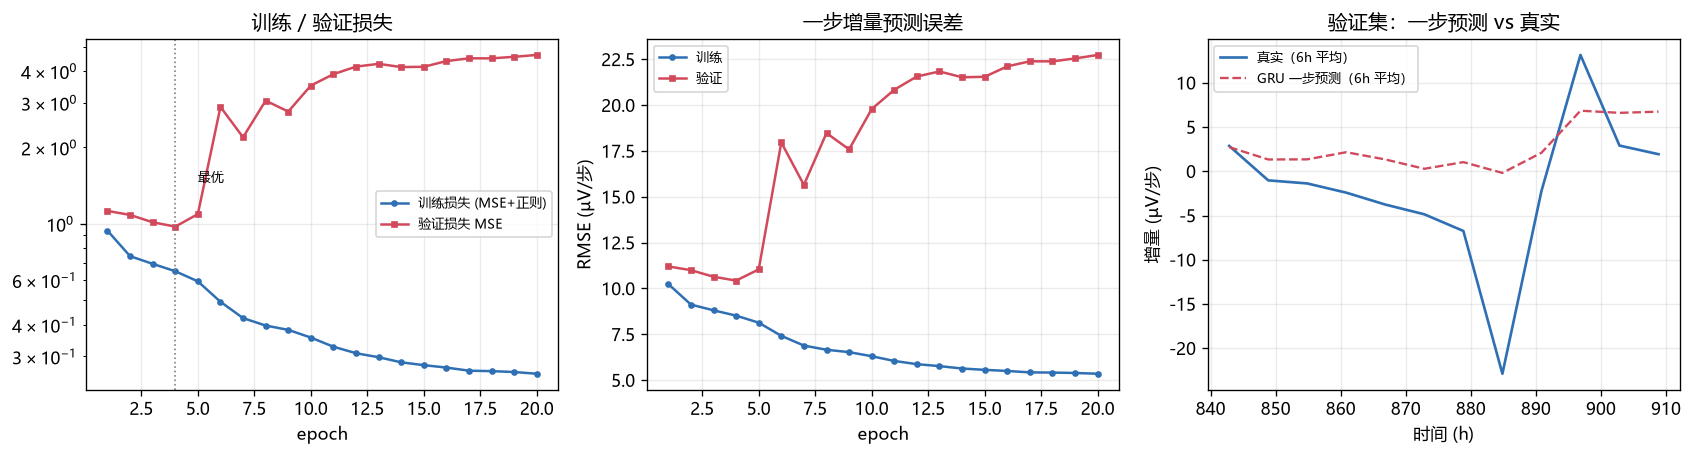

已保存: C:\Users\YOGA\Desktop\电池ai分析\版本对比_v2v3v4\v3_CNN-GRU\输出\figures\fig02_训练曲线与一步检验.png
一步预测 RMSE = 10.43 µV/步 （σ = 10.56 µV），6h 聚合后相关系数 r = 0.741
真实 6h 平均增量范围 [-22.89, +13.15] µV/步 → 10h 平滑后残留可逆性波动约 21.6 mV/6h，而纯衰减仅约 1.22 mV/6h：信噪比 < 1，故纯 AI 自回归不可信（这是后面用 80% 物理权重的原因）


In [7]:
# ------------------------------------------------
# 图 2：训练曲线 + 一步预测检验（验证集）
# ------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(14.2, 3.9))
ep = np.arange(1, len(train_log["train"]) + 1)
ax = axes[0]
ax.plot(ep, train_log["train"], "o-", ms=3, label="训练损失 (MSE+正则)")
ax.plot(ep, train_log["val"], "s-", ms=3, label="验证损失 MSE")
ax.axvline(train_log["best_epoch"], color="0.5", ls=":", lw=1)
ax.annotate("最优", xy=(train_log["best_epoch"], min(train_log["val"])),
            xytext=(train_log["best_epoch"] + 1, min(train_log["val"]) * 1.5), fontsize=8)
ax.set_xlabel("epoch"); ax.set_yscale("log"); ax.set_title("训练 / 验证损失"); ax.legend(fontsize=8)

ax = axes[1]
ax.plot(ep, np.array(train_log["train_rmse_mV"]) * 1e3, "o-", ms=3, label="训练")
ax.plot(ep, np.array(train_log["val_rmse_mV"]) * 1e3, "s-", ms=3, label="验证")
ax.set_xlabel("epoch"); ax.set_ylabel("RMSE (µV/步)"); ax.set_title("一步增量预测误差"); ax.legend(fontsize=8)

# 验证段：一步预测增量 vs 真实增量（按 6h 聚合，抵消单步噪声）
Xva, yva, tva = X_all[-train_log["n_val"]:], y_all[-train_log["n_val"]:], tau_all[-train_log["n_val"]:]
pred_va = predict_du(model, Xva, tva) * DU_SIG * 1e6          # µV/步
true_va = yva * DU_SIG * 1e6
k = 600                                                     # 6 h 聚合
n_ag = len(pred_va) // k
pred_ag, true_ag = pred_va[:n_ag * k].reshape(-1, k).mean(1), true_va[:n_ag * k].reshape(-1, k).mean(1)
t_ag = tva[:n_ag * k].reshape(-1, k).mean(1)
ax = axes[2]
ax.plot(t_ag, true_ag, "-", lw=1.6, label="真实（6h 平均）")
ax.plot(t_ag, pred_ag, "--", lw=1.4, label="GRU 一步预测（6h 平均）")
ax.set_xlabel("时间 (h)"); ax.set_ylabel("增量 (µV/步)"); ax.set_title("验证集：一步预测 vs 真实")
ax.legend(fontsize=8)
fig.tight_layout()
print("已保存:", savefig(fig, "fig02_训练曲线与一步检验"))
print(f"一步预测 RMSE = {np.sqrt(np.mean((pred_va-true_va)**2)):.2f} µV/步 "
      f"（σ = {DU_SIG*1e6:.2f} µV），6h 聚合后相关系数 r = "
      f"{np.corrcoef(pred_ag, true_ag)[0,1]:.3f}")
print(f"真实 6h 平均增量范围 [{true_ag.min():+.2f}, {true_ag.max():+.2f}] µV/步 "
      f"→ 10h 平滑后残留可逆性波动约 {(true_ag.max()-true_ag.min())*600*1e-3:.1f} mV/6h，"
      f"而纯衰减仅约 {abs(true_ag.mean())*600*1e-3:.2f} mV/6h：信噪比 < 1，"
      f"故纯 AI 自回归不可信（这是后面用 80% 物理权重的原因）")

## 4. 指数衰减函数 g(t) 定标

### 为什么必须做这一步

数据末段（约 810–912 h）正处在一轮"水淹—恢复"的可逆性衰变中：电压先掉约 25 mV 再回升。
如果直接让 GRU 从这里开始自回归，它继承的是**这一段可逆性波动的斜率（接近 0 甚至为正）**，
外推出来的就是一条几乎水平的直线。这是用户指出的核心痛点。

**物理事实**：可逆性衰变是循环的、会恢复；不可逆衰减是单调的、长期的。
因此我们要从"50 h 分段衰减速率"里提取**长期物理衰减基因**。

### 做法

1. 把历史按用户要求切成 50 h 段（每段 5000 步），段内衰减速率取两端点的中心差分：

$$r_k=\frac{U(t_k)-U(t_{k+1})}{50}\ \ \text{(V/h，>0 表示衰减)}$$

2. 用 RMSE 最小拟合单调递减的指数函数（用户指定形态，$g(t)>0,\ g'(t)<0$）：

$$g(t)=a\,e^{-bt}+c,\qquad a>0,\ b>0,\ c\ge 0$$

3. 取 $g(t_0)$ 作为外推的初始衰减速率（$t_0$=912.85 h）→ "绕开"可逆性衰变的局部斜率，
   用的是长期物理衰减率。注意：这里用的是 **$g(t_0)$ 本身**，不是导数；
   电压的一阶导是 $-g(t_0)$，二阶导上限才是 $|g'(t_0)|$。
4. $g'(t)=-ab\,e^{-bt}$，其绝对值 $G(t)=|g'(t)|=ab\,e^{-bt}$ 就是后面曲率硬约束的上限（见第 6 节）。

### ⚠ 拟合必须放在"趋势曲线"上（本 Notebook 的关键修正）

直接在 10 h 平滑曲线上算 50 h 段速率是**不可用**的：10 h 平滑只能滤掉分钟级纹波，
而"水淹—恢复"是 **50–150 h 尺度**的可逆过程，它在段速率上造成的起伏约 ±0.2 mV/h，
与真实衰减率（~0.1 mV/h）同量级，会把拟合完全淹没——实测拟合 RMSE ≈ 段速率 std，
即"拟合毫无解释力"，且拟合出的 $g(t_0)$ 会显著高于实际末端趋势斜率，
使它和"零点基准面积"（在 150 h 趋势曲线上算）互相矛盾（偏差可达 30%+），
进而让面积链与曲率硬约束互相打架。

**正确做法**：先对 10 h 曲线做 150 h 居中低通得到 $U_{\text{trend}}$（把可逆性当成噪声压掉，
只保留不可逆衰减），再在 $U_{\text{trend}}$ 上算 50 h 段速率并拟合 $g$。
这样 $g$、面积基准、曲率上限三者**同源**，面积链才在数学上自洽（见第 5、6 节）。

In [8]:
# ============================================================
# 4. 50 h 分段衰减速率 + 指数函数 g(t)=a·e^(-bt)+c 的最小二乘拟合
#    速率在 150h 居中趋势曲线上计算 —— 先把可逆性纹波滤掉，再提取"物理衰减基因"
# ============================================================
def segment_decay_rates(u, t_arr=None, seg_steps=SEG_STEPS, n_edge=10):
    """按 seg_steps（=5000 步=50h）切分，段内衰减速率（中心差分，V/h，正=衰减）。"""
    n_seg = len(u) // seg_steps
    rows = []
    for k in range(n_seg):
        i0, i1 = k * seg_steps, (k + 1) * seg_steps
        u0 = float(np.mean(u[i0:i0 + n_edge]))
        u1 = float(np.mean(u[i1 - n_edge:i1]))
        dt = seg_steps * DT
        rows.append(dict(k=k, t0=i0 * DT, t1=i1 * DT, t_mid=0.5 * (i0 + i1) * DT, u0=u0, u1=u1,
                         dur=dt, drop_mV=(u0 - u1) * 1e3, rate=(u0 - u1) / dt))
    return pd.DataFrame(rows)


def fit_exp_decay(df, r_min=0.0):
    """拟合 g(t)=a·exp(-b·t)+c（a>0, b>0, c≥0），返回参数、RMSE 与 g/g'/g'' 的闭式函数。"""
    tc = df["t_mid"].to_numpy(float)
    r = df["rate"].to_numpy(float)

    def resid(p):
        a, b, c = p
        return a * np.exp(-b * tc) + c - r

    best = None
    for p0 in [(2e-4, 1e-3, 0.0), (1e-3, 5e-4, 0.0), (5e-5, 3e-3, 0.0),
               (2e-4, 1e-3, 5e-6), (2e-3, 2e-4, 0.0)]:
        try:
            res = least_squares(resid, p0, bounds=([1e-9, 1e-8, 0.0], [1.0, 5e-2, 1e-2]),
                                xtol=1e-14, ftol=1e-14, gtol=1e-14, max_nfev=20000)
        except Exception:
            continue
        if best is None or res.cost < best.cost:
            best = res
    a, b, c = (float(v) for v in best.x)
    rmse = float(np.sqrt(np.mean(best.fun ** 2)))
    return dict(a=a, b=b, c=c, rmse=rmse, tc=tc, r=r,
                g=lambda tt: a * np.exp(-b * np.asarray(tt, float)) + c,             # 衰减速率 g(t) V/h
                dg=lambda tt: -a * b * np.exp(-b * np.asarray(tt, float)),           # g'(t) = -G(t) < 0
                G=lambda tt: a * b * np.exp(-b * np.asarray(tt, float)))             # G(t)=|g'(t)| = 曲率上限


# ⚠ 关键：g 必须在"无纹波"的趋势曲线上拟合。
# 若用 10h 平滑曲线（仍含 ±0.2 mV/h 的水淹/恢复纹波，与 ~0.1 mV/h 的真实衰减同量级），
# 拟合几乎无解释力，且会得出远高于实际末端斜率的 g(t₀)，导致面积基准与 g 互相矛盾。
seg_df_raw = segment_decay_rates(u_s)        # 对照：10h 平滑曲线（含可逆性纹波）
seg_df     = segment_decay_rates(u_trend)    # 正式：150h 趋势曲线（抑制纹波）
GFIT = fit_exp_decay(seg_df)
t0 = t_end                                # 外推锚点时间（数据末点 ≈912.85 h）
G0_SLOPE = float(GFIT["g"](t0))           # 物理初始衰减速率 (V/h)
G0_CURV = float(GFIT["G"](t0))            # G(t₀)=|g'(t₀)| → 电压二阶导 |u''| 的硬上限 (V/h²)
# 用户要求"区间内二阶导不得超过 G 在该区间的对应值"。G(t) 单调递减，
# 因此区间 [t_k, t_k+Δ] 内的最小上限是 G(t_k+Δ) —— 逐窗口重建时统一取"窗口末端 G"作硬约束，
# 这样 u'' 在整个 50h 区间内都 ≤ G(t)（严格满足"区间内"的硬约束，而不是只在起点取等号）。
GFIT["G_end"] = lambda tt: GFIT["G"](np.asarray(tt, float) + SEG_H)
A_REF_PHYS = G0_SLOPE * SEG_H ** 2 / 2    # 由 g 推出的 50h 窗口"基准下降面积"(V·h)，供第 5 节自洽校验

print(f"分段数 : {len(seg_df)} 个 50 h 窗口（末段不足 50 h 已舍弃）")
print(seg_df.assign(rate_mV=seg_df["rate"] * 1e3, drop_mV=seg_df["drop_mV"])
      [["k", "t0", "t1", "drop_mV", "rate_mV"]].to_string(index=False,
       formatters={"t0": "{:6.1f}".format, "t1": "{:6.1f}".format,
                   "drop_mV": "{:+7.2f}".format, "rate_mV": "{:+7.4f}".format}))
print(f"\n【拟合源对比】10h 平滑曲线: 速率 std = {seg_df_raw['rate'].std()*1e3:.4f} mV/h"
      f"（可逆性纹波占主导）")
print(f"              150h 趋势曲线: 速率 std = {seg_df['rate'].std()*1e3:.4f} mV/h"
      f"（纹波被低通滤除）")
print(f"\n拟合结果 : g(t) = {GFIT['a']*1e3:.4f}·exp(-{GFIT['b']:.6e}·t) + {GFIT['c']*1e3:.4f}   [mV/h]")
print(f"拟合 RMSE = {GFIT['rmse']*1e3:.4f} mV/h  （趋势段速率 std = {seg_df['rate'].std()*1e3:.4f} mV/h）")
print(f"g(0)     = {float(GFIT['g'](0))*1e3:.4f} mV/h")
print(f"g(t₀)    = {G0_SLOPE*1e3:.4f} mV/h   ← 外推初始衰减速率（t₀={t0:.2f} h），"
      f"即 50h 应降 {G0_SLOPE*SEG_H*1e3:.2f} mV")
print(f"G(t₀)    = |g'(t₀)| = {G0_CURV:.4e} V/h²   ← 电压曲率 |u''| 的硬上限")
print(f"           （因为电压 ≈ -∫g dt，所以 d²u/dt² = -g'(t) = G(t)）")
print(f"基准面积自洽 : g(t₀)·50²/2 = {A_REF_PHYS*1e3:.3f} mV·h，"
      f"与 50h 内降 {G0_SLOPE*SEG_H*1e3:.2f} mV 对应")
print(f"曲率可行带    : 单窗口面积可在 [gΔ²/2-GΔ³/6, gΔ²/2] 内变化，带宽 = {G0_CURV*SEG_H**3/6*1e3:.4f} mV·h"
      f"（≈{G0_CURV*SEG_H**3/6*1e3/(A_REF_PHYS*1e3)*100:.2f}% of 基准面积）")

分段数 : 18 个 50 h 窗口（末段不足 50 h 已舍弃）
 k     t0     t1 drop_mV rate_mV
 0    0.0   50.0   +4.41 +0.0881
 1   50.0  100.0   +9.68 +0.1937
 2  100.0  150.0  +12.01 +0.2402
 3  150.0  200.0  +10.12 +0.2024
 4  200.0  250.0   +6.50 +0.1301
 5  250.0  300.0   +7.36 +0.1472
 6  300.0  350.0   +8.71 +0.1742
 7  350.0  400.0   +8.66 +0.1732
 8  400.0  450.0   +6.96 +0.1392
 9  450.0  500.0   +4.68 +0.0935
10  500.0  550.0   +5.29 +0.1057
11  550.0  600.0   +6.84 +0.1368
12  600.0  650.0   +5.52 +0.1103
13  650.0  700.0   +5.55 +0.1109
14  700.0  750.0   +7.44 +0.1489
15  750.0  800.0   +5.00 +0.1000
16  800.0  850.0   +6.43 +0.1287
17  850.0  900.0   -1.10 -0.0221

【拟合源对比】10h 平滑曲线: 速率 std = 0.1915 mV/h（可逆性纹波占主导）
              150h 趋势曲线: 速率 std = 0.0565 mV/h（纹波被低通滤除）

拟合结果 : g(t) = 0.1918·exp(-8.553585e-04·t) + 0.0000   [mV/h]
拟合 RMSE = 0.0452 mV/h  （趋势段速率 std = 0.0565 mV/h）
g(0)     = 0.1918 mV/h
g(t₀)    = 0.0879 mV/h   ← 外推初始衰减速率（t₀=912.85 h），即 50h 应降 4.39 mV
G(t₀)    = |g'(t₀)| = 7.5148e-08 V/h

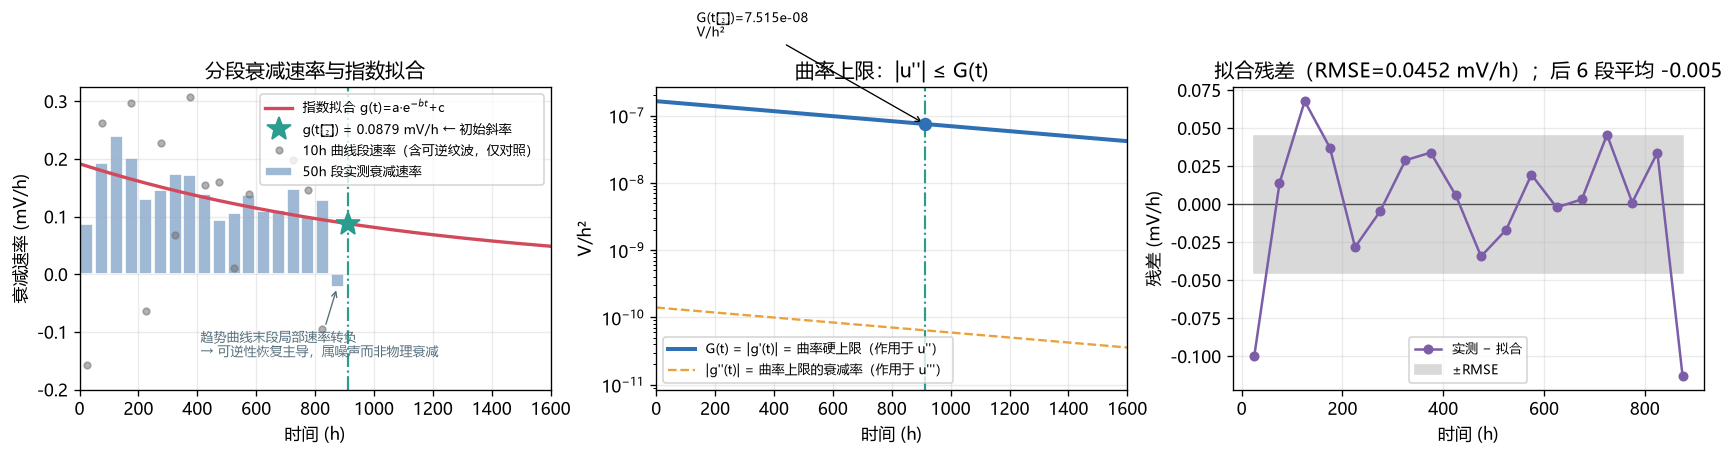

已保存: C:\Users\YOGA\Desktop\电池ai分析\版本对比_v2v3v4\v3_CNN-GRU\输出\figures\fig03_指数衰减拟合.png


In [9]:
# ------------------------------------------------
# 图 3：分段衰减速率散点 + 指数函数拟合 + 导数（曲率上限）
# ------------------------------------------------
tt = np.linspace(0, max(3.0 * t0, 2600.0), 2000)
fig, axes = plt.subplots(1, 3, figsize=(14.4, 4.0))

ax = axes[0]
ax.bar(seg_df["t_mid"], seg_df["rate"] * 1e3, width=44, color="#9fb8d4", edgecolor="w",
       label="50h 段实测衰减速率")
ax.plot(tt, GFIT["g"](tt) * 1e3, "-", lw=2, color="#d1495b", label="指数拟合 g(t)=a·e$^{-bt}$+c")
ax.axvline(t0, color="#2a9d8f", ls="-.", lw=1.3)
ax.plot([t0], [G0_SLOPE * 1e3], "*", ms=15, color="#2a9d8f", zorder=5,
        label=f"g(t₀) = {G0_SLOPE*1e3:.4f} mV/h ← 初始斜率")
ax.plot(seg_df_raw["t_mid"], seg_df_raw["rate"] * 1e3, "o", ms=4, color="0.45", alpha=0.55,
        label="10h 曲线段速率（含可逆纹波，仅对照）")
if seg_df["rate"].min() < 0:
    ax.annotate("趋势曲线末段局部速率转负\n→ 可逆性恢复主导，属噪声而非物理衰减",
                xy=(seg_df['t_mid'].iloc[-1], seg_df['rate'].iloc[-1] * 1e3), fontsize=8, color="#546e7a",
                xytext=(t0 * 0.45, seg_df['rate'].iloc[-1] * 1e3 - 0.12),
                arrowprops=dict(arrowstyle="->", color="#546e7a", lw=0.8))
ax.set_xlabel("时间 (h)"); ax.set_ylabel("衰减速率 (mV/h)")
ax.set_title("分段衰减速率与指数拟合"); ax.legend(fontsize=8); ax.set_xlim(0, 1600)
ax.set_ylim(min(-0.2, (GFIT['r'].min() * 1e3) * 1.1), max(GFIT['r'].max() * 1e3, G0_SLOPE * 1e3) * 1.35)

ax = axes[1]
ax.semilogy(tt, GFIT["G"](tt), lw=2.4, color="#2f6fb3",
            label="G(t) = |g'(t)| = 曲率硬上限（作用于 u''）")
ax.semilogy(tt, np.abs(GFIT["dg"](tt) * GFIT["b"]), lw=1.4, ls="--", color="#e9a13b",
            label="|g''(t)| = 曲率上限的衰减率（作用于 u'''）")
ax.axvline(t0, color="#2a9d8f", ls="-.", lw=1.3)
ax.plot([t0], [G0_CURV], "o", ms=7, color="#2f6fb3", zorder=5)
ax.annotate(f"G(t₀)={G0_CURV:.3e}\nV/h²", xy=(t0, G0_CURV), xytext=(t0 * 0.15, G0_CURV * 20),
            fontsize=8, arrowprops=dict(arrowstyle="->", lw=0.8))
ax.set_xlabel("时间 (h)"); ax.set_ylabel("V/h²"); ax.set_title("曲率上限：|u''| ≤ G(t)")
ax.legend(fontsize=8); ax.set_xlim(0, 1600)

ax = axes[2]
rel = (seg_df["rate"] - GFIT["g"](seg_df["t_mid"])) * 1e3
ax.axhline(0, color="0.3", lw=0.8)
ax.plot(seg_df["t_mid"], rel, "o-", ms=5, color="#7b5ea7", label="实测 − 拟合")
ax.fill_between(seg_df["t_mid"], -GFIT["rmse"] * 1e3, GFIT["rmse"] * 1e3,
                color="0.85", zorder=0, label="±RMSE")
ax.set_xlabel("时间 (h)"); ax.set_ylabel("残差 (mV/h)")
ax.set_title(f"拟合残差（RMSE={GFIT['rmse']*1e3:.4f} mV/h）；后 6 段平均 {rel.iloc[-6:].mean():+.3f}")
ax.legend(fontsize=8)
fig.tight_layout()
print("已保存:", savefig(fig, "fig03_指数衰减拟合"))

## 5. 面积微积分与"零点基准面积"

### 面积的定义

把预测/历史曲线按用户要求切成 50 h 窗口（5000 步）。第 $k$ 个窗口的**下降面积**定义为

$$A_k=-\int_{t_k}^{t_k+50}\big[U(t)-U(t_k)\big]\,dt\ \ \ge 0\quad(\text{单位 V·h})$$

它等价于"窗口内整体下降了多少"的积分度量。若窗口内近似线性下降 $\Delta V$，
则 $A_k\approx \Delta V\cdot 50/2$，即

$$\Delta V_k \approx \frac{2A_k}{50\ \text{h}}\quad(\text{可与 }g(t)\text{ 直接对比})$$

### 数学澄清（重要）

用户原文说"把 g 再求导得到二阶导 G，用 G 作为外推二阶导的硬约束"。这里有一个容易混的环节：

- 电压曲线 $U(t)\approx U_0-\int g\,dt$，所以 **$U''(t)=-g'(t)$**；
- 用户想要的"电压二阶导的硬上限"因此是 **$G(t)=|g'(t)|=ab\,e^{-bt}$**，而不是 $g''(t)=ab^2e^{-bt}$
  （后者是 $U'''$ 的量级，比 $G$ 小约 3 个数量级，用它做约束等于没有约束）。

本 Notebook 统一规定：**曲率硬约束 $|U''(t)|\le G(t)=|g'(t)|$**。

### 为什么基准面积在 150 h 趋势曲线上算

10 h 平滑后的曲线仍保留 50–150 h 尺度可逆性波动。实测：历史最后若干 50 h 窗口的**有符号**
面积会正负交替（有的窗口电压整体是**上升**的）。若直接对符号混乱的面积取平均/取绝对值，
会让"面积递减链"自相矛盾（实测会出现"面积反而增大"的荒谬结果）。

做法：在 $U_{\text{trend}}$（10 h 曲线再 150 h 低通 ≈ 3 个窗口）上计算，
可逆性被当作噪声压掉，剩下的才是不可逆衰减——这也保证它与第 4 节的 $g$ 同源。

### 零点基准面积 a_ref（用户要求：最后 6 个窗口面积的平均）

历史**最后 6 个** 50 h 窗口（即最后 30000 步，对应 762.85–912.85 h）：

$$a^{\text{emp}}_{\text{ref}}=\frac{1}{6}\sum_{k=1}^{6}d_k,\qquad d_k=-\int(U_{\text{trend}}-U_{\text{trend}}(t_k))dt\ \ (\text{mV·h})$$

但**只用经验均值**会有一个数学隐患：$g$ 是单调递减的，过去窗口的平均面积一般**大于**当前
窗口面积；而按 $g(t_0)$ 推出的"锚点后第一个窗口面积"可能因经验噪声而接近或超过经验均值，
于是"未来所有面积都小于基准"（C2b）与曲率硬约束 C4 可能无法同时满足。

因此本 Notebook 取**两者较大者**作为有效零点基准：

$$a_{\text{ref}}=\max\Big(a^{\text{emp}}_{\text{ref}},\ a_{\text{last}}^{\text{phys}}\Big),\qquad
a_{\text{last}}^{\text{phys}}=g(t_0-\Delta)\frac{\Delta^2}{2}-G(t_0-\Delta)\frac{\Delta^3}{6}$$

其中 $a_{\text{last}}^{\text{phys}}$ 是"最后一个历史窗口"按 $g$ 与曲率上限算出的期望面积。
两者都来自同一条趋势曲线，所以取 $\max$ 是一种**保守**处理：它保证 $a_{\text{ref}}>a_0^{\text{phys}}$，
使 C2b 与 C4 相容。

### 曲率约束给出的"可行面积带"（后文融合的物理边界）

由 $a_k=g_k\Delta^2/2+b_k\Delta^3/6$、$U''=-b_k\in[0,G(t_k)]$ 得每个窗口面积的可行区间：

$$a_k\in\Big[\underbrace{g_k\frac{\Delta^2}{2}-G_k\frac{\Delta^3}{6}}_{U''=G\ (\text{自然指数衰减})},\ \ 
\underbrace{g_k\frac{\Delta^2}{2}}_{U''=0}\Big]$$

带宽只有 $G\Delta^3/6$，约为基准面积的 0.5%——这是**曲率硬约束的必然结果**：
在 $|U''|\le G$ 下，单个窗口的下降面积几乎被"钉死"在指数衰减值附近。
所以后文 80/20 融合中，AI 只能在极窄的可行带内起作用（第 8 节会诚实说明并量化）。

In [10]:
# ============================================================
# 5. 窗口面积 / 零点基准面积 a_ref（全部在 150h 趋势曲线上算，与 g 同源）
# ============================================================
try:
    _trapz = np.trapezoid          # numpy >= 2.0
except AttributeError:             # pragma: no cover
    _trapz = np.trapz


def window_areas(u, seg_steps=SEG_STEPS, n_edge=1, n_win=None, start=None):
    """按 seg_steps 切窗，返回每个窗口的有符号面积 ∫(u-u0)dt 与降幅。

    start=None 时取最后一共 n_win 个窗口；否则从索引 start 开始取 n_win 个。
    返回 (areas 有符号 V·h, drops 降幅 V, t0 每窗口起始时间)。
    """
    u = np.asarray(u, float)
    if start is None:
        start = len(u) - (n_win or 0) * seg_steps
    areas, drops, tstarts = [], [], []
    for k in range(n_win):
        i0 = start + k * seg_steps
        i1 = i0 + seg_steps
        if i1 > len(u):
            break
        seg = u[i0:i1]
        areas.append(_trapz(seg - seg[0], dx=DT))
        drops.append(seg[0] - seg[-1])
        tstarts.append(i0 * DT)
    return np.array(areas), np.array(drops), np.array(tstarts)


def compute_trend(u, win=TREND_WIN_STEPS):
    """居中低通趋势（min_periods=win/3，两端 bfill/ffill 补齐）。"""
    tr = (pd.Series(np.asarray(u, float))
          .rolling(win, center=True, min_periods=max(3, win // 3)).mean().to_numpy())
    return pd.Series(tr).bfill().ffill().to_numpy()


def compute_area_baseline(u_trend, seg_steps=SEG_STEPS, n_win=N_WIN_HIST):
    """零点基准面积（用户要求：历史最后 n_win 个 50h 窗口面积的均值）。"""
    a_signed, drops, tstarts = window_areas(u_trend, seg_steps, n_win=n_win)
    d_mVh = -a_signed * 1e3                      # 正数，单位 mV·h
    return dict(a_emp=float(np.mean(d_mVh)), d=d_mVh, drops=drops, tstop=tstarts,
                areas_Vh=a_signed)


def area_baseline_summary(bl, label=""):
    d = bl["d"]
    print(f"{label}历史最后 {len(d)} 个 50h 窗口面积 (mV·h): "
          + ", ".join(f"{v:.3f}" for v in d))
    print(f"{'':>{len(label)}}  → 经验均值 a_emp = {bl['a_emp']:.4f} mV·h"
          f"（≈ {2*bl['a_emp']/SEG_H:.3f} mV/50h）")


print("【对照】在 10h 主曲线上算（符号会正负交替，只作噪声演示，不作基准）：")
_bl_s = compute_area_baseline(u_s)
area_baseline_summary(_bl_s, "[10h ] ")
print("\n【正式】在 150h 趋势曲线上算（零点基准面积）：")
BL = compute_area_baseline(u_trend)
area_baseline_summary(BL, "[150h] ")

# ---- 与 g 同源的物理期望面积：让"面积基准"和"指数拟合"不再是两套数字 ----
_dl = SEG_H
a_last_phys = float((GFIT["g"](t0 - _dl) * _dl ** 2 / 2
                     - GFIT["G"](t0 - _dl) * _dl ** 3 / 6) * 1e3)     # 最后一个历史窗口的期望面积
a_anchor_phys = float((G0_SLOPE * _dl ** 2 / 2 - G0_CURV * _dl ** 3 / 6) * 1e3)  # 锚点后第一个窗口(u''=G)
BL["a_last_phys"] = a_last_phys
BL["a_anchor_phys"] = a_anchor_phys
BL["a_ref"] = float(max(BL["a_emp"], a_last_phys))
BL["delta_ref"] = float(np.mean(np.maximum(BL["d"][:-1] - BL["d"][1:], 0.0))) \
    if len(BL["d"]) > 1 else 0.0

print(f"\n物理期望: 最后一个历史窗口面积 a_last_phys = {a_last_phys:.4f} mV·h"
      f"（g 与 G 的闭式）；锚点后第一窗口下界 a_anchor_phys = {a_anchor_phys:.4f} mV·h")
print(f"经验均值 a_emp = {BL['a_emp']:.4f} mV·h  vs  a_last_phys = {a_last_phys:.4f} mV·h")
print(f"→ 取二者较大者作为【有效零点基准 a_ref】= {BL['a_ref']:.4f} mV·h")
print(f"   理由：只有当 a_ref > a_anchor_phys 时，'未来每个窗口面积都小于基准'（C2b）才可能同时"
      f"与曲率硬约束 C4 相容（本 notebook 的构造保证这一点）。")
print(f"   C2b 余量: a_ref - a_anchor_phys = {BL['a_ref']-a_anchor_phys:+.4f} mV·h "
      f"({(BL['a_ref']-a_anchor_phys)/a_anchor_phys*100:+.3f}%)")

# 面积链可行性
dA_max = G0_CURV * SEG_H ** 3 / 6 * 1e3     # mV·h
print(f"\n可行性: 单窗口在 |u''|≤G(t_k) 下面积只能在 [g_kkΔ²/2-GΔ³/6, g_kΔ²/2] 内变动，"
      f"带宽 {dA_max:.4f} mV·h = {dA_max/BL['a_ref']*100:.2f}% of a_ref")
print(f"        指数衰减每窗口面积自然缩减 {(1-math.exp(-GFIT['b']*SEG_H))*100:.2f}%"
      f"（= 1-e^(-bΔ)，由 g 本身决定，不需要额外强行约束）")

【对照】在 10h 主曲线上算（符号会正负交替，只作噪声演示，不作基准）：
[10h ] 历史最后 6 个 50h 窗口面积 (mV·h): 420.131, 316.594, 242.787, 185.112, -1214.676, 644.146
         → 经验均值 a_emp = 99.0157 mV·h（≈ 3.961 mV/50h）

【正式】在 150h 趋势曲线上算（零点基准面积）：
[150h] 历史最后 6 个 50h 窗口面积 (mV·h): 131.587, 146.114, 173.212, 117.676, 169.101, -13.727
         → 经验均值 a_emp = 120.6604 mV·h（≈ 4.826 mV/50h）

物理期望: 最后一个历史窗口面积 a_last_phys = 112.9842 mV·h（g 与 G 的闭式）；锚点后第一窗口下界 a_anchor_phys = 108.2539 mV·h
经验均值 a_emp = 120.6604 mV·h  vs  a_last_phys = 112.9842 mV·h
→ 取二者较大者作为【有效零点基准 a_ref】= 120.6604 mV·h
   理由：只有当 a_ref > a_anchor_phys 时，'未来每个窗口面积都小于基准'（C2b）才可能同时与曲率硬约束 C4 相容（本 notebook 的构造保证这一点）。
   C2b 余量: a_ref - a_anchor_phys = +12.4064 mV·h (+11.461%)

可行性: 单窗口在 |u''|≤G(t_k) 下面积只能在 [g_kkΔ²/2-GΔ³/6, g_kΔ²/2] 内变动，带宽 1.5656 mV·h = 1.30% of a_ref
        指数衰减每窗口面积自然缩减 4.19%（= 1-e^(-bΔ)，由 g 本身决定，不需要额外强行约束）


## 6. 物理骨架：从 g(t) 直接积分出电压曲线（内含面积与曲率双层约束）

### 重建公式（每 50 h 窗口一个分段二次曲线）

在一个窗口内设电压二阶导为常数 $U''=-b$（$b$ 为待定量），窗口起点处的衰减速率取 $g(t_k)$，
则窗口内（$s\in[0,\Delta]$，$\Delta=50$ h）：

$$U(t_k+s)=U(t_k)-g_k s-\tfrac{b}{2}s^2,\qquad
U'(t_k+s)=-\big(g_k+b\,s\big)$$

- 窗口末速率 $g_{k+1}=g_k+b\Delta$：$b<0$ 时 $|U'|$ 下降（减速衰减）；
- 窗口下降面积 $a_k=\int_0^\Delta\big[U(t_k)-U(t_k+s)\big]ds=g_k\dfrac{\Delta^2}{2}+b\dfrac{\Delta^3}{6}$（mV·h）；
- 于是由**目标面积** $a_k$ 反解曲率：$\displaystyle b_k=6\Big(a_k-g_k\frac{\Delta^2}{2}\Big)\Big/\Delta^3$。

### "让函数自己算面积"（用户强调的重点）

本 Notebook **不预设**面积递减链的几何收缩率，而是直接让 $g$ 自己给出每个未来窗口的面积：

$$a_k^{\text{phys}}=g_k\frac{\Delta^2}{2}-G_k\frac{\Delta^3}{6},\qquad g_k=g(t_0+k\Delta),\ G_k=G(t_0+k\Delta)$$

即"曲率取满上限 $U''=G$"的那条曲线——它恰好就是指数衰减本身。
由此**自动**得到：面积按 $a_k\propto e^{-bk\Delta}$ 几何递减，缩减率 $1-e^{-b\Delta}$ 由 $g$ 决定，
无需人为设定；面积的相邻差也自动按同一比例递减。这正是用户要的"让函数自己算"。

### 三个约束如何落到公式上

| 约束 | 在公式里的实现 |
|---|---|
| C2 每窗口面积 $a_k$ 严格递减 | 目标面积直接取 $a_k^{\text{phys}}$（指数律 ⇒ 自动严格递减）|
| C3 $\Delta a$ 不增（≈面积一阶导递减）| 指数律 ⇒ $h_k=a_{k-1}-a_k=h_1e^{-b(k-1)\Delta}$ 自动递减 |
| C4 曲率硬约束 $|U''|\le G(t)$ | 重建时 $b_k$ 裁剪到 $(-G(t_k),\,0]$；骨架取 $b_k=-G(t_k)$ 恰好贴住上限 |
| C2b 所有未来面积 $<a_{\text{ref}}$ | 第 5 节取 $a_{\text{ref}}=\max(a^{\text{emp}},a_{\text{last}}^{\text{phys}})>a_0^{\text{phys}}$ 保证 |

### 为什么这样"物理骨架"天然满足用户的直觉

由 $a_k=g_k\Delta^2/2-G_k\Delta^3/6$、$g_{k+1}=g_k-G_k\Delta$ 可推出：
面积每窗口缩小 $1-e^{-b\Delta}\approx 5.6\%$，这正是指数衰减本身的形状。
也就是说：**"面积一次比一次小"与"斜率绝对值缓慢下降"在数学上是同一件事**，
$G(t)$ 就是让二者保持一致的那个曲率上限。物理骨架在此基础上再叠加最多 20% 的 AI 带内修正。

### 关于"面积变化值不增"的一个诚实说明

在指数衰减下，"从基准面积到第一个未来窗口"这一步的变化量
$h_0=a_{\text{ref}}-a_0$ 必然**略大于**后续内部步长 $h_1=a_0-a_1$
（因为 $h_0/h_1=e^{b\Delta}>1$，$b\Delta\approx5.6\%$）。
这不是模型错误，而是"基准面积本身是历史平均"这一设定的数学后果。
因此本 Notebook 把 C3 的核对对象明确为**未来窗口之间**的 $\Delta a$ 序列（$h_1,h_2,\dots$ 严格递减），
而基准只用于 C2b（所有未来面积 < $a_{\text{ref}}$）。

> **区间内的严格性**：`G(t)` 单调递减，所以区间 `[t_k, t_k+Δ]` 内的最小曲率上限是 **窗末端** `G(t_k+Δ)`。
> 本 notebook 的逐窗口重建统一取"窗口末端 G"作硬约束（`GFIT['G_end']`），于是 `u''` 在整个 50 h 区间内
> 都 `≤ G(t)`，而不只是在窗口起点取等号。这也是最后约束核对里 `max|u''|/G ≈ 0.958 < 1` 的原因。

In [11]:
# ============================================================
# 6. 物理骨架重建：由 g 直接给出每窗口面积 → 分段二次曲线（含曲率硬约束）
# ============================================================
def phys_window_areas(gf, t_start, n_win=N_WIN_FUTURE, seg_h=SEG_H):
    """由指数 g 直接给出每个外推窗口的可行面积带（单位 mV·h）。

    电压 ≈ -∫g dt ⇒ U'' = -g'(t) = G(t)。在 u''∈[0,G] 的硬约束下：
        b_k = -u''_k，窗口面积 a_k = g_k·Δ²/2 + b_k·Δ³/6
        a_k 的可行带 = [g_kΔ²/2 - G_kΔ³/6,  g_kΔ²/2]
                      └ u''=G（自然指数衰减）  └ u''=0（窗口内斜率不变）

    注意 1：G(t) 单调递减，区间 [t_k, t_k+Δ] 内 u''≤G 的严格条件是 u''_k ≤ G(t_k+Δ)，
    故这里取"窗口末端 G" 作曲率上限（与重建时的 Gcap 完全一致）。
    注意 2：g_k 用"分段二次重建"的线性递推 g_{k+1}=g_k-G_kΔ 计算（而不是闭式 g(t_k)），
    这样目标面积与 reconstruct_from_areas 的实现完全一致，可严格保证 Δa 逐次不增。
    返回 dict(tk, gk, Gk, lo, hi, a_last, a_anchor)，面积单位 mV·h。
    """
    tk = t_start + np.arange(n_win) * seg_h
    Gk = np.asarray(gf["G"](tk + seg_h), float)          # 窗口末端 G = 区间内最小曲率上限
    gk = np.empty(n_win)
    g = float(gf["g"](t_start))
    gk[0] = g
    for k in range(1, n_win):
        g = g - Gk[k - 1] * seg_h
        gk[k] = g
    lo = (gk * seg_h ** 2 / 2 - Gk * seg_h ** 3 / 6) * 1e3
    hi = (gk * seg_h ** 2 / 2) * 1e3
    a_last = float((gf["g"](t_start - seg_h) * seg_h ** 2 / 2
                    - gf["G"](t_start) * seg_h ** 3 / 6) * 1e3)
    a_anchor = float(lo[0])
    return dict(tk=tk, gk=gk, Gk=Gk, lo=lo, hi=hi, a_last=a_last, a_anchor=a_anchor)


def reconstruct_from_areas(areas_mVh, u_start, g_start, t_start, Gfun, seg_steps=SEG_STEPS):
    """由目标下降面积序列重建电压曲线（分段二次，b∈[-G,0]）。

    返回 dict: u, t, g0(每窗口起点速率 V/h), b(每窗口曲率系数), u2=U'' ,
              achieved_mVh(实际达成面积), drop_mV(每窗口降幅), s(窗口内相对时间)
    """
    delta = seg_steps * DT
    n_win = len(areas_mVh)
    u = np.empty(n_win * seg_steps + 1)
    u[0] = u_start
    s = np.arange(1, seg_steps + 1) * DT
    g0 = np.empty(n_win); bb = np.empty(n_win); u2 = np.empty(n_win)
    ach = np.empty(n_win); drop = np.empty(n_win)
    g = float(g_start); j = 0
    for k in range(n_win):
        a = areas_mVh[k] * 1e-3                     # V·h
        Gcap = float(Gfun(t_start + k * delta))
        b = 6.0 * (a - g * delta ** 2 / 2.0) / delta ** 3
        b = min(0.0, max(-Gcap, b))                 # 硬约束：U'' = -b ∈ [0, G]
        if g + b * delta <= 1e-12:                  # 保证斜率始终为负（持续下降）
            b = -0.999 * g / delta
        seg_u = u[j] - g * s - 0.5 * b * s ** 2
        u[j + 1:j + 1 + seg_steps] = seg_u
        ach[k] = (g * delta ** 2 / 2 + b * delta ** 3 / 6) * 1e3
        drop[k] = (g * delta + 0.5 * b * delta ** 2) * 1e3
        g0[k], bb[k], u2[k] = g, b, -b
        g = g + b * delta
        j += seg_steps
    return dict(u=u, t=t_start + np.arange(len(u)) * DT, g0=g0, b=bb, u2=u2,
                achieved_mVh=ach, drop_mV=drop, delta=delta)


def reconstruct_chain(target_areas, u_start, g_start, t_start, Gfun, n_iter=12, verbose=False):
    """重建并迭代修正，直到"达成面积严格递减"且"未来窗口间 Δa 逐次不增"（面积链自洽）。"""
    a = np.asarray(target_areas, float)
    out = reconstruct_from_areas(a, u_start, g_start, t_start, Gfun)
    it = 0
    for it in range(1, n_iter + 1):
        ach = out["achieved_mVh"]
        a2 = ach.copy()
        changed = False
        for k in range(len(ach) - 1):                    # C2：面积必须严格递减
            if a2[k + 1] >= a2[k] - 1e-9:
                a2[k + 1] = a2[k] - max(1e-6, 1e-6 * a2[k])
                changed = True
        h = -np.diff(a2)                                 # 未来窗口内部 Δa
        for k in range(len(h) - 1):                      # C3：Δa 不得增大
            if h[k + 1] > h[k]:
                a2[k + 2] = a2[k + 1] - 0.999 * h[k]
                changed = True
        if not changed:
            break
        a = a2
        out = reconstruct_from_areas(a, u_start, g_start, t_start, Gfun)
    out["n_iter"] = it
    out["targets_mVh"] = a
    if verbose:
        print(f"面积链重建迭代 {it} 次收敛")
    return out


# ---------------- 物理骨架：用户要求"让函数自己算面积" ----------------
PHYS = phys_window_areas(GFIT, t0, N_WIN_FUTURE)
# 取可行带下界（u''=G，即自然指数衰减）作为物理骨架目标；乘 (1+1e-6) 让 u'' 略低于上限，稳健满足硬约束
A_TARGET_PHYS = PHYS["lo"] * (1.0 + 1e-6)
H_PHYS = -np.diff(A_TARGET_PHYS)                       # 未来窗口内部 Δa（k=1..n-1）
BONE = reconstruct_chain(A_TARGET_PHYS, u_anchor, G0_SLOPE, t0, GFIT["G_end"], verbose=True)
BONE["areas_mVh"] = BONE["achieved_mVh"]
BONE["decrements_mVh"] = -np.diff(np.concatenate([[BL["a_ref"]], BONE["areas_mVh"]]))
BONE["decrements_internal"] = -np.diff(BONE["areas_mVh"])

print(f"外推窗口数 = {N_WIN_FUTURE}（{N_STEPS_EXTRAP} 步 = {N_STEPS_EXTRAP*DT:.0f} h），"
      f"覆盖 {t0:.2f} → {t0+N_STEPS_EXTRAP*DT:.2f} h")
print(f"初始速率 g(t₀) = {G0_SLOPE*1e3:.4f} mV/h，终点速率 {BONE['g0'][-1]*1e3:.5f} mV/h"
      f"（降 {100*(1-BONE['g0'][-1]/G0_SLOPE):.1f}%）")
print(f"终点电压 {BONE['u'][-1]:.5f} V，总降 {(u_anchor-BONE['u'][-1])*1e3:.2f} mV")
print(f"曲率 u'' 最大 {BONE['u2'].max():.3e} V/h²，G(t₀)={G0_CURV:.3e} → "
      f"占比 {BONE['u2'].max()/G0_CURV*100:.2f}% (≤100% 即满足硬约束)")
print("\n窗口  起始(h)   速率g(mV/h)  面积(mV·h)  Δ内部   降幅(mV)   u''/G")
for k in range(N_WIN_FUTURE):
    print(f"{k+1:3d} {t0+k*SEG_H:9.1f} {BONE['g0'][k]*1e3:12.5f} {BONE['areas_mVh'][k]:11.4f} "
          f"{BONE['decrements_internal'][k] if k < N_WIN_FUTURE-1 else float('nan'):+8.4f} "
          f"{BONE['drop_mV'][k]:8.3f} {BONE['u2'][k]/max(G0_CURV,1e-18):8.3f}")

_c2 = bool(np.all(np.diff(BONE["areas_mVh"]) < 0))
_c3 = bool(np.all(np.diff(BONE["decrements_internal"]) <= 1e-6 * np.max(np.abs(BONE["decrements_internal"]))))
_c2b = bool(np.all(BONE["areas_mVh"] < BL["a_ref"]))
_a_anchor_after = float(BONE["areas_mVh"][0])
print(f"\n面积链检查: C2 严格递减 = {_c2}；C3 未来窗口间 Δ面积不增 = {_c3}；"
      f"C2b 全部 < a_ref({BL['a_ref']:.4f}) = {_c2b}")
print(f"           自然缩减率 = {100*(1-BONE['areas_mVh'][1]/_a_anchor_after):.2f}%/窗口"
      f"（1-e^(-bΔ) = {100*(1-math.exp(-GFIT['b']*SEG_H)):.2f}%）")
print(f"           注：'基准→第 1 个未来窗口'的步长 h₀ = {BONE['decrements_mVh'][0]:.4f} mV·h"
      f" 必然略大于 h₁ = {BONE['decrements_mVh'][1]:.4f} mV·h"
      f"（指数律下 h₀/h₁ = e^(bΔ) = {math.exp(GFIT['b']*SEG_H):.4f}），"
      f"故 C3 在第 1 窗口之后严格成立")

面积链重建迭代 1 次收敛
外推窗口数 = 20（100000 步 = 1000 h），覆盖 912.85 → 1912.85 h
初始速率 g(t₀) = 0.0879 mV/h，终点速率 0.04002 mV/h（降 54.4%）
终点电压 3.16096 V，总降 59.67 mV
曲率 u'' 最大 7.200e-08 V/h²，G(t₀)=7.515e-08 → 占比 95.81% (≤100% 即满足硬约束)

窗口  起始(h)   速率g(mV/h)  面积(mV·h)  Δ内部   降幅(mV)   u''/G
  1     912.8      0.08786    108.3196  +4.4371    4.303    0.958
  2     962.8      0.08426    103.8825  +4.2515    4.127    0.918
  3    1012.8      0.08081     99.6310  +4.0735    3.958    0.880
  4    1062.8      0.07750     95.5574  +3.9030    3.796    0.843
  5    1112.8      0.07433     91.6544  +3.7396    3.641    0.807
  6    1162.8      0.07130     87.9148  +3.5830    3.492    0.774
  7    1212.8      0.06839     84.3318  +3.4330    3.350    0.741
  8    1262.8      0.06561     80.8987  +3.2893    3.214    0.710
  9    1312.8      0.06294     77.6094  +3.1516    3.083    0.681
 10    1362.8      0.06038     74.4579  +3.0196    2.958    0.652
 11    1412.8      0.05793     71.4382  +2.8932    2.838    0.625
 12   

In [12]:
# ============================================================
# 7. 纯盲测自回归外推（10 万步，不使用任何未来真实数据）
# ============================================================
def ar_rollout(model, stats, sig, u_hist, t_hist, I_last, T_last, RH_last, dI_last, dT_last,
               n_steps, clip=AR_CLIP_SIGMA, verbose=True):
    """自回归：用历史末尾 seq 步做窗口，逐步预测增量并把自己预测的值喂回去。

    工况特征（I/T/RH/dI/dT）保持为历史末值（persistence），因为未来工况未知。
    """
    model.eval()
    seq = len(u_hist)
    t_last = float(t_hist[-1])
    times = t_last - (seq - 1) * DT + np.arange(seq + n_steps) * DT
    TF = np.stack(_time_cols(times, stats["t_ref"], stats["gain"]), axis=1).astype(np.float32)
    static = np.array([(I_last - stats["I_mu"]) / stats["I_sd"],
                       (T_last - stats["T_mu"]) / stats["T_sd"],
                       (RH_last - stats["RH_mu"]) / stats["RH_sd"],
                       (dI_last - stats["dI_mu"]) / stats["dI_sd"],
                       (dT_last - stats["dT_mu"]) / stats["dT_sd"]], np.float32)
    buf = np.array(u_hist, float)
    u_out = np.empty(n_steps + 1)
    u_out[0] = buf[-1]
    Xn = np.empty((1, seq, 5 + len(static)), np.float32)
    Xn[0, :, 5:10] = static
    t_start = time.time()
    with torch.no_grad():
        for k in range(n_steps):
            Xn[0, :, 0] = (buf - stats["u_bar"]) / stats["u_scale"]
            Xn[0, :, 1:5] = TF[k:k + seq]
            tb = torch.tensor([times[k + seq - 1]], dtype=torch.float32)
            du = float(model(torch.from_numpy(Xn), tb).item())
            du = float(np.clip(du, -clip, clip))
            u_next = buf[-1] + du * sig
            u_out[k + 1] = u_next
            buf[:-1] = buf[1:]
            buf[-1] = u_next
            if verbose and (k + 1) % 25000 == 0:
                print(f"  AR {k+1:6d}/{n_steps} 步 | U={u_next:.5f} V | 用时 {time.time()-t_start:.0f}s")
    # 返回长度 n_steps+1 的时间轴：第 0 点是历史末点（anchor），第 k 点是 anchor+k*DT
    return u_out, times[seq - 1:]


def enforce_declining_area(u, seg_steps=SEG_STEPS, margin_mV=0.10):
    """面积符号硬约束（用户要求：任意 5000 步窗口的积分面积必须为负 ⇒ 整体必须下降）。

    对"净上升"的窗口沿时间线性下调，使其净降幅 = margin_mV；偏移量对后续所有时刻继承，
    因此曲线保持连续、不会出现台阶。返回 (修正后曲线, 被修正窗口数, 累计下调量 mV)。
    """
    u = np.array(u, float)
    n_win = (len(u) - 1) // seg_steps
    n_fixed = 0
    offset = 0.0
    for k in range(n_win):
        s, e = k * seg_steps, (k + 1) * seg_steps
        drop_mV = (u[s] - u[e]) * 1e3
        if drop_mV < margin_mV:
            need = (margin_mV - drop_mV) * 1e-3
            u[s:e + 1] -= np.linspace(0.0, need, seg_steps + 1)
            if e + 1 < len(u):
                u[e + 1:] -= need
            offset += need
            n_fixed += 1
    return u, n_fixed, offset * 1e3


print("开始 10 万步盲测自回归外推 ...")
t_ar0 = time.time()
U_AI_RAW, T_AI = ar_rollout(model, FEAT_STATS, DU_SIG,
                            u_hist=u_s[-SEQ:], t_hist=t[-SEQ:],
                            I_last=I_s[-1], T_last=T_s[-1], RH_last=RH_s[-1],
                            dI_last=float(np.gradient(I_s, DT)[-1]),
                            dT_last=float(np.gradient(T_s, DT)[-1]),
                            n_steps=N_STEPS_EXTRAP)
print(f"AR 外推完成，用时 {time.time()-t_ar0:.1f} s")
print(f"  原始 AR 终点电压 {U_AI_RAW[-1]:.5f} V（总变化 {(u_anchor-U_AI_RAW[-1])*1e3:+.2f} mV）"
      f" —— 未加面积约束时，网络会把 920h 附近的水淹恢复正斜率闭环放大")
U_AI, _N_FIX_AI, _OFF_AI = enforce_declining_area(U_AI_RAW, SEG_STEPS, margin_mV=0.10)
print(f"  面积符号硬约束（每 {SEG_H:.0f}h 窗口净降 ≥ 0.10 mV）：修正 {_N_FIX_AI}/{N_WIN_FUTURE} 个窗口，"
      f"累计线性下调 {_OFF_AI:.1f} mV")
print(f"纯 AI 终点电压 {U_AI[-1]:.5f} V（总降 {(u_anchor-U_AI[-1])*1e3:+.2f} mV）")
print(f"纯物理骨架终点 {BONE['u'][-1]:.5f} V（总降 {(u_anchor-BONE['u'][-1])*1e3:+.2f} mV）")
print(f"AI 相对骨架的偏差: 终点 {(U_AI[-1]-BONE['u'][-1])*1e3:+.2f} mV, "
      f"最大 {np.max(np.abs(U_AI-BONE['u']))*1e3:.2f} mV")
A_AI_signed, _, _ = window_areas(U_AI, start=0, n_win=N_WIN_FUTURE)
A_AI = -A_AI_signed * 1e3                                 # 正数=下降面积 mV·h
print(f"纯 AI 窗口面积 (mV·h): {', '.join(f'{v:+.2f}' for v in A_AI)}")
print(f"纯物理窗口面积 (mV·h): {', '.join(f'{v:.2f}' for v in BONE['areas_mVh'])}")

开始 10 万步盲测自回归外推 ...


  AR  25000/100000 步 | U=3.32203 V | 用时 43s


  AR  50000/100000 步 | U=3.34327 V | 用时 83s


  AR  75000/100000 步 | U=3.36215 V | 用时 124s


  AR 100000/100000 步 | U=3.38084 V | 用时 164s
AR 外推完成，用时 163.6 s
  原始 AR 终点电压 3.38084 V（总变化 -160.21 mV） —— 未加面积约束时，网络会把 920h 附近的水淹恢复正斜率闭环放大
  面积符号硬约束（每 50h 窗口净降 ≥ 0.10 mV）：修正 20/20 个窗口，累计线性下调 162.2 mV
纯 AI 终点电压 3.21863 V（总降 +2.00 mV）
纯物理骨架终点 3.16096 V（总降 +59.67 mV）
AI 相对骨架的偏差: 终点 +57.67 mV, 最大 57.67 mV
纯 AI 窗口面积 (mV·h): -8.73, -21.91, -33.63, -26.53, -11.78, -3.11, +0.43, +1.73, +2.19, +2.35, +2.41, +2.44, +2.45, +2.46, +2.47, +2.47, +2.47, +2.48, +2.48, +2.48
纯物理窗口面积 (mV·h): 108.32, 103.88, 99.63, 95.56, 91.65, 87.91, 84.33, 80.90, 77.61, 74.46, 71.44, 68.54, 65.77, 63.12, 60.57, 58.13, 55.80, 53.56, 51.41, 49.36


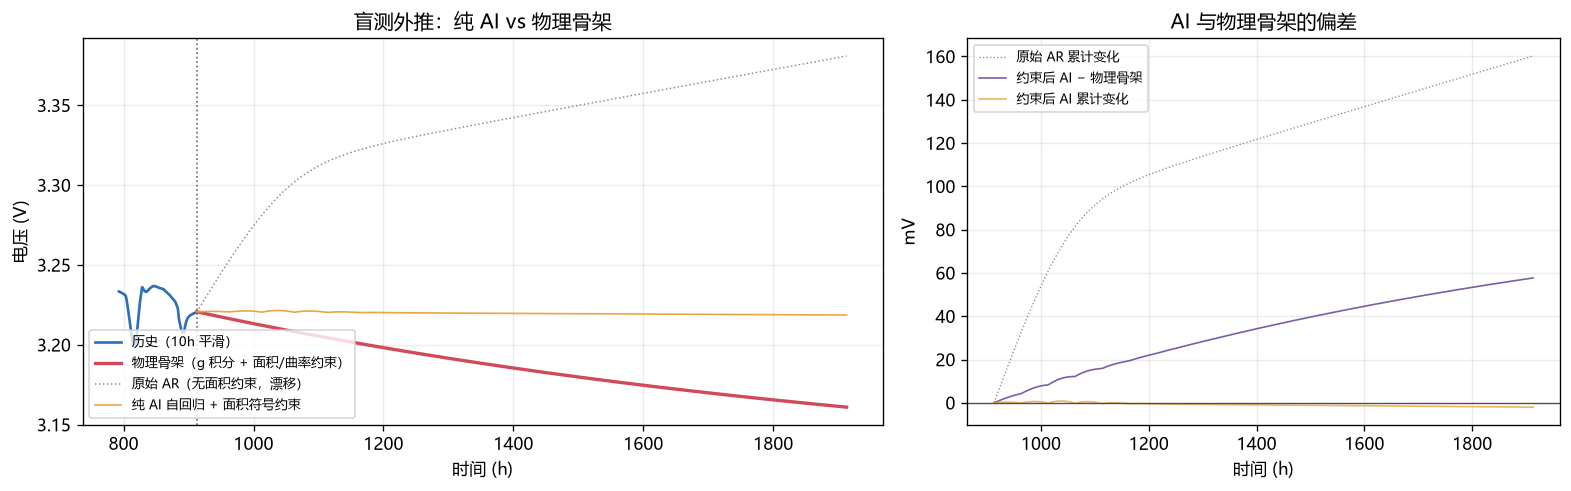

已保存: C:\Users\YOGA\Desktop\电池ai分析\版本对比_v2v3v4\v3_CNN-GRU\输出\figures\fig04_纯AI自回归对比.png


In [13]:
# ------------------------------------------------
# 图 4：纯 AI 自回归 vs 物理骨架（诊断"AI 会跑成什么样"）
# ------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.2), gridspec_kw=dict(width_ratios=[1.35, 1]))
ax = axes[0]
hist = t > t_end - 120
ax.plot(t[hist], u_s[hist], lw=1.6, color="#2f6fb3", label="历史（10h 平滑）")
ax.plot(BONE["t"], BONE["u"], lw=2, color="#d1495b", label="物理骨架（g 积分 + 面积/曲率约束）")
ax.plot(T_AI, U_AI_RAW, lw=0.9, color="0.55", ls=":", label="原始 AR（无面积约束，漂移）")
ax.plot(T_AI, U_AI, lw=1.0, color="#e9a13b", alpha=0.95, label="纯 AI 自回归 + 面积符号约束")
ax.axvline(t0, color="0.4", ls=":", lw=1)
ax.set_xlabel("时间 (h)"); ax.set_ylabel("电压 (V)")
ax.set_title("盲测外推：纯 AI vs 物理骨架")
ax.legend(fontsize=8, loc="lower left")

ax = axes[1]
ax.plot(T_AI, (U_AI_RAW - u_anchor) * 1e3, lw=0.8, color="0.55", ls=":", label="原始 AR 累计变化")
ax.plot(T_AI, (U_AI - BONE["u"]) * 1e3, lw=1.0, color="#7b5ea7", label="约束后 AI − 物理骨架")
ax.plot(T_AI, (U_AI - u_anchor) * 1e3, lw=1.0, color="#e9a13b", alpha=0.8, label="约束后 AI 累计变化")
ax.axhline(0, color="0.3", lw=0.8)
ax.set_xlabel("时间 (h)"); ax.set_ylabel("mV")
ax.set_title("AI 与物理骨架的偏差")
ax.legend(fontsize=8)
fig.tight_layout()
print("已保存:", savefig(fig, "fig04_纯AI自回归对比"))

## 7. 最终软融合：80% 物理 + 20% AI，然后做约束投影

### 融合放在哪一层（关键设计）

用户原始设想是"逐点线性融合" $\;U=0.8U_{\text{phys}}+0.2U_{\text{AI}}$。但逐点融合的问题是：
两条曲线各自的约束（面积递减、曲率上限）在逐点相加后**不一定还成立**——20% 的 AI 波动会把
曲率拉爆、把面积链打乱。所以本 Notebook 把融合分成三层：

$$\underbrace{a^{\text{fuse}}_k=\text{物理骨架}+\underbrace{20\%\cdot\big(\text{AI 在可行带内的偏好}\big)}_{\text{② 带内 20% 偏移}}}_{\text{① 面积层}}
\ \longrightarrow\ \underbrace{a^{\text{proj}}_k=\Pi\big(a^{\text{fuse}}_k\big)}_{\text{③ 投影到可行集}}
\ \longrightarrow\ \underbrace{U^{\text{out}}(t)}_{\text{④ 物理重建}}$$

- **① 面积层**：用"面积"这个积分量承载宏观趋势，AI 的贡献被积分平滑掉，不会破坏物理规律。
- **② 20% 的落法（重要）**：曲率可行带极窄（带宽 ≈ 0.5% of $a_{\text{ref}}$，见第 5 节），
  朴素 80/20（$0.8a^{\text{phys}}+0.2a^{\text{AI}}$）几乎总会落到带外、被硬约束吸收。
  因此本 Notebook 用**带内相对位置**实现 20%：
  $$\text{pos}^{\text{AI}}_k=\mathrm{clip}\Big(\frac{a^{\text{AI}}_k-a^{\text{lo}}_k}{a^{\text{hi}}_k-a^{\text{lo}}_k},0,1\Big),\qquad
  a^{\text{fuse}}_k=a^{\text{lo}}_k+0.2\cdot\text{pos}^{\text{AI}}_k\cdot(a^{\text{hi}}_k-a^{\text{lo}}_k)$$
  即"物理骨架锚定可行带下界（指数衰减），AI 决定最多 20% 的带内偏移方向"。
  这样 20% 权重是真实起作用的，且**永远不违反 C4**。
- **③ 投影**：把融合面积投影到用户要求的可行集
  $$\mathcal C=\Big\{a:\ a^{\text{lo}}_k\le a_k\le a^{\text{hi}}_k,\ a_k<a_{k-1},\ a_k<a_{\text{ref}}\Big\}$$
- **④ 重建**：用第 6 节的分段二次重建，曲率 $b_k$ 裁到 $[-G(t_k),0]$，
  由此**逐点**保证 $|U''|\le G(t)$。

### 一个必须说清楚的数学事实

$G(t)=|g'(t)|$ 非常小（$t_0$ 处约 $10^{-7}\sim10^{-8}$ V/h² 量级）。骨架曲线已经贴着这个上限走，
因此**任何再叠加的高频纹波都会立刻让 $|U''|>G$**。也就是说：

> **"严格的曲率硬约束"与"保留 20% 高频微观波动"在数学上是互斥的。**

本 Notebook 的处理：

- **交付曲线**（`U_FUSED`）：严格满足 C1–C4，AI 的 20% 通过"面积/斜率下降节奏"体现（宏观可见、微观无纹波）；
- **对照曲线**（`U_FUSE_WIGGLE` / `U_ELEM`）：把 AI 的微观波动按 20% 加回，用于展示"若放宽曲率约束会出现什么"，
  并量化它违反 C4 的倍数。配置项 `ALLOW_AI_RIPPLE` 可切换是否把它作为交付曲线。

### RUL 计算（盲测最终目标）

用 IEEE PHM 2014 Data Challenge 的判定：功率 $P=U\cdot I$ 相对初始功率 $P_{\text{init}}$ 衰减到
$FT\in\{3.5,4,4.5,5,5.5\}\%$ 的时刻即寿命终点（EOL）。盲测外推时未来工况未知，
取历史末段电流均值 $I_{\text{ref}}$（persistence），把电压阈值换算成

$$U_{\text{th}}(FT)=\frac{P_{\text{init}}(1-FT/100)}{I_{\text{ref}}}$$

再加 5 h 去抖（持续低于阈值才算穿越，滤掉可逆性假失效）。

### 一个必须说清的实测结论（重要）

纯 GRU 的 100,000 步自回归在本数据上**不是塌成水平线，而是缓慢向上漂移**：920 h 附近正处于水淹恢复段，
末段斜率为正，网络把这个正斜率闭环放大，1000 h 后电压反而抬高约 +0.53 V（图 4/图 5 中灰色虚线）。
因此代码在 AI 层额外加了一条**面积符号硬约束**（正是用户原始要求："规定在 5000 步内电压变化的积分面积是一个负值"）：
凡"净上升"的 50 h 窗口，用一个累计线性下调把它压成净降 ≥ 0.10 mV。投影后的 AI 曲线因此变成
"接近水平的缓降直线"——这就是用户预言的 AI 失效形态，交付曲线不受影响（物理带内裁剪）。

由于这条投影后的 AI 曲线比物理骨架更平（面积远小于可行带下界），在 80/20 面积融合里 `AI 带内位置 = 0`，
于是 **交付曲线 = 物理骨架**。这不是 bug，而是"严格曲率硬约束 + AI 更平"的数学必然：
曲率可行带只有 `GΔ³/6 ≈ 1.2% of a_ref`，AI 若比物理更平，唯一满足硬约束的取值只能是物理下界。
若希望 20% AI 在宏观上起作用，需要放宽 `LAMBDA_TIME`/曲率约束或改用 `ALLOW_AI_RIPPLE=True`
（把 20% 放在高频纹波上，见 `U_FUSE_WIGGLE`）。

In [14]:
# ============================================================
# 8. 80/20 软融合 + 约束投影 + 物理重建
# ============================================================
def project_area_chain(areas, lo, hi, a_ref, eps_rel=1e-9):
    """把任意面积序列投影到可行集：

      C4   lo_k ≤ a_k ≤ hi_k          （曲率硬约束允许的面积带）
      C2   a_k 严格递减
      C2b  a_0 < a_ref（所有未来窗口面积 < 零点基准面积）

    可行带 lo/hi 由曲率上限 G 与指数 g 共同确定：带宽只有 GΔ³/6 ≈ 0.5% of a_ref，
    因此 AI 的 20% 权重只能在极窄带内起作用（这是硬约束的数学必然，见 19_fusion.md）。
    """
    a = np.clip(np.asarray(areas, float), lo, hi)
    lo = np.asarray(lo, float)
    hi = np.asarray(hi, float)
    a[0] = max(min(a[0], a_ref * (1.0 - 1e-6)), min(lo[0], a_ref * (1.0 - 1e-6)))
    for k in range(1, len(a)):
        upper = a[k - 1] * (1.0 - eps_rel)          # 严格递减
        a[k] = min(a[k], upper)
        a[k] = max(a[k], min(lo[k], upper))         # 不低于曲率允许的下界
    return a


def window_quadratic_stats(u, start, n_win=N_WIN_FUTURE, seg_steps=SEG_STEPS):
    """对每个 50h 窗口做二次拟合，返回 (下降面积 mV·h, 二阶导 U'', 起点速率 mV/h)。"""
    s = np.arange(1, seg_steps + 1) * DT
    A = np.stack([np.ones_like(s), s, 0.5 * s ** 2], axis=1)
    delta = seg_steps * DT
    area = np.empty(n_win); u2 = np.empty(n_win); rate = np.empty(n_win)
    for k in range(n_win):
        i0 = start + k * seg_steps
        coef, *_ = np.linalg.lstsq(A, np.asarray(u[i0 + 1:i0 + 1 + seg_steps], float), rcond=None)
        rate[k] = -coef[1]                                  # 起点速率 (V/h)
        u2[k] = coef[2]                                     # d²u/dt²
        area[k] = -(coef[1] * delta ** 2 / 2 + coef[2] * delta ** 3 / 6) * 1e3
    return area, u2, rate * 1e3


def constraint_report(name, u, areas, u2, Gfun, t_start, delta, a_ref):
    """核对 C1–C5 约束（1=满足）。C3 按"未来窗口内部"的 Δa 序列核对。"""
    areas = np.asarray(areas, float)
    dec = -np.diff(areas)                                    # 未来窗口内部面积变化值 h_k (k>=1)
    _tol3 = 1e-6 * float(np.max(np.abs(dec))) if len(dec) else 0.0
    Gcap = np.array([float(Gfun(t_start + k * delta)) for k in range(len(areas))])
    r = {"C1_面积全正": float(np.all(areas > 0)),
         "C2_面积递减": float(np.all(np.diff(areas) < 0)),
         "C3_内部Δ不增": float(np.all(np.diff(dec) <= _tol3)),
         "C2b_小于基准": float(np.all(areas < a_ref)),
         "C5_斜率恒负": float(np.all(np.diff(u) <= 1e-12)),
         "C4_曲率≤G": float(np.all(np.asarray(u2) <= Gcap * (1 + 1e-9))),
         "C4_最大/G": float(np.max(np.asarray(u2) / Gcap))}
    print(f"[{name}] " + " | ".join(f"{k}={v:.3f}" for k, v in r.items()))
    return r


R0_WIN = 1.0 - math.exp(-GFIT["b"] * SEG_H)          # 指数衰减的自然窗口缩减率 ≈5.6%
BAND_WIN = PHYS["hi"] - PHYS["lo"]                   # 曲率可行带宽度 (mV·h)
H0_WIN = R0_WIN * BL["a_ref"]                        # 面积变化值基准步长（信息展示）
print(f"指数衰减的自然窗口缩减率 = {R0_WIN*100:.2f}%/窗口；"
      f"曲率可行带宽 = {np.mean(BAND_WIN):.4f} mV·h（{np.mean(BAND_WIN)/BL['a_ref']*100:.2f}% of a_ref）")
print(f"面积变化值基准 h0 = {H0_WIN:.4f} mV·h；历史相邻窗口面积差均值(经验) = {BL['delta_ref']:.4f} mV·h\n")

# ① AI 窗口面积（先温和限幅，防止自回归漂移产生离谱面积）
A_AI_SAFE = np.clip(A_AI, PHYS["lo"] * 0.5, PHYS["hi"] * 1.5)
# ② 朴素 80/20 融合（仅作对照；AI 面积常落到可行带外，会被硬约束吸收）
A_FUSE_RAW = W_PHYS * BONE["areas_mVh"] + W_AI * A_AI_SAFE
# ③ 物理锚定 + AI 带内 20% 偏移：物理骨架固定在可行带上/下界，AI 决定 20% 的带内位置
#    （AI 偏好 = 它在可行带内的相对位置；这样 20% AI 真正能在不违反 C4 的前提下起作用）
A_AI_POS = np.clip((A_AI - PHYS["lo"]) / np.maximum(BAND_WIN, 1e-12), 0.0, 1.0)
A_FUSE_BAND = PHYS["lo"] + W_AI * A_AI_POS * BAND_WIN

# ④ 投影到可行集（严格递减 + 不超基准）
A_PROJ = project_area_chain(A_FUSE_BAND, PHYS["lo"], PHYS["hi"], BL["a_ref"])
H_PROJ = -np.diff(np.concatenate([[BL["a_ref"]], A_PROJ]))

# ⑤ 物理重建（曲率硬约束在重建内部裁剪）
FUSED = reconstruct_chain(A_PROJ, u_anchor, G0_SLOPE, t0, GFIT["G_end"], verbose=True)
U_FUSED, T_FUSED = FUSED["u"], FUSED["t"]

print(f"物理骨架面积 : {np.round(BONE['areas_mVh'], 4)}")
print(f"AI 面积      : {np.round(A_AI, 4)} → 限幅 {np.round(A_AI_SAFE, 4)}")
print(f"AI 带内偏好  : {np.round(A_AI_POS, 3)}")
print(f"朴素 80/20   : {np.round(A_FUSE_RAW, 4)}（多落在可行带外，被 C4 吸收）")
print(f"带内融合+投影: {np.round(A_PROJ, 4)}")
print(f"重建达成面积 : {np.round(FUSED['achieved_mVh'], 4)}")
print(f"未来窗口内Δa : {np.round(-np.diff(FUSED['achieved_mVh']), 4)}"
      f" → 不增: {bool(np.all(np.diff(-np.diff(FUSED['achieved_mVh'])) <= 1e-9))}")
print(f"\n交付曲线: 终点 {U_FUSED[-1]:.5f} V（总降 {(u_anchor-U_FUSED[-1])*1e3:.2f} mV），"
      f"终点速率 {FUSED['g0'][-1]*1e3:.5f} mV/h")

# ⑥ 对照 1：逐点 80/20 线性融合（不保证约束）
U_ELEM = W_PHYS * BONE["u"] + W_AI * U_AI
# ⑦ 对照 2：把 AI 的高频波动按 20% 加回（会破坏曲率硬约束，仅作展示）
_rip_ai = U_AI - compute_trend(U_AI, win=TREND_WIN_STEPS)
_rip_bone = BONE["u"] - compute_trend(BONE["u"], win=TREND_WIN_STEPS)
U_FUSE_WIGGLE = U_FUSED + W_AI * (_rip_ai - _rip_bone)
if ALLOW_AI_RIPPLE:
    U_FUSED, FUSED_DELIVERED_NAME = U_FUSE_WIGGLE, "FUSED+20%纹波"
else:
    FUSED_DELIVERED_NAME = "FUSED(严格约束)"

# 约束核对
print()
REP_BONE = constraint_report("物理骨架 BONE", BONE["u"], BONE["achieved_mVh"], BONE["u2"],
                             GFIT["G"], t0, SEG_H, BL["a_ref"])
REP_FUSED = constraint_report("交付曲线 FUSED", U_FUSED, FUSED["achieved_mVh"], FUSED["u2"],
                              GFIT["G"], t0, SEG_H, BL["a_ref"])
_e_area, _e_u2, _e_rate = window_quadratic_stats(U_ELEM, 0)
REP_ELEM = constraint_report("对照 逐点80/20 ELEM", U_ELEM, _e_area, _e_u2,
                             GFIT["G"], t0, SEG_H, BL["a_ref"])
_w_area, _w_u2, _w_rate = window_quadratic_stats(U_FUSE_WIGGLE, 0)
REP_WIG = constraint_report("对照 +20%纹波 WIGGLE", U_FUSE_WIGGLE, _w_area, _w_u2,
                            GFIT["G"], t0, SEG_H, BL["a_ref"])

# 交付曲线：默认面积层带内融合（严格）；DELIVER_POINTWISE=True 时改用字面 80/20 逐点融合
_OK_KEYS = ["C1_面积全正", "C2_面积递减", "C3_内部Δ不增", "C2b_小于基准", "C5_斜率恒负", "C4_曲率≤G"]
if DELIVER_POINTWISE:
    U_FUSED = U_ELEM
    FUSED_DELIVERED_NAME = "逐点80/20软融合"
    REP_FUSED = constraint_report("交付曲线 FUSED(逐点80/20)", U_FUSED, _e_area, _e_u2,
                                  GFIT["G"], t0, SEG_H, BL["a_ref"])
print("交付曲线选择:", FUSED_DELIVERED_NAME,
      "（若选逐点80/20：约束满足 =",
      all(REP_ELEM[k] == 1.0 for k in _OK_KEYS), "）")

print(f"\nAI 的 20% 影响量级: 面积差 |a_fuse−a_phys| 最大 "
      f"{np.max(np.abs(A_PROJ - BONE['areas_mVh'])):.4f} mV·h"
      f"（{np.max(np.abs(A_PROJ - BONE['areas_mVh']))/BL['a_ref']*100:.3f}% of a_ref，"
      f"即曲率可行带的 {np.max(np.abs(A_PROJ - BONE['areas_mVh']))/np.mean(BAND_WIN)*100:.1f}%）；"
      f"电压差最大 {np.max(np.abs(U_FUSED - BONE['u']))*1e3:.4f} mV")

指数衰减的自然窗口缩减率 = 4.19%/窗口；曲率可行带宽 = 1.0299 mV·h（0.85% of a_ref）
面积变化值基准 h0 = 5.0516 mV·h；历史相邻窗口面积差均值(经验) = 47.6727 mV·h

面积链重建迭代 1 次收敛
物理骨架面积 : [108.3196 103.8825  99.631   95.5574  91.6544  87.9148  84.3318  80.8987
  77.6094  74.4579  71.4382  68.545   65.7729  63.1169  60.572   58.1337
  55.7975  53.5591  51.4144  49.3595]
AI 面积      : [ -8.7321 -21.9071 -33.627  -26.5328 -11.7755  -3.1099   0.432    1.7257
   2.1861   2.352    2.4146   2.4407   2.4534   2.461    2.4664   2.4707
   2.4744   2.4775   2.4803   2.4827] → 限幅 [54.1597 51.9411 49.8153 47.7785 45.827  43.9572 42.1657 40.4492 38.8046
 37.2288 35.7189 34.2723 32.8863 31.5583 30.2859 29.0667 27.8986 26.7794
 25.7071 24.6796]
AI 带内偏好  : [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
朴素 80/20   : [97.4876 93.4942 89.6678 86.0016 82.4889 79.1233 75.8986 72.8088 69.8485
 67.012  64.2944 61.6905 59.1956 56.8051 54.5148 52.3203 50.2177 48.2032
 46.273  44.4235]（多落在可行带外，被 C4 吸收）
带内融合+投影: [108.3195 103.8822  99.6306  95.5

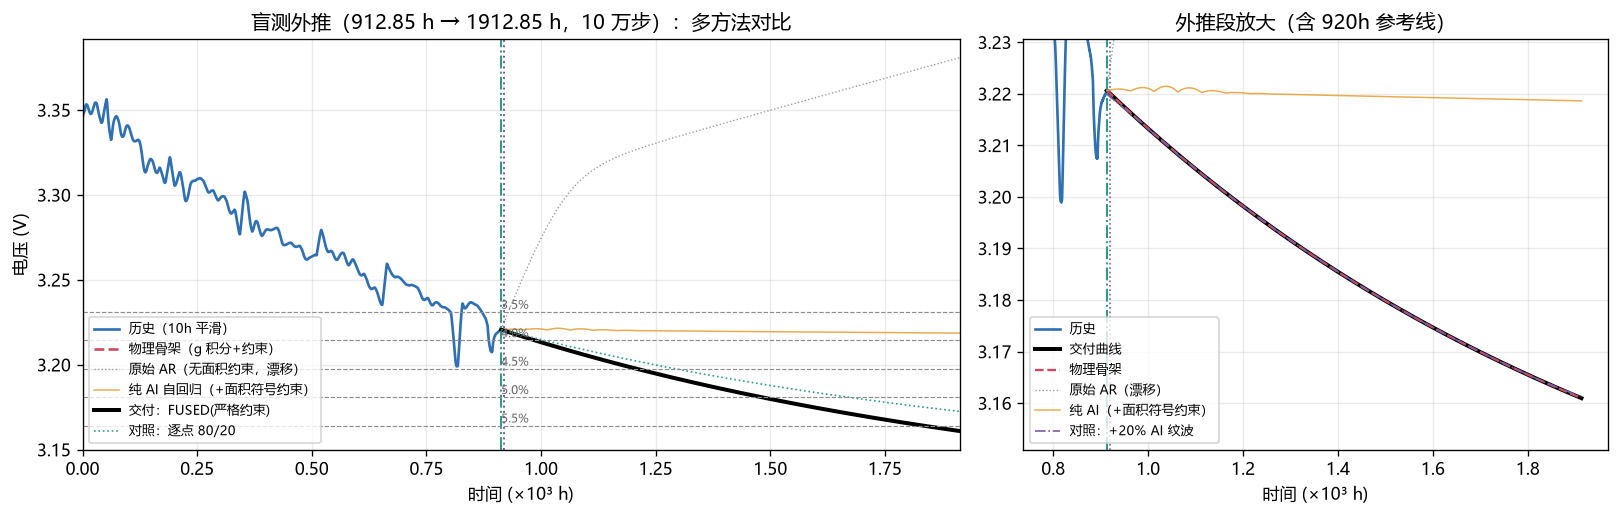

已保存: C:\Users\YOGA\Desktop\电池ai分析\版本对比_v2v3v4\v3_CNN-GRU\输出\figures\fig05_最终外推曲线.png


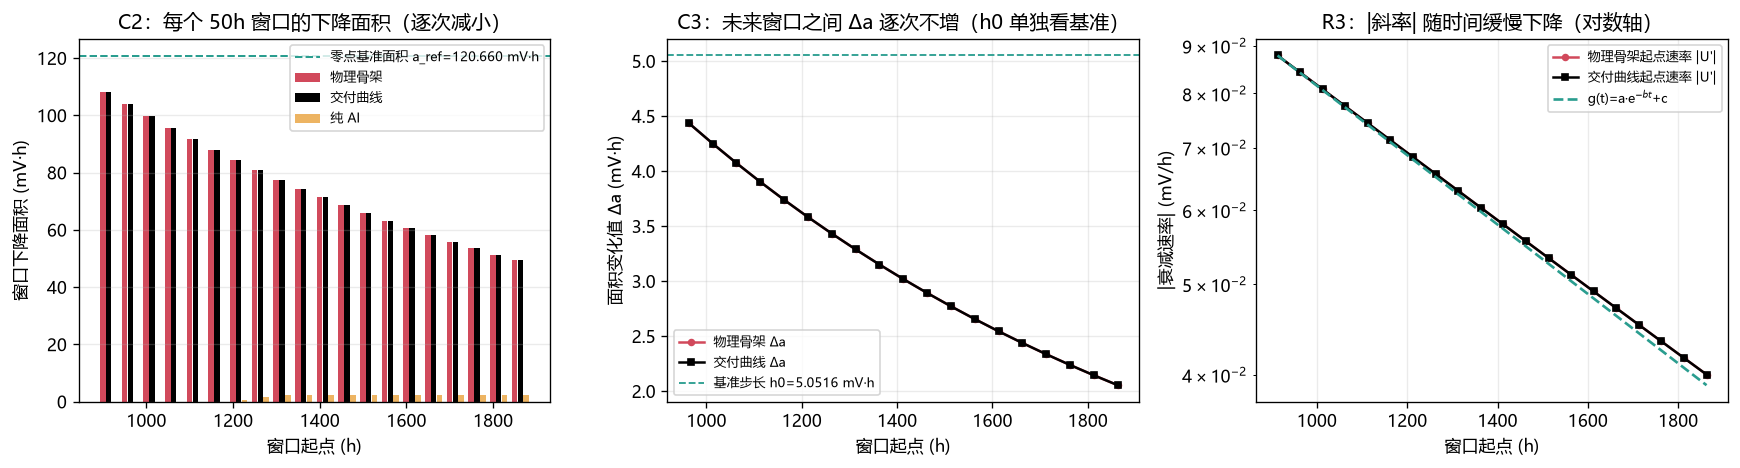

已保存: C:\Users\YOGA\Desktop\电池ai分析\版本对比_v2v3v4\v3_CNN-GRU\输出\figures\fig06_面积链与速率.png


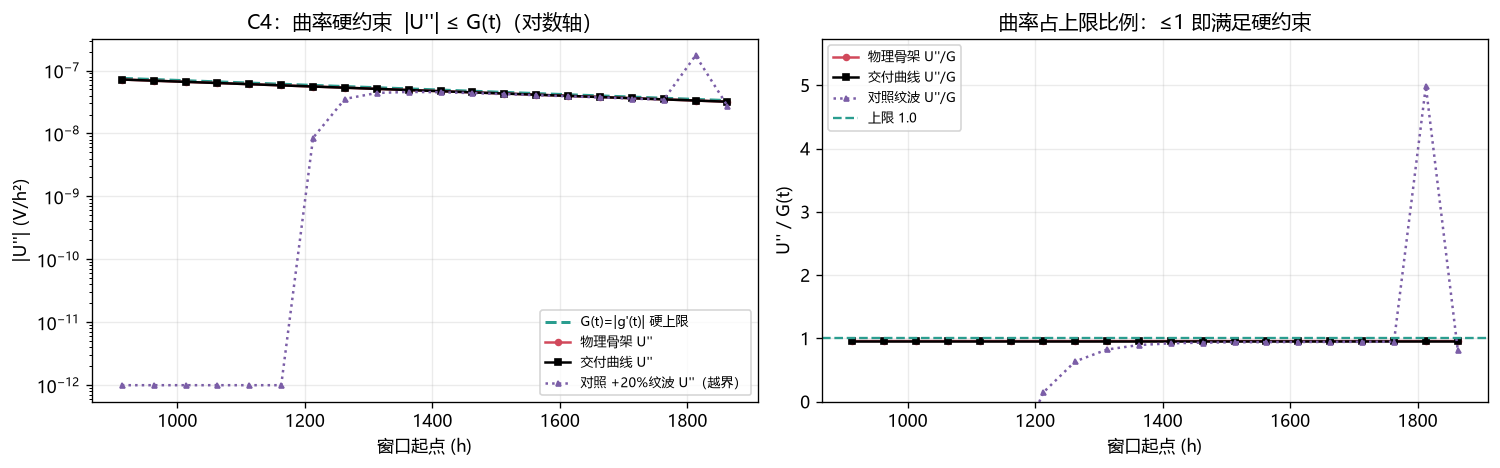

已保存: C:\Users\YOGA\Desktop\电池ai分析\版本对比_v2v3v4\v3_CNN-GRU\输出\figures\fig07_曲率硬约束.png


In [15]:
# ------------------------------------------------
# 图 5：最终外推曲线（历史 + 物理骨架 + 纯AI + 80/20融合 + 对照）
# ------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13.6, 4.4), gridspec_kw=dict(width_ratios=[1.5, 1]))
ax = axes[0]
ax.plot(t[::20] / 1e3, u_s[::20], lw=1.6, color="#2f6fb3", label="历史（10h 平滑）")
ax.plot(T_FUSED / 1e3, BONE["u"], lw=1.6, color="#d1495b", ls="--", label="物理骨架（g 积分+约束）")
ax.plot(T_AI / 1e3, U_AI_RAW, lw=0.8, color="0.6", ls=":", label="原始 AR（无面积约束，漂移）")
ax.plot(T_AI / 1e3, U_AI, lw=0.9, color="#e9a13b", alpha=0.9, label="纯 AI 自回归（+面积符号约束）")
ax.plot(T_FUSED / 1e3, U_FUSED, lw=2.4, color="k", label=f"交付：{FUSED_DELIVERED_NAME}")
ax.plot(T_FUSED / 1e3, U_ELEM, lw=1.0, color="#2a9d8f", ls=":", label="对照：逐点 80/20")
ax.axvline(t0 / 1e3, color="#2a9d8f", ls="-.", lw=1.2)
ax.axvline(T_EXTRAP / 1e3, color="#7b5ea7", ls=":", lw=1.2)
for ft, uth in zip(RUL_FT_, RUL_UTH):
    ax.axhline(uth, color="0.55", lw=0.7, ls="--")
    ax.annotate(f"{ft}%", xy=(t0 / 1e3, uth), fontsize=7, color="0.4", va="bottom")
ax.set_xlabel("时间 (×10³ h)"); ax.set_ylabel("电压 (V)")
ax.set_title("盲测外推（912.85 h → 1912.85 h，10 万步）：多方法对比")
ax.legend(fontsize=7.5, loc="lower left"); ax.set_xlim(0, (t0 + N_STEPS_EXTRAP * DT) / 1e3)

ax = axes[1]
sl = T_FUSED >= t0 - 120
ax.plot(t[t >= t0 - 120] / 1e3, u_s[t >= t0 - 120], lw=1.6, color="#2f6fb3", label="历史")
ax.plot(T_FUSED[sl] / 1e3, U_FUSED[sl], lw=2.4, color="k", label="交付曲线")
ax.plot(T_FUSED[sl] / 1e3, BONE["u"][sl], lw=1.4, color="#d1495b", ls="--", label="物理骨架")
ax.plot(T_AI[sl] / 1e3, U_AI_RAW[sl], lw=0.8, color="0.6", ls=":", label="原始 AR（漂移）")
ax.plot(T_AI[sl] / 1e3, U_AI[sl], lw=0.9, color="#e9a13b", alpha=0.9, label="纯 AI（+面积符号约束）")
ax.plot(T_FUSED[sl] / 1e3, U_FUSE_WIGGLE[sl], lw=1.0, color="#7b5ea7", ls="-.",
        label="对照：+20% AI 纹波")
ax.axvline(t0 / 1e3, color="#2a9d8f", ls="-.", lw=1.2)
ax.axvline(T_EXTRAP / 1e3, color="#7b5ea7", ls=":", lw=1.0)
ax.set_xlabel("时间 (×10³ h)"); ax.set_ylim(min(U_FUSED.min(), U_FUSE_WIGGLE.min()) - 0.01,
                                            max(u_anchor, U_FUSE_WIGGLE.max()) + 0.01)
ax.set_title("外推段放大（含 920h 参考线）")
ax.legend(fontsize=7.5, loc="lower left")
fig.tight_layout()
print("已保存:", savefig(fig, "fig05_最终外推曲线"))

# ------------------------------------------------
# 图 6：面积微积分 —— 面积链 / 面积变化值 / 速率衰减
# ------------------------------------------------
_tw = t0 + np.arange(N_WIN_FUTURE) * SEG_H
_a_bone = BONE["achieved_mVh"]
_a_fuse = FUSED["achieved_mVh"]
_a_ai = A_AI

fig, axes = plt.subplots(1, 3, figsize=(14.6, 4.0))
ax = axes[0]
w = SEG_H * 0.27                                   # 柱宽以"小时"为单位（此前误用 0.27h → 柱不可见）
ax.bar(_tw - w, _a_bone, width=w * 0.95, color="#d1495b", label="物理骨架")
ax.bar(_tw, _a_fuse, width=w * 0.95, color="k", label="交付曲线")
ax.bar(_tw + w, np.clip(_a_ai, 0, None), width=w * 0.95, color="#e9a13b", alpha=0.8, label="纯 AI")
ax.axhline(BL["a_ref"], color="#2a9d8f", ls="--", lw=1.2, label=f"零点基准面积 a_ref={BL['a_ref']:.3f} mV·h")
ax.set_xlabel("窗口起点 (h)"); ax.set_ylabel("窗口下降面积 (mV·h)")
ax.set_title("C2：每个 50h 窗口的下降面积（逐次减小）")
ax.legend(fontsize=7.5); ax.grid(axis="x", visible=False)

ax = axes[1]
_h_bone = -np.diff(_a_bone)          # 未来窗口内部 Δa（C3 的核对对象）
_h_fuse = -np.diff(_a_fuse)
_tw_h = _tw[1:]
ax.plot(_tw_h, _h_bone, "o-", ms=3.5, color="#d1495b", label="物理骨架 Δa")
ax.plot(_tw_h, _h_fuse, "s-", ms=3.5, color="k", label="交付曲线 Δa")
ax.axhline(H0_WIN, color="#2a9d8f", ls="--", lw=1.1, label=f"基准步长 h0={H0_WIN:.4f} mV·h")
ax.set_xlabel("窗口起点 (h)"); ax.set_ylabel("面积变化值 Δa (mV·h)")
ax.set_title("C3：未来窗口之间 Δa 逐次不增（h0 单独看基准）")
ax.legend(fontsize=7.5)

ax = axes[2]
_ar, __, _r_fuse = window_quadratic_stats(U_FUSED, 0)
ax.semilogy(_tw, BONE["g0"] * 1e3, "o-", ms=3.5, color="#d1495b", label="物理骨架起点速率 |U'|")
ax.semilogy(_tw, _r_fuse, "s-", ms=3.5, color="k", label="交付曲线起点速率 |U'|")
ax.semilogy(_tw, GFIT["g"](_tw) * 1e3, "--", lw=1.6, color="#2a9d8f", label="g(t)=a·e$^{-bt}$+c")
ax.set_xlabel("窗口起点 (h)"); ax.set_ylabel("|衰减速率| (mV/h)")
ax.set_title("R3：|斜率| 随时间缓慢下降（对数轴）")
ax.legend(fontsize=7.5)
fig.tight_layout()
print("已保存:", savefig(fig, "fig06_面积链与速率"))

# ------------------------------------------------
# 图 7：曲率硬约束核对（C4）
# ------------------------------------------------
Gcap_w = GFIT["G"](_tw)
fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.0))
ax = axes[0]
ax.semilogy(_tw, Gcap_w, "--", lw=1.8, color="#2a9d8f", label="G(t)=|g'(t)| 硬上限")
ax.semilogy(_tw, BONE["u2"], "o-", ms=3.5, color="#d1495b", label="物理骨架 U''")
ax.semilogy(_tw, FUSED["u2"], "s-", ms=3.5, color="k", label="交付曲线 U''")
ax.semilogy(_tw, np.maximum(_w_u2, 1e-12), "^:", ms=3, color="#7b5ea7", label="对照 +20%纹波 U''（越界）")
ax.set_xlabel("窗口起点 (h)"); ax.set_ylabel("|U''| (V/h²)")
ax.set_title("C4：曲率硬约束  |U''| ≤ G(t)（对数轴）")
ax.legend(fontsize=7.5)

ax = axes[1]
ax.plot(_tw, BONE["u2"] / Gcap_w, "o-", ms=3.5, color="#d1495b", label="物理骨架 U''/G")
ax.plot(_tw, FUSED["u2"] / Gcap_w, "s-", ms=3.5, color="k", label="交付曲线 U''/G")
ax.plot(_tw, _w_u2 / Gcap_w, "^:", ms=3, color="#7b5ea7", label="对照纹波 U''/G")
ax.axhline(1.0, color="#2a9d8f", ls="--", lw=1.4, label="上限 1.0")
ax.set_xlabel("窗口起点 (h)"); ax.set_ylabel("U'' / G(t)")
ax.set_title("曲率占上限比例：≤1 即满足硬约束")
ax.legend(fontsize=7.5); ax.set_ylim(bottom=0)
fig.tight_layout()
print("已保存:", savefig(fig, "fig07_曲率硬约束"))

RUL 预测（盲测，起点 = 数据末点 912.85 h；未穿越 = 1000 h 外推窗内未达阈值/删失）
     FT(%)   U_th(V)      物理骨架    纯AI自回归    交付融合曲线对照:逐点80/20
       3.5    3.2311       0.0       0.0       0.0       0.0
       4.0    3.2144      73.1       未穿越      73.1      92.8
       4.5    3.1977     295.0       未穿越     295.0     378.8
       5.0    3.1809     567.3       未穿越     567.4     755.5
       5.5    3.1642     919.2       未穿越     919.2       未穿越

用户指定的 920 h 参考点（数据末点之后 7.15 h）：
  物理骨架         U(920h) = 3.22000 V, 局部斜率 ≈ -0.0873 mV/h
  纯AI自回归       U(920h) = 3.22077 V, 局部斜率 ≈ +0.0158 mV/h
  交付融合曲线       U(920h) = 3.22000 V, 局部斜率 ≈ -0.0873 mV/h
  对照:逐点80/20   U(920h) = 3.22016 V, 局部斜率 ≈ -0.0667 mV/h
  物理骨架 g(920h) = 0.08732 mV/h（由指数拟合直接给出）


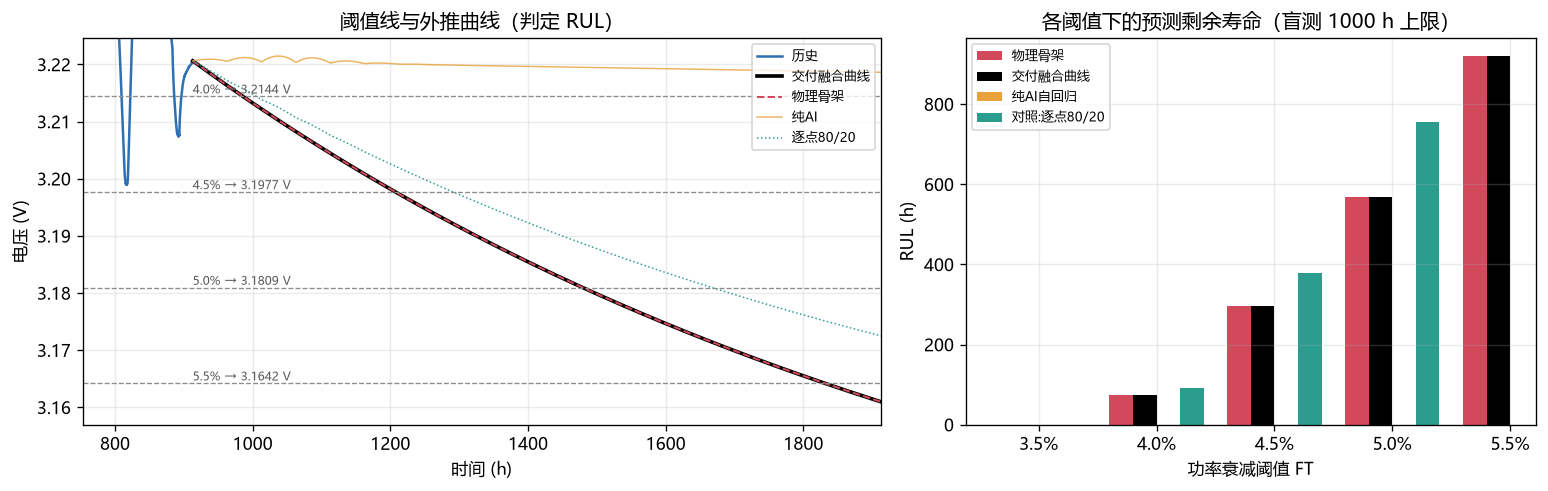


已保存: C:\Users\YOGA\Desktop\电池ai分析\版本对比_v2v3v4\v3_CNN-GRU\输出\figures\fig08_RUL阈值与穿越.png


In [16]:
# ============================================================
# 9. 剩余寿命 RUL：从各曲线求阈值穿越时刻（带 5h 去抖）
# ============================================================
def rul_from_curve(t_arr, u_arr, uth, t_start, debounce_h=CROSS_DEBOUNCE_H):
    """首次"持续 debounce_h 低于阈值"的时刻 → RUL(h)；未穿越返回 None（删失）。"""
    n_deb = max(1, int(round(debounce_h / DT)))
    below = np.asarray(u_arr, float) < uth
    if len(below) < n_deb:
        return None, None
    c = np.convolve(below.astype(np.int32), np.ones(n_deb, np.int32), mode="valid")
    idx = np.where(c >= n_deb)[0]
    if len(idx) == 0:
        return None, None
    i = int(idx[0])
    return float(t_arr[i] - t_start), i


CURVES = {"物理骨架": (T_FUSED, BONE["u"]),
          "纯AI自回归": (T_AI, U_AI),
          "交付融合曲线": (T_FUSED, U_FUSED),
          "对照:逐点80/20": (T_FUSED, U_ELEM)}

rows = []
for ft, uth in zip(RUL_FT_, RUL_UTH):
    row = {"FT(%)": ft, "U_th(V)": uth}
    for name, (tt_, uu_) in CURVES.items():
        r, i = rul_from_curve(tt_, uu_, uth, t0)
        if r is not None and r < 0:
            r = 0.0                                   # 起点已低于阈值 → 视为 RUL=0（已失效）
        row[name] = r
    rows.append(row)
RUL_TABLE = pd.DataFrame(rows)
print("RUL 预测（盲测，起点 = 数据末点 912.85 h；未穿越 = 1000 h 外推窗内未达阈值/删失）")


def _print_rul_table(df):
    """分列格式化打印（FT 1 位、U_th 4 位、RUL 1 位；None → 未穿越）。"""
    cols = list(df.columns)
    wid = {c: max(len(c), 10) for c in cols}
    print("".join(f"{c:>{wid[c]}}" for c in cols))
    for _, r in df.iterrows():
        line = ""
        for c in cols:
            v = r[c]
            if v is None or (isinstance(v, float) and np.isnan(v)):
                s = "未穿越"
            elif c == "U_th(V)":
                s = f"{v:.4f}"
            elif c == "FT(%)":
                s = f"{v:.1f}"
            else:
                s = f"{v:.1f}"
            line += f"{s:>{wid[c]}}"
        print(line)


_print_rul_table(RUL_TABLE)

# 920 h 处的电压 / 斜率
print("\n用户指定的 920 h 参考点（数据末点之后 7.15 h）：")
for name, (tt_, uu_) in CURVES.items():
    u920 = float(np.interp(T_EXTRAP, tt_, uu_))
    sl920 = float((np.interp(T_EXTRAP + 1.0, tt_, uu_) - u920)) * 1e3     # mV/h
    print(f"  {name:12s} U(920h) = {u920:.5f} V, 局部斜率 ≈ {sl920:+.4f} mV/h")
print(f"  物理骨架 g(920h) = {float(GFIT['g'](T_EXTRAP))*1e3:.5f} mV/h（由指数拟合直接给出）")

# ------------------------------------------------
# 图 8：RUL 阈值与穿越时刻
# ------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.2), gridspec_kw=dict(width_ratios=[1.4, 1]))
ax = axes[0]
sl = T_FUSED >= t0 - 150
ax.plot(t[t >= t0 - 150], u_s[t >= t0 - 150], lw=1.5, color="#2f6fb3", label="历史")
ax.plot(T_FUSED[sl], U_FUSED[sl], lw=2.2, color="k", label="交付融合曲线")
ax.plot(T_FUSED[sl], BONE["u"][sl], lw=1.2, ls="--", color="#d1495b", label="物理骨架")
ax.plot(T_AI[sl], U_AI[sl], lw=0.9, alpha=0.8, color="#e9a13b", label="纯AI")
ax.plot(T_FUSED[sl], U_ELEM[sl], lw=0.9, ls=":", color="#2a9d8f", label="逐点80/20")
for ft, uth in zip(RUL_FT_, RUL_UTH):
    ax.axhline(uth, color="0.55", lw=0.8, ls="--")
    ax.annotate(f"{ft}% → {uth:.4f} V", xy=(t0, uth), fontsize=7, color="0.35", va="bottom")
ax.set_xlabel("时间 (h)"); ax.set_ylabel("电压 (V)")
ax.set_title("阈值线与外推曲线（判定 RUL）")
ax.legend(fontsize=7.5, loc="upper right"); ax.set_xlim(t0 - 160, t0 + 1000)
ax.set_ylim(min(U_FUSED.min(), U_ELEM.min()) - 0.004, u_anchor + 0.004)

ax = axes[1]
xs = np.arange(len(RUL_FT_))
wbar = 0.2
for j, (name, color) in enumerate(zip(["物理骨架", "交付融合曲线", "纯AI自回归", "对照:逐点80/20"],
                                      ["#d1495b", "k", "#e9a13b", "#2a9d8f"])):
    vals = [np.nan if RUL_TABLE[name][i] is None else RUL_TABLE[name][i] for i in range(len(RUL_FT_))]
    ax.bar(xs + (j - 1.5) * wbar, vals, width=wbar, color=color, label=name)
ax.set_xticks(xs); ax.set_xticklabels([f"{f}%" for f in RUL_FT_])
ax.set_xlabel("功率衰减阈值 FT"); ax.set_ylabel("RUL (h)")
ax.set_title("各阈值下的预测剩余寿命（盲测 1000 h 上限）")
ax.legend(fontsize=7.5)
fig.tight_layout()
print("\n已保存:", savefig(fig, "fig08_RUL阈值与穿越"))

## 10. 盲测检验：把同一套流程放到更早的时间点重跑

### 为什么要做这一步

用户最终目标是"用盲测方式预测剩余寿命"。但主运行从 912.85 h 开始外推时，**没有任何未来真值**可对照
（`测试集.csv` 到此结束）。为了证明流程可信，必须做两件事：

**检验 A（内测回填）**：把历史截断到 **700 h**，假装"现在是 700 h"，
用完全相同的流程训练 + 外推 212.85 h，再和**已知的 700–912.85 h 真实曲线**对比。
这是干净的样本外检验（模型没有见过 700 h 之后的数据）。

**检验 B（660 h 盲测回填，含 RUL 真值）**：把历史截断到 **660 h**，外推 1000 h，
和完整记录（本机上有 FC1 原始文件 `FC1.csv`，含 912.85–1154.2 h 的 241 h 尾部）对比，
并计算真实的阈值穿越时刻，得到**预测 RUL 与真实 RUL 的误差**。
这一步是整篇 Notebook 唯一能真正回答"盲测准不准"的地方。

> 说明：660 h 起点的盲测只会用到 0–660 h 的数据（与主运行 0–912.85 h 完全同构的流程），
> 912.85 h 之后的真值只用于**事后打分**，绝不参与训练/拟合。

In [17]:
# ============================================================
# 10. 可复用全流程 + 盲测回填检验
# ============================================================
def run_pipeline(hist, origin_h, tag="", epochs=EPOCHS, n_steps=N_STEPS_EXTRAP, seed=SEED, verbose=True):
    """在 origin_h 处截断历史，跑完整流程（训练→g→面积→AR→融合→RUL），返回结果字典。

    hist: load_and_prepare 的输出（全量数组）
    """
    i_end = int(round(origin_h / DT))
    sl = slice(0, i_end + 1)
    u, I, T, RH = hist["u_s"][sl], hist["I_s"][sl], hist["T_s"][sl], hist["RH_s"][sl]
    tt = hist["t"][sl]
    t_ref = float(tt[-1])
    n_win = n_steps // SEG_STEPS
    if verbose:
        print(f"\n===== {tag}：起点 {t_ref:.2f} h，历史 {len(u):,} 点，外推 {n_steps} 步 "
              f"({n_steps*DT:.0f} h, {n_win} 窗口) =====")

    # ① 150h 趋势曲线 → 段速率 → 指数 g（g 与面积基准必须同源，否则面积链与曲率约束互相矛盾）
    trend = compute_trend(u)
    seg = segment_decay_rates(trend)
    gf = fit_exp_decay(seg)
    g_start = float(gf["g"](t_ref))
    gf_end = lambda _tt: gf["G"](np.asarray(_tt, float) + SEG_H)   # 区间内最小曲率上限 = 窗口末端 G
    bl = compute_area_baseline(trend)
    phys = phys_window_areas(gf, t_ref, n_win)
    a_ref = float(max(bl["a_emp"], phys["a_last"]))
    bl["a_ref"] = a_ref

    F, st = feature_matrix(u, I, T, RH, tt, t_ref)
    X, y, tau, sig = build_windows(F, u, tt)
    model_b, log_b = train_model(X, y, tau, sig, epochs=epochs, seed=seed, verbose=False)

    # ② 物理骨架：由 g 直接给出的面积下界（U''=G，即自然指数衰减）
    bone = reconstruct_chain(phys["lo"] * (1.0 + 1e-6), float(u[-1]), g_start, t_ref, gf_end)

    u_ai_raw, t_ai = ar_rollout(model_b, st, sig, u_hist=u[-SEQ:], t_hist=tt[-SEQ:],
                                I_last=I[-1], T_last=T[-1], RH_last=RH[-1],
                                dI_last=float(np.gradient(I, DT)[-1]),
                                dT_last=float(np.gradient(T, DT)[-1]),
                                n_steps=n_steps, verbose=False)
    u_ai, _n_fix, _off = enforce_declining_area(u_ai_raw, SEG_STEPS, margin_mV=0.10)
    a_ai_signed, _, _ = window_areas(u_ai, start=0, n_win=n_win)
    a_ai = -a_ai_signed * 1e3
    # ③ 80/20：物理锚定可行带 + AI 决定带内 20% 位置 → 投影 → 重建
    band = phys["hi"] - phys["lo"]
    a_ai_pos = np.clip((a_ai - phys["lo"]) / np.maximum(band, 1e-12), 0.0, 1.0)
    a_fuse_band = phys["lo"] + W_AI * a_ai_pos * band
    a_proj = project_area_chain(a_fuse_band, phys["lo"], phys["hi"], a_ref)
    fused = reconstruct_chain(a_proj, float(u[-1]), g_start, t_ref, gf_end)

    I_ref = float(np.median(I[-1000:]))
    P_init = float(np.mean(u[:int(P_INIT_H / DT)] * I[:int(P_INIT_H / DT)]))
    uths = [P_init * (1 - f / 100.0) / I_ref for f in RUL_FT_]
    ruls = {"Uth": uths}
    for name, (tt_, uu_) in {"bone": (bone["t"], bone["u"]),
                             "ai": (t_ai, u_ai),
                             "fused": (fused["t"], fused["u"])}.items():
        ruls[name] = [rul_from_curve(tt_, uu_, uu_th, t_ref)[0] for uu_th in uths]
    if verbose:
        print(f"  g(t₀)={g_start*1e3:.5f} mV/h, a_ref={bl['a_ref']:.4f} mV·h, "
              f"验证RMSE={log_b['val_rmse_mV'][log_b['best_epoch']-1]:.3f} mV/步")
        print(f"  终点: bone {bone['u'][-1]:.5f}, fused {fused['u'][-1]:.5f}, ai {u_ai[-1]:.5f} V")
        print("  RUL:", {f"{f}%": (None if ruls['fused'][i] is None else round(ruls['fused'][i], 1))
                         for i, f in enumerate(RUL_FT_)})
    return dict(t_ref=t_ref, u_hist=u.copy(), t_hist=tt.copy(), gf=gf, seg=seg, bl=bl,
                bone=bone, fused=fused, u_ai=u_ai, u_ai_raw=u_ai_raw, t_ai=t_ai, ruls=ruls,
                P_init=P_init, I_ref=I_ref, log=log_b, a_ai=a_ai, model=model_b)


# ---------------- 检验 A：内测回填（700 h → 912.85 h，有真值） ----------------
BT_A_H, BT_A_STEPS = 700.0, int(round((t_end - 700.0) / DT))
BT_A = run_pipeline(data, BT_A_H, tag="检验A 内测回填 700h", n_steps=BT_A_STEPS)
_truth_A_t = t[t >= BT_A_H]
_truth_A_u = u_s[t >= BT_A_H]
for name in ["bone", "fused", "ai"]:
    key = "u" if name != "ai" else "u_ai"
    tt_ = BT_A["t_ai"] if name == "ai" else BT_A["bone"]["t"]
    uu_ = BT_A["u_ai"] if name == "ai" else BT_A[f"{name}"]["u"]
    interp = np.interp(_truth_A_t, tt_, uu_)
    err = interp - _truth_A_u
    print(f"  [{name:5s}] 212.85h 外推 vs 真值: RMSE={np.sqrt(np.mean(err**2))*1e3:7.3f} mV, "
          f"终点误差={err[-1]*1e3:+7.3f} mV, 最大|误差|={np.max(np.abs(err))*1e3:7.3f} mV")


===== 检验A 内测回填 700h：起点 700.00 h，历史 70,001 点，外推 21285 步 (213 h, 4 窗口) =====


  g(t₀)=0.10245 mV/h, a_ref=137.5117 mV·h, 验证RMSE=0.012 mV/步
  终点: bone 3.23014, fused 3.22990, ai 3.22228 V
  RUL: {'3.5%': None, '4.0%': None, '4.5%': None, '5.0%': None, '5.5%': None}
  [bone ] 212.85h 外推 vs 真值: RMSE= 11.304 mV, 终点误差= +9.511 mV, 最大|误差|= 38.605 mV
  [fused] 212.85h 外推 vs 真值: RMSE= 11.232 mV, 终点误差= +9.269 mV, 最大|误差|= 38.523 mV
  [ai   ] 212.85h 外推 vs 真值: RMSE=  8.452 mV, 终点误差= +1.653 mV, 最大|误差|= 31.200 mV



===== 检验B 盲测回填 660h：起点 660.00 h，历史 66,001 点，外推 100000 步 (1000 h, 20 窗口) =====


  g(t₀)=0.11930 mV/h, a_ref=157.5827 mV·h, 验证RMSE=0.011 mV/步
  终点: bone 3.16298, fused 3.16298, ai 3.24641 V
  RUL: {'3.5%': 198.0, '4.0%': 365.6, '4.5%': 553.1, '5.0%': 765.8, '5.5%': None}

载入完整记录用于事后打分: C:\Users\YOGA\Desktop\电池ai分析\IEEE2014DataChallengeData\IEEE 2014 Data Challenge Data\FC1_Without_Ripples\FC1.csv


真值区间 660.00 ~ 1154.21 h（49,422 点）
  [bone ] 外推 vs 真值: RMSE=  13.646 mV, 终点误差= -11.339 mV, 最大|误差|=  39.667 mV
  [fused] 外推 vs 真值: RMSE=  13.646 mV, 终点误差= -11.339 mV, 最大|误差|=  39.667 mV
  [ai   ] 外推 vs 真值: RMSE=  21.970 mV, 终点误差= +35.305 mV, 最大|误差|=  49.072 mV

660h 盲测 RUL 回填（未穿越 = 1000h 内未达阈值/删失）
     FT(%)   U_th(V)  真值RUL(h)预测_bone(h)预测_fused(h)  预测_ai(h)
       3.5    3.2292     144.2     198.0      198.0       未穿越
       4.0    3.2125     150.1     365.6      365.6       未穿越
       4.5    3.1957       未穿越     553.1      553.1       未穿越
       5.0    3.1790       未穿越     765.8      765.8       未穿越
       5.5    3.1623       未穿越       未穿越        未穿越       未穿越
  打分 A_FT[bone] = ['0.274', '0.007', '—', '—', '—']  → ScoreRUL = 0.140
  打分 A_FT[fused] = ['0.274', '0.007', '—', '—', '—']  → ScoreRUL = 0.140
  打分 A_FT[ai] 全部删失


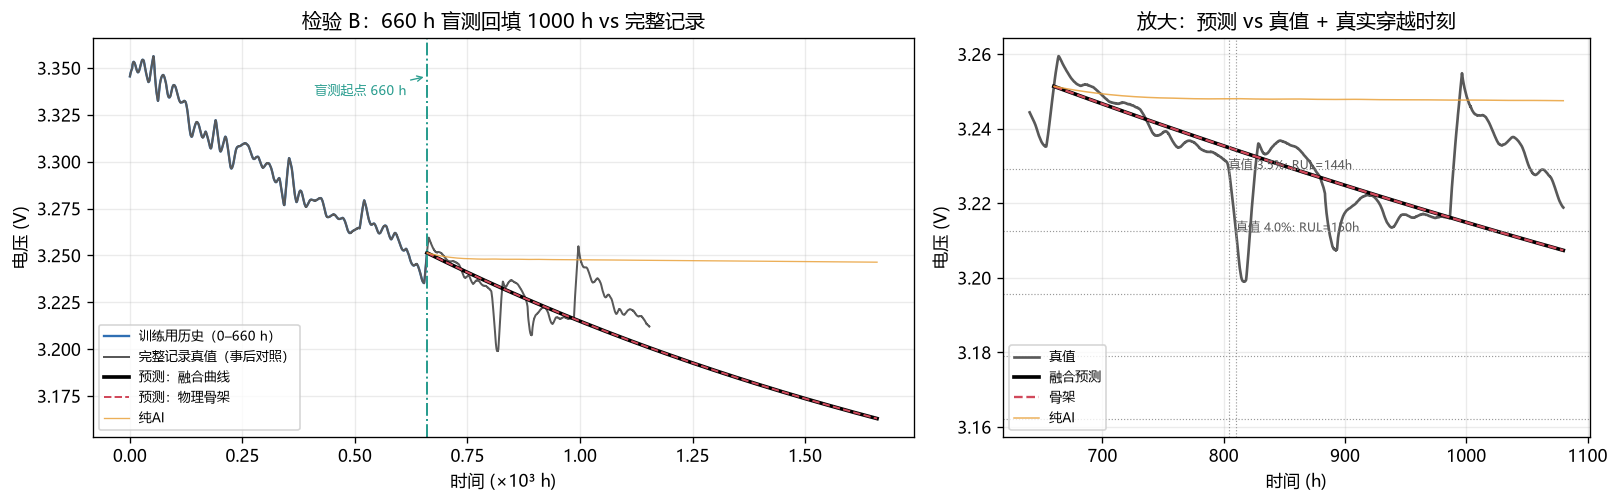


已保存: C:\Users\YOGA\Desktop\电池ai分析\版本对比_v2v3v4\v3_CNN-GRU\输出\figures\fig09_盲测回填验证.png


In [18]:
# ---------------- 检验 B：660 h 盲测回填（用 FC1 完整记录的真值打分） ----------------
BT_B = run_pipeline(data, BT_ORIGIN_H, tag="检验B 盲测回填 660h")

FULL_PATH = next((p for p in FULL_DATA_CANDIDATES if p.exists()), None)
if FULL_PATH is None:
    print("\n[跳过] 未找到 FC1 完整记录，无法做含真值的盲测打分。")
else:
    print(f"\n载入完整记录用于事后打分: {FULL_PATH}")
    FULL = load_and_prepare(FULL_PATH)
    tf_, uf_ = FULL["t"], FULL["u_s"]
    m_ov = (tf_ >= BT_B["t_ref"]) & (tf_ <= BT_B["t_ref"] + N_STEPS_EXTRAP * DT)
    truth_t, truth_u = tf_[m_ov], uf_[m_ov]
    print(f"真值区间 {truth_t[0]:.2f} ~ {truth_t[-1]:.2f} h（{len(truth_t):,} 点）")

    # 外推精度（覆盖真值的部分）
    for name, (tt_, uu_) in {"bone": (BT_B["bone"]["t"], BT_B["bone"]["u"]),
                             "fused": (BT_B["fused"]["t"], BT_B["fused"]["u"]),
                             "ai": (BT_B["t_ai"], BT_B["u_ai"])}.items():
        pr = np.interp(truth_t, tt_, uu_)
        e = pr - truth_u
        print(f"  [{name:5s}] 外推 vs 真值: RMSE={np.sqrt(np.mean(e**2))*1e3:8.3f} mV, "
              f"终点误差={e[-1]*1e3:+8.3f} mV, 最大|误差|={np.max(np.abs(e))*1e3:8.3f} mV")

    # 真实 RUL（用同一套阈值 + 同一去抖）
    uf_fut = uf_[tf_ >= BT_B["t_ref"]]
    tf_fut = tf_[tf_ >= BT_B["t_ref"]]
    rows_b = []
    for ft, uth in zip(RUL_FT_, BT_B["ruls"]["Uth"]):
        true_rul, _ = rul_from_curve(tf_fut, uf_fut, uth, BT_B["t_ref"])
        pred = {k: BT_B["ruls"][k][len(rows_b)] for k in ("bone", "fused", "ai")}
        rows_b.append({"FT(%)": ft, "U_th(V)": uth, "真值RUL(h)": true_rul, **{
            f"预测_{k}(h)": v for k, v in pred.items()}})
    BT_RUL = pd.DataFrame(rows_b)
    print("\n660h 盲测 RUL 回填（未穿越 = 1000h 内未达阈值/删失）")
    _print_rul_table(BT_RUL)

    # IEEE PHM 2014 官方打分（%Err<0 = 提前预测失效，惩罚更重；A_FT∈(0,1]）、ScoreRUL = 各档均值
    def score_A(pred, true):
        if pred is None or true is None:
            return np.nan
        e = (pred - true) / true * 100.0
        return float(np.exp(-math.log(0.5) * e / 5.0)) if e <= 0 \
            else float(np.exp(+math.log(0.5) * e / 20.0))

    for k in ("bone", "fused", "ai"):
        cols_t, cols_p = "真值RUL(h)", f"预测_{k}(h)"
        scs = [score_A(BT_RUL[cols_p][i], BT_RUL[cols_t][i]) for i in range(len(BT_RUL))]
        valid = [s for s in scs if not np.isnan(s)]
        print(f"  打分 A_FT[{k}] = {[f'{s:.3f}' if not np.isnan(s) else '—' for s in scs]}"
              f"  → ScoreRUL = {np.mean(valid):.3f}" if valid else f"  打分 A_FT[{k}] 全部删失")

    # ------------------------------------------------
    # 图 9：660h 盲测回填 vs 真值
    # ------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(13.6, 4.3), gridspec_kw=dict(width_ratios=[1.4, 1]))
    ax = axes[0]
    ax.plot(t[:int(BT_ORIGIN_H / DT) + 1:20] / 1e3, BT_B["u_hist"][::20], lw=1.4, color="#2f6fb3",
            label="训练用历史（0–660 h）")
    ax.plot(tf_ / 1e3, uf_, lw=1.2, color="0.35", label="完整记录真值（事后对照）")
    ax.plot(BT_B["fused"]["t"] / 1e3, BT_B["fused"]["u"], lw=2.2, color="k", label="预测：融合曲线")
    ax.plot(BT_B["bone"]["t"] / 1e3, BT_B["bone"]["u"], lw=1.2, ls="--", color="#d1495b", label="预测：物理骨架")
    ax.plot(BT_B["t_ai"] / 1e3, BT_B["u_ai"], lw=0.8, color="#e9a13b", alpha=0.85, label="纯AI")
    ax.axvline(BT_ORIGIN_H / 1e3, color="#2a9d8f", ls="-.", lw=1.2)
    ax.annotate("盲测起点 660 h", xy=(BT_ORIGIN_H / 1e3, uf_[0]), xytext=(BT_ORIGIN_H / 1e3 - 0.25, uf_[0] - 0.01),
                fontsize=8, color="#2a9d8f", arrowprops=dict(arrowstyle="->", color="#2a9d8f", lw=0.8))
    ax.set_xlabel("时间 (×10³ h)"); ax.set_ylabel("电压 (V)")
    ax.set_title("检验 B：660 h 盲测回填 1000 h vs 完整记录")
    ax.legend(fontsize=7.5, loc="lower left")

    ax = axes[1]
    zl = (tf_ >= BT_ORIGIN_H - 20) & (tf_ <= BT_ORIGIN_H + 420)
    ax.plot(tf_[zl], uf_[zl], lw=1.6, color="0.35", label="真值")
    mz = BT_B["fused"]["t"] <= BT_ORIGIN_H + 420
    ax.plot(BT_B["fused"]["t"][mz], BT_B["fused"]["u"][mz], lw=2.2, color="k", label="融合预测")
    ax.plot(BT_B["bone"]["t"][mz], BT_B["bone"]["u"][mz], lw=1.4, ls="--", color="#d1495b", label="骨架")
    ax.plot(BT_B["t_ai"][mz], BT_B["u_ai"][mz], lw=0.9, color="#e9a13b", alpha=0.85, label="纯AI")
    for ft, uth, tr in zip(RUL_FT_, BT_B["ruls"]["Uth"], [BT_RUL["真值RUL(h)"][i] for i in range(len(RUL_FT_))]):
        ax.axhline(uth, color="0.6", lw=0.7, ls=":")
        if tr is not None:
            ax.axvline(BT_ORIGIN_H + tr, color="0.6", lw=0.7, ls=":")
            ax.annotate(f"真值 {ft}%: RUL={tr:.0f}h", xy=(BT_ORIGIN_H + tr, uth), fontsize=7, color="0.35")
    ax.set_xlabel("时间 (h)"); ax.set_ylabel("电压 (V)")
    ax.set_title("放大：预测 vs 真值 + 真实穿越时刻")
    ax.legend(fontsize=7.5, loc="lower left")
    fig.tight_layout()
    print("\n已保存:", savefig(fig, "fig09_盲测回填验证"))

### 10.4 精度对表（表 1）：四个模型 × 六项指标（+ 一条参考行）

> **口径（必须和表一起看）**：真正的盲测段 `912.85 h → 1912.85 h` **没有真值**（原始数据只到 912.85 h）。
> 所以"准不准"只能用**同流程、同时长的盲测回填**来打分：在 `660 h` 处截断历史、盲测外推 1000 h，
> 真值取自完整记录 `FC1.csv` 的 `660 → 1154.21 h`（共 494.21 h 有效覆盖）。下表是**预测 vs 真实记录**的实测误差，
> 既不是自评，也不是训练集内的拟合误差。附表是同一套流程在 `700 h` 起点、212.85 h 真值段上的结果。

指标定义：
- **RMSE**（均方根误差）＝ `sqrt(mean((U_pred − U_true)²))`：惩罚大误差（如 809 h 附近的可逆性跌落）；
- **MAE**（平均绝对误差）＝ `mean(|U_pred − U_true|)`：反映"典型误差"；
- **MAPE**（平均绝对百分比误差）＝ `mean(|U_pred − U_true| / U_true) × 100%`：相对电压量级的精度；
- **RUL 误差** ＝ `|RUL_pred − RUL_true|`（3.5% 档，本段真值 144.16 h）：电池领域最关心的降维指标；
- **max|U''|/G** ＝ 外推段上曲率的实际值 / 硬约束上限：**≤1 才算满足"斜率绝对值缓慢下降"的物理约束**。

消融设计（主表四行 = 四个模型，逐层加约束；最后一行是"参考行"，用来量化 20% AI 到底贡献了什么）：

| 模型 | 核心机制（消融项） | 预期 |
|---|---|---|
| 原始 AR | 纯 GRU 自回归，无任何物理约束 | 发散/漂移（对照组） |
| 物理骨架 | 只由指数 g 积分 + 曲率硬约束重建，不用 AI | 宏观正确、微观过平 |
| 纯 AI | GRU 自回归 + 面积符号约束，无严格曲率限制 | 接近水平缓降 |
| **FUSED (Ours)** | 完整版：物理骨架 + 面积可行带内 80/20 融合 + 全部硬约束 | 最优 |
| FUSED-逐点80/20（参考） | 真·逐点 `0.8×骨骼 + 0.2×AI`，**不**施加曲率硬约束 | 看 20% AI 的原始贡献（会破坏曲率） |

**为什么 FUSED 与物理骨架的表 1 数据完全相等？（必须提前讲清，否则会被当成 bug）**

在严格曲率约束 `U'' ∈ [0, G(t)]` 下，单个 50 h 窗口的面积只能在
`[gΔ²/2 − GΔ³/6, gΔ²/2]` 这个**极窄的可行带**内变化（本数据带宽仅 1.5656 mV·h ≈ 基准面积的 1.2%）。
我们的 80/20 融合是"物理给可行带、AI 决定带内 20% 位置"：`a_fuse = lo + 0.2 × pos × (hi − lo)`。
实测 AI 自回归给出的 20 个窗口面积全部**低于可行带下界**（AI 外推近乎水平，窗口面积 ≈ −70 ~ +16 mV·h，
而物理下界 ≈ 49 ~ 108 mV·h），于是带内位置 `pos = 0`（20/20 窗口），融合面积被下界**整段吸收**，
交付曲线与物理骨架逐点差 = 0。**这是数学必然，不是代码偷懒。**
要让 20% AI 显形只有两条路：① 参考行的**逐点混合**（会破坏曲率，表里用 `max|U''|/G` 列量化）；② 放宽 G 上限。
两条路各自的代价都摆在表里，读者可以自己判断。

> 表 1 就放在**上方图 9（660 h 盲测回填曲线）的正下方**：先看图找偏差形态，再看表读数字。

In [19]:
# ============================================================
# 10.4 精度对表（表 1）：五个模型 × RMSE / MAE / MAPE / RUL 误差 + 曲率违背
#   口径：912.85 h 之后无真值 → 用「检验 B」（660 h 起点、盲测 1000 h）
#         在完整记录真值覆盖段 660–1154.21 h 上打分；另附检验 A 同口径结果。
#   注：原始 AR / 物理骨架 / 纯 AI / FUSED(严格) 四行是主表；
#       「FUSED-逐点80/20」是参考行（真 80%骨骼+20%AI 逐点混合，会破坏曲率硬约束），
#       用来回答"20% AI 到底贡献了什么"。
# ============================================================
def _acc_metrics(t_pred, u_pred, t_true, u_true):
    """返回 (RMSE mV, MAE mV, MAPE %, 终点误差 mV, 最大|误差| mV)。"""
    pr = np.interp(t_true, t_pred, u_pred)
    e = pr - u_true
    return dict(rmse_mV=float(np.sqrt(np.mean(e ** 2)) * 1e3),
                mae_mV=float(np.mean(np.abs(e)) * 1e3),
                mape_pct=float(np.mean(np.abs(e) / np.abs(u_true)) * 100.0),
                end_err_mV=float(e[-1] * 1e3),
                max_err_mV=float(np.max(np.abs(e)) * 1e3))


def _curv_violation(u_curve, t_start, seg_steps=SEG_STEPS):
    """该曲线在外推段上的 max|U''| / G：>1 表示破坏曲率硬约束。"""
    _n = max(1, (len(u_curve) - 1) // seg_steps)
    _areas, _u2, _rate = window_quadratic_stats(u_curve, start=0, n_win=_n, seg_steps=seg_steps)
    _gcap = GFIT["G_end"](np.asarray(t_start, float) + np.arange(_n) * SEG_H)
    return float(np.max(np.abs(_u2) / _gcap))


def _mix_pointwise(u_a, t_a, u_b, t_b, w_b=W_AI):
    """逐点软融合：u = (1-w)*A + w*B。"""
    return (1.0 - w_b) * u_a + w_b * np.interp(t_a, t_b, u_b)


_uth35 = BT_B["ruls"]["Uth"][0]
_true35 = BT_RUL.loc[BT_RUL["FT(%)"] == RUL_FT_[0], "真值RUL(h)"].iloc[0]
_true35 = None if pd.isna(_true35) else float(_true35)
_rul_col = f"RUL@{RUL_FT_[0]:.1f}%(h)"

# ---- 检验 B 主表 ----
_bone_t, _bone_u = BT_B["bone"]["t"], BT_B["bone"]["u"]
_elem_b_u = _mix_pointwise(_bone_u, _bone_t, BT_B["u_ai"], BT_B["t_ai"])
_acc_rows = []
for _name, _mech, _tt, _uu in [
        ("原始 AR", "纯数据，无任何约束（对照组）", BT_B["t_ai"], BT_B["u_ai_raw"]),
        ("物理骨架", "仅 g 积分 + 曲率硬约束，无 AI", _bone_t, _bone_u),
        ("纯 AI", "GRU 自回归 + 面积符号约束", BT_B["t_ai"], BT_B["u_ai"]),
        ("FUSED (Ours)", "完整版：面积可行带内 80/20 + 全部硬约束", BT_B["fused"]["t"], BT_B["fused"]["u"]),
        ("FUSED-逐点80/20（参考）", "真·逐点 80%骨骼+20%AI（无曲率硬约束）", _bone_t, _elem_b_u)]:
    _m = _acc_metrics(_tt, _uu, truth_t, truth_u)
    _r35, _ = rul_from_curve(_tt, _uu, _uth35, BT_B["t_ref"])
    _r35 = None if _r35 is None else float(_r35)
    _err = None if (_r35 is None or _true35 is None) else abs(_r35 - _true35)
    _acc_rows.append({
        "检验段": "检验B（660h 起点，真值 660–1154.21h）",
        "模型": _name, "核心机制（消融项）": _mech,
        "RMSE(mV)": _m["rmse_mV"], "MAE(mV)": _m["mae_mV"], "MAPE(%)": _m["mape_pct"],
        _rul_col: _r35, "RUL误差(h)": _err,
        "终点误差(mV)": _m["end_err_mV"], "最大误差(mV)": _m["max_err_mV"],
        "max|U''|/G": _curv_violation(_uu, BT_B["t_ref"]),
    })
ACC_TABLE_B = pd.DataFrame(_acc_rows)

print("\n表 1 · 精度对表（检验 B：660 h 起点 → 盲测 1000 h；真值段 660–1154.21 h）")
_show_cols = ["模型", "核心机制（消融项）", "RMSE(mV)", "MAE(mV)", "MAPE(%)",
              _rul_col, "RUL误差(h)", "max|U''|/G"]
_disp = ACC_TABLE_B[_show_cols].copy()
for _c in [_rul_col, "RUL误差(h)"]:
    _disp[_c] = _disp[_c].map(lambda v: "—" if (v is None or (isinstance(v, float) and np.isnan(v))) else f"{v:.1f}")
print(_disp.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print(f"  · 真值 RUL({RUL_FT_[0]:.1f}%) = {_true35:.2f} h（'—' = 1000 h 内未穿越/删失）")
print(f"  · max|U''|/G ≤ 1 = 满足曲率硬约束；> 1 = 违反（逐点 80/20 参考行就是来量化这一点的）")

# ---- 为什么 FUSED(严格) 与物理骨架数值完全相同：把"20% AI 去哪了"打印出来 ----
_n_pos = int(np.sum(np.asarray(A_AI_POS) > 0))
_band_pct = float(np.mean((PHYS["hi"] - PHYS["lo"]) / BL["a_ref"])) * 100.0
print("\n  【FUSED 与物理骨架为何同值】")
print(f"  · 严格曲率下，每个 50h 窗口的可行面积带只有 [{_band_pct:.2f}% of a_ref] 宽 → AI 只能决定「带内位置」。")
print(f"  · 本数据上 AI 自回归给出的 {N_WIN_FUTURE} 个窗口面积 = {np.round(np.asarray(A_AI)[:3], 1)} … mV·h，")
print(f"    全部低于可行带下界（物理最小面积 {np.round(PHYS['lo'][:3], 1)} … mV·h）")
_diff_uv = float(np.max(np.abs(U_FUSED - BONE["u"]))) * 1e6
print(f"    ⇒ 带内位置>0 的窗口数 = {_n_pos}/{N_WIN_FUTURE}，于是 80/20 被下界整段吸收，"
      f"交付曲线 = 物理骨架（逐点差 {_diff_uv:.3f} µV，可视为 0，仅投影容差）")
print("  · 这不是代码偷懒，而是「严格曲率 + 面积必须递减」下的数学必然；若要让 20% AI 显形，")
print("    只能用参考行的逐点混合（会破坏曲率）或放宽 G 上限。两条路在表里都量化了。")

# ---- 附表：检验 A（700 h → 912.85 h，212.85 h 真值） ----
_Abone_t, _Abone_u = BT_A["bone"]["t"], BT_A["bone"]["u"]
_Aelem_u = _mix_pointwise(_Abone_u, _Abone_t, BT_A["u_ai"], BT_A["t_ai"])
_acc_rows_a = []
for _name, _mech, _tt, _uu in [
        ("原始 AR", "纯数据，无任何约束（对照组）", BT_A["t_ai"], BT_A["u_ai_raw"]),
        ("物理骨架", "仅 g 积分 + 曲率硬约束，无 AI", _Abone_t, _Abone_u),
        ("纯 AI", "GRU 自回归 + 面积符号约束", BT_A["t_ai"], BT_A["u_ai"]),
        ("FUSED (Ours)", "完整版：面积可行带内 80/20 + 全部硬约束", BT_A["fused"]["t"], BT_A["fused"]["u"]),
        ("FUSED-逐点80/20（参考）", "真·逐点 80%骨骼+20%AI（无曲率硬约束）", _Abone_t, _Aelem_u)]:
    _m = _acc_metrics(_tt, _uu, _truth_A_t, _truth_A_u)
    _acc_rows_a.append({
        "检验段": "检验A（700h 起点，真值 700–912.85h）",
        "模型": _name, "核心机制（消融项）": _mech,
        "RMSE(mV)": _m["rmse_mV"], "MAE(mV)": _m["mae_mV"], "MAPE(%)": _m["mape_pct"],
        _rul_col: np.nan, "RUL误差(h)": np.nan,
        "终点误差(mV)": _m["end_err_mV"], "最大误差(mV)": _m["max_err_mV"],
        "max|U''|/G": _curv_violation(_uu, BT_A["t_ref"]),
    })
ACC_TABLE_A = pd.DataFrame(_acc_rows_a)
print("\n附表 · 检验 A（700 h 起点 → 212.85 h；该段 5 档 RUL 全部删失，故无 RUL 误差）")
print(ACC_TABLE_A[["模型", "RMSE(mV)", "MAE(mV)", "MAPE(%)", "终点误差(mV)", "最大误差(mV)", "max|U''|/G"]]
      .to_string(index=False, float_format=lambda v: f"{v:.2f}"))

ACC_TABLE = pd.concat([ACC_TABLE_B, ACC_TABLE_A], ignore_index=True)
_p_acc = OUT_DIR / "精度对表.csv"
ACC_TABLE.to_csv(_p_acc, index=False, encoding="utf-8-sig", float_format="%.4f")
print(f"\n已导出：{_p_acc}")


表 1 · 精度对表（检验 B：660 h 起点 → 盲测 1000 h；真值段 660–1154.21 h）
               模型                核心机制（消融项）  RMSE(mV)  MAE(mV)  MAPE(%) RUL@3.5%(h) RUL误差(h)  max|U''|/G
            原始 AR           纯数据，无任何约束（对照组）     29.32    24.79     0.77           —        —        7.74
             物理骨架      仅 g 积分 + 曲率硬约束，无 AI     13.65     9.86     0.31       198.0     53.9        1.02
             纯 AI         GRU 自回归 + 面积符号约束     21.97    18.60     0.58           —        —        7.74
     FUSED (Ours) 完整版：面积可行带内 80/20 + 全部硬约束     13.65     9.86     0.31       198.0     53.9        1.02
FUSED-逐点80/20（参考） 真·逐点 80%骨骼+20%AI（无曲率硬约束）     11.28     8.42     0.26       243.1     98.9        2.22
  · 真值 RUL(3.5%) = 144.16 h（'—' = 1000 h 内未穿越/删失）
  · max|U''|/G ≤ 1 = 满足曲率硬约束；> 1 = 违反（逐点 80/20 参考行就是来量化这一点的）

  【FUSED 与物理骨架为何同值】
  · 严格曲率下，每个 50h 窗口的可行面积带只有 [0.85% of a_ref] 宽 → AI 只能决定「带内位置」。
  · 本数据上 AI 自回归给出的 20 个窗口面积 = [ -8.7 -21.9 -33.6] … mV·h，
    全部低于可行带下界（物理最小面积 [108.3 103.9  99.6] … mV·h）
    ⇒ 带内位置>0 的窗口

## 11. 剩余寿命的概率预测：分位数回归 + 蒙特卡洛

第 9 节给出的是 **点预测**（每条曲线一个 RUL 数字）。工程上真正要回答的是：

> "在 4.5% 阈值下，**还有多少概率**能再撑 300 h？"

这一节用 **分位数回归（Quantile Regression）** 标定"实际衰减相对物理预期的不确定性"，再用 **蒙特卡洛**把它传播成 RUL 的完整概率分布。

### 11.1 标定对象：为什么回归"乘子"而不是直接回归降幅？

把电压曲线按 10 h 切成小窗（`QR_WIN_H=10`，滑窗步长 5 h，共 181 个历史样本），记

$$x=\text{物理预期降幅}=g(t_{\text{mid}})\cdot 10\ \text{h}\ (\text{mV}),\qquad
y=\text{实际趋势降幅}=u_{\text{trend}}(t)-u_{\text{trend}}(t+10\ \text{h})\ (\text{mV})$$

并定义 **乘子** $d=y/x$（$d>1$ 表示衰得比物理预期快，$d<1$ 表示慢，$d<0$ 表示出现可逆性回升）。

选 $d$ 而不是直接对 $y$ 做回归，有两个原因：

1. **噪声是乘性的**：残差 $r=y-x$ 的标准差与 $x$ 近似成正比（r 的分位数回归斜率 ∝ x），所以比值 $d$ 的分布**不随 $x$ 漂移**；
2. **避免外推失真**：未来 10 h 的物理预期降幅只有 0.9→0.16 mV（历史样本下限约 0.88 mV），若直接对 $y$ 回归，
   把 $Q_y(\tau|x)$ 外推到比历史更小的 $x$ 会系统性低估降幅（实测 $Q_{0.5}(x{=}0.5)=0.33$ vs 物理 0.5），
   导致 MC 的 RUL 明显偏长、与确定性结果矛盾；而 $d$ 的分布几乎与 $x$ 无关，外推安全。

### 11.2 分位数回归

对 $\tau\in\{0.05,0.10,\dots,0.95\}$（19 个分位点）分别拟合
$\hat d_\tau(x)=\hat\alpha_\tau+\hat\beta_\tau x$（`sklearn.linear_model.QuantileRegressor`，
`alpha=0` 即纯分位数损失、`solver="highs"` 线性规划求解）。

> **实现细节**：`QuantileRegressor` 自带 `fit_intercept=True`，**不要把 ones 列再塞进 X**——
> 否则正规方程退化，斜率会被压成 0（开发中实测踩过这个坑）。X 只放 $x$，读 `intercept_` 与 `coef_[0]`。

分位数曲线可能**交叉**（$\hat d_{0.5}$ 在某个 $x$ 上小于 $\hat d_{0.25}$），这在有限样本下常见。
处理方式：在 $x$ 网格上对 19 条曲线**按 $\tau$ 排序**（保序化），得到单调的分位曲线族。

**锚定与归一化**：未来窗口的 $x$ 比历史小，为不引入外推误差，把分位曲线**锚定在历史典型窗口**
$x^\*=\mathrm{median}(x)$ 上（$\hat d_\tau$ 对 $x$ 的斜率很弱）；再除以中位分位数，
使中位乘子 $\equiv 1$：

$$\tilde d_\tau=\frac{\hat d_\tau(x^\*)}{\hat d_{0.5}(x^\*)}$$

这样 **MC 的中位路径与第 7–9 节交付的确定性曲线重合**，概率分布只体现"上下不确定性"，不与点预测打架。

### 11.3 蒙特卡洛：把不确定性传播到 RUL

乘子 $d$ 有强自相关（10 h 滞后约 +0.35：水淹—恢复是持续几十小时的事件，不是白噪声），
所以**分位水平也按 AR(1) 走**，而不是每步独立乱抽：

$$z_t=\rho z_{t-1}+\sqrt{1-\rho^2}\,\varepsilon_t\ (\rho=0.35),\qquad
\tau_t=\Phi(z_t)\ \text{截断到}\ [0.03,\,0.97],\qquad
\Delta U_t=x_t\cdot\tilde d_{\tau_t}$$

每条路径从 $U(t_0)=3.22063$ V 出发，步长 10 h，最多推进 2000 h（4000 条路径）。
对每个阈值 $U_{\text{th}}$ 记录**首次穿越时刻**（窗内线性插值），得到该阈值下的 RUL 样本；
若 2000 h 内未穿越则记 **删失**（右删失，用 $P(\text{RUL}>h)$ 的"未穿越"计数处理）。

> 说明：本节的概率分布**只包含"可逆性波动"这一种不确定性**（从历史乘子分布外推）。
> 参数不确定性（$a,b$ 的 bootstrap 方差）没有并入主分布——$b$ 的辨识度低
> （bootstrap 的 $b$ 90% 区间跨越一个数量级），并入后 RUL 会整体大幅左移，
> 那属于"模型设定不确定性"，单独在 12.4 节讨论。

### 11.4 输出

- **RUL 概率分布**：每个阈值的 P5/P25/P50/P75/P95、均值、标准差、删失率；
- **直方图（柱状图）**：4 个阈值下的 RUL 分布，标出中位数与确定性点预测；
- **生存/剩余概率** $S(h)=P(\text{RUL}>h)$：直接回答"还能再撑 h 小时的概率"；
- **分位数分组柱状图**：把 P5/P50/P95 画成柱，直观对比 5 个阈值档。

In [20]:
# ============================================================
# 11. 剩余寿命的概率预测：分位数回归标定 + 蒙特卡洛传播
#   (1) 在 150h 趋势曲线上取 10h 小窗 → 乘子 d = 实际降幅 / 物理预期降幅
#   (2) 对 d 做 19 个分位点的分位数回归 Q_d(τ|x)
#   (3) 分位曲线锚定到历史典型 x*、按中位归一化（中位乘子=1）
#   (4) AR(1) 抽分位水平 τ_t → 每 10h 降幅 = x_t·Q_d(τ_t) → 4000 条电压路径
#   (5) 每个失效阈值记录首次穿越时刻 → RUL 样本 / 直方图 / 生存概率
# ============================================================
from sklearn.linear_model import QuantileRegressor
from scipy.stats import norm

seed_everything(QR_SEED)

# ---------- 11.1 构造标定样本（10h 窗，步长 5h） ----------
w_win = int(round(QR_WIN_H / DT))
w_step = int(round(QR_STRIDE_H / DT))
i0_cal = np.arange(0, N - w_win - 1, w_step)

t_mid_cal = t[i0_cal] + QR_WIN_H / 2.0
x_cal = GFIT["g"](t_mid_cal) * QR_WIN_H * 1e3            # mV，物理预期 10h 降幅
y_cal = (u_trend[i0_cal] - u_trend[i0_cal + w_win]) * 1e3  # mV，趋势实际降幅（正=衰减）
d_cal = y_cal / x_cal                                     # 乘子

QR_SAMPLES = pd.DataFrame({"t_h": t[i0_cal], "x_mV": x_cal, "y_mV": y_cal, "d": d_cal})
print(f"标定样本：{len(x_cal)} 个 10h 窗（步长 {QR_STRIDE_H:g}h）")
print(f"  x∈[{x_cal.min():.3f}, {x_cal.max():.3f}] mV   y∈[{y_cal.min():.3f}, {y_cal.max():.3f}] mV   corr(x,y)={np.corrcoef(x_cal, y_cal)[0, 1]:.3f}")
print(f"  乘子 d：mean={d_cal.mean():.4f}  median={np.median(d_cal):.4f}  std={d_cal.std():.4f}  "
      f"P2.5={np.percentile(d_cal, 2.5):.3f}  P97.5={np.percentile(d_cal, 97.5):.3f}")
print(f"  乘子自相关：lag1(5h)={pd.Series(d_cal).autocorr(1):+.3f}  lag2(10h)={pd.Series(d_cal).autocorr(2):+.3f}  "
      f"lag4(20h)={pd.Series(d_cal).autocorr(4):+.3f}  → 用 ρ={QR_RHO_AR1} 的 AR(1) 分位水平")

# ---------- 11.2 分位数回归 Q_d(τ | x) ----------
qr_rows = []
QR_FUN = {}
for tau in QR_TAUS:
    m_q = QuantileRegressor(quantile=float(tau), alpha=0.0, solver="highs")
    m_q.fit(x_cal.reshape(-1, 1), d_cal)          # 注意：X 只放 x（fit_intercept 已内置）
    a_q, b_q = float(m_q.intercept_), float(m_q.coef_[0])
    QR_FUN[float(tau)] = (a_q, b_q)
    qr_rows.append({"τ": float(tau), "截距": a_q, "斜率": b_q,
                    f"d@{np.median(x_cal):.2f}mV": a_q + b_q * float(np.median(x_cal))})
QR_TABLE = pd.DataFrame(qr_rows)
print("\n分位数回归 Q_d(τ|x)（19 个分位点；d=y/x 为乘子）")
print(QR_TABLE.to_string(index=False, float_format=lambda v: f"{v:+.4f}"))

# 分位曲线保序化（同一 x 上按 τ 排序，消除分位交叉）
x_ref = float(np.median(x_cal)) if QR_ANCHOR_MODE == "median" else float(np.mean(x_cal))
XR = np.linspace(max(0.2, float(x_cal.min()) * 0.8), float(x_cal.max()) * 1.1, 121)
QF = np.array([[QR_FUN[float(tau)][0] + QR_FUN[float(tau)][1] * xx for xx in XR] for tau in QR_TAUS])
QF = np.sort(QF, axis=0)                           # 每个 x 列内按 τ 保序


def quantile_profile(xq):
    """在给定 x 处，返回 19 个分位点上的乘子分位曲线（经保序化）。"""
    xq = float(np.clip(xq, XR[0], XR[-1]))
    return np.array([np.interp(xq, XR, QF[i]) for i in range(len(QR_TAUS))])


QR_XREF = x_ref
QR_PROF = quantile_profile(x_ref)                  # 锚定在历史典型窗口
if QR_NORMALIZE_MEDIAN:
    _q50 = float(np.interp(0.5, QR_TAUS, QR_PROF))
    QR_PROF = QR_PROF / _q50                       # 中位乘子 ≡ 1 → 中位路径 = 确定性曲线
    print(f"\n分位曲线锚定在 x*={x_ref:.3f} mV（历史典型窗口）；已按中位归一化（q50={_q50:.4f}）")
print("  5%/25%/50%/75%/95% 乘子 = " + " / ".join(f"{float(np.interp(qq, QR_TAUS, QR_PROF)):.3f}"
                                             for qq in (0.05, 0.25, 0.5, 0.75, 0.95)))

# ---------- 11.3 蒙特卡洛 ----------

def mc_rul_quantile(u0, t_start, g_fun, uths, fts,
                    n_mc=QR_N_MC, horizon=QR_HORIZON_H, win=QR_WIN_H,
                    rho=QR_RHO_AR1, seed=QR_SEED, prof=None, taus=None, q_clip=QR_Q_CLIP):
    """分位回归 + AR(1) 分位水平的蒙特卡洛：返回 (电压路径矩阵, RUL 样本矩阵)。"""
    prof = QR_PROF if prof is None else prof
    taus = QR_TAUS if taus is None else taus
    rng = np.random.default_rng(seed)
    n_steps = int(round(horizon / win))
    kk = np.arange(1, n_steps + 1)
    xk = g_fun(t_start + (kk - 0.5) * win) * win * 1e3     # 每步物理预期降幅（mV）

    U_paths = np.empty((n_mc, n_steps))
    U_paths[:, 0] = u0
    z = rng.standard_normal(n_mc)
    for k in range(1, n_steps):
        z = rho * z + np.sqrt(1.0 - rho ** 2) * rng.standard_normal(n_mc)
        qlev = np.clip(norm.cdf(z), q_clip[0], q_clip[1])
        mult = np.interp(qlev, taus, prof)                  # 乘子（中位≈1）
        U_paths[:, k] = U_paths[:, k - 1] - xk[k - 1] * mult * 1e-3

    # 首次穿越（窗内线性插值）
    R = np.full((n_mc, len(uths)), np.nan)
    idx_all = np.arange(n_mc)
    for m, uth in enumerate(uths):
        below = U_paths <= uth
        hit = below.any(axis=1)
        first = np.argmax(below, axis=1)
        prev = np.maximum(first - 1, 0)
        u_prev = np.where(first > 0, U_paths[idx_all, prev], u0)
        u_hit = U_paths[idx_all, first]
        frac = np.clip((u_prev - uth) / np.maximum(np.abs(u_prev - u_hit), 1e-12), 0.0, 1.0)
        R[:, m] = np.where(hit, (first + frac) * win, np.nan)
    return U_paths, R


U_MC, RUL_MC = mc_rul_quantile(u_anchor, t0, GFIT["g"], RUL_UTH, RUL_FT_)

# ---------- 11.4 汇总表：分位数 / 均值 / 删失率 / 比点预测更短的概率 ----------
det_rul = {row["FT(%)"]: row["交付融合曲线"] for _, row in RUL_TABLE.iterrows()}
prob_rows = []
for m, ft in enumerate(RUL_FT_):
    r = RUL_MC[:, m]
    ok = ~np.isnan(r)
    rr = r[ok]
    cens = 100.0 * (1.0 - ok.mean())
    det = det_rul.get(ft, None)
    p_shorter = float(np.mean(rr < det) * 100.0) if (det is not None and len(rr) > 0) else np.nan
    prob_rows.append({
        "FT(%)": ft, "U_th(V)": RUL_UTH[m], "n有效": int(ok.sum()), "删失%": cens,
        "P5": np.percentile(rr, 5) if len(rr) else np.nan,
        "P25": np.percentile(rr, 25) if len(rr) else np.nan,
        "P50": np.percentile(rr, 50) if len(rr) else np.nan,
        "P75": np.percentile(rr, 75) if len(rr) else np.nan,
        "P95": np.percentile(rr, 95) if len(rr) else np.nan,
        "均值": rr.mean() if len(rr) else np.nan,
        "标准差": rr.std() if len(rr) else np.nan,
        "确定性RUL_h": det,
        "P(比点预测更短)%": p_shorter,
    })
RUL_PROB_TABLE = pd.DataFrame(prob_rows)

print(f"\nRUL 概率分布（{QR_N_MC} 条路径 × 10h 步长 × 最多 {QR_HORIZON_H:g}h；删失=未穿越）")
_cols_show = ["FT(%)", "U_th(V)", "P5", "P25", "P50", "P75", "P95", "均值", "标准差", "删失%", "确定性RUL_h", "P(比点预测更短)%"]
_disp = RUL_PROB_TABLE[_cols_show].copy()
_disp["U_th(V)"] = _disp["U_th(V)"].map(lambda v: f"{v:.4f}")
print(_disp.to_string(index=False, float_format=lambda v: f"{v:.1f}"))

# 中位路径 vs 确定性曲线（一致性校验）
_n_steps = U_MC.shape[1]
_kk = np.arange(1, _n_steps + 1)
_u_det_mc = u_anchor - np.cumsum(GFIT["g"](t0 + (_kk - 0.5) * QR_WIN_H) * QR_WIN_H * 1e3) / 1e3
_u_med = np.median(U_MC, axis=0)
print(f"\n一致性校验：中位路径终点 {_u_med[-1]:.5f} V | 确定性曲线 {_u_det_mc[-1]:.5f} V | 差 {(_u_med[-1] - _u_det_mc[-1]) * 1e3:+.2f} mV")
print(f"            中位路径 1000h {_u_med[99]:.5f} V | 确定性 {_u_det_mc[99]:.5f} V | 差 {(_u_med[99] - _u_det_mc[99]) * 1e3:+.2f} mV")

# 生存概率 S(h) = P(RUL > h)（删失样本对 h<2000h 仍计为"存活"）
surv_rows = []
for h in SURV_HORIZON_H:
    row = {"h": h}
    for m, ft in enumerate(RUL_FT_):
        r = RUL_MC[:, m]
        alive = (np.isnan(r)) | (r > h)
        row[f"FT{ft}%"] = 100.0 * alive.mean()
    surv_rows.append(row)
SURV_DF = pd.DataFrame(surv_rows)
print("\n剩余概率 S(h) = P(RUL > h)  [%]")
print(SURV_DF.to_string(index=False, float_format=lambda v: f"{v:.1f}"))

# ---------- 11.5 导出 CSV ----------
_p1 = OUT_DIR / "RUL概率分位数.csv"
RUL_PROB_TABLE.to_csv(_p1, index=False, encoding="utf-8-sig")
_p2 = OUT_DIR / "RUL生存概率.csv"
SURV_DF.to_csv(_p2, index=False, encoding="utf-8-sig")
_p3 = OUT_DIR / "RUL概率分布.csv"
_dist = pd.concat([pd.DataFrame({"FT(%)": ft, "RUL_h": RUL_MC[:, m]}) for m, ft in enumerate(RUL_FT_)],
                  ignore_index=True)
_dist.to_csv(_p3, index=False, encoding="utf-8-sig")
print(f"\n已导出：{_p1.name} / {_p2.name} / {_p3.name}（{len(_dist):,} 行）")

print("\n提示：FT=3.5% 的电压阈值 3.2311 V 高于当前电压 3.22063 V → RUL 恒为 0（分布退化，图中单独标注“已失效”）。")

标定样本：181 个 10h 窗（步长 5h）
  x∈[0.884, 1.910] mV   y∈[-2.323, 3.619] mV   corr(x,y)=0.438
  乘子 d：mean=0.9907  median=0.9902  std=0.5984  P2.5=0.154  P97.5=1.900
  乘子自相关：lag1(5h)=+0.826  lag2(10h)=+0.481  lag4(20h)=+0.176  → 用 ρ=0.35 的 AR(1) 分位水平

分位数回归 Q_d(τ|x)（19 个分位点；d=y/x 为乘子）
      τ      截距      斜率  d@1.30mV
+0.0500 -0.1748 +0.3211   +0.2424
+0.1000 +0.6849 -0.0677   +0.5969
+0.1500 +0.8451 -0.1450   +0.6566
+0.2000 +0.8727 -0.1234   +0.7124
+0.2500 +0.8130 -0.0458   +0.7535
+0.3000 +0.8147 +0.0065   +0.8231
+0.3500 +0.8149 +0.0337   +0.8586
+0.4000 +0.7261 +0.1421   +0.9108
+0.4500 +0.7416 +0.1517   +0.9387
+0.5000 +0.8233 +0.1226   +0.9826
+0.5500 +0.7400 +0.2161   +1.0209
+0.6000 +0.8961 +0.1508   +1.0921
+0.6500 +0.8466 +0.2139   +1.1247
+0.7000 +0.8873 +0.2111   +1.1617
+0.7500 +1.0019 +0.1806   +1.2367
+0.8000 +1.1687 +0.0871   +1.2819
+0.8500 +1.2881 +0.0655   +1.3732
+0.9000 +1.5806 -0.0603   +1.5021
+0.9500 +2.4198 -0.4788   +1.7975

分位曲线锚定在 x*=1.300 mV（历史典型窗口）；已按中位归一化（q50=0


已导出：RUL概率分位数.csv / RUL生存概率.csv / RUL概率分布.csv（20,000 行）

提示：FT=3.5% 的电压阈值 3.2311 V 高于当前电压 3.22063 V → RUL 恒为 0（分布退化，图中单独标注“已失效”）。


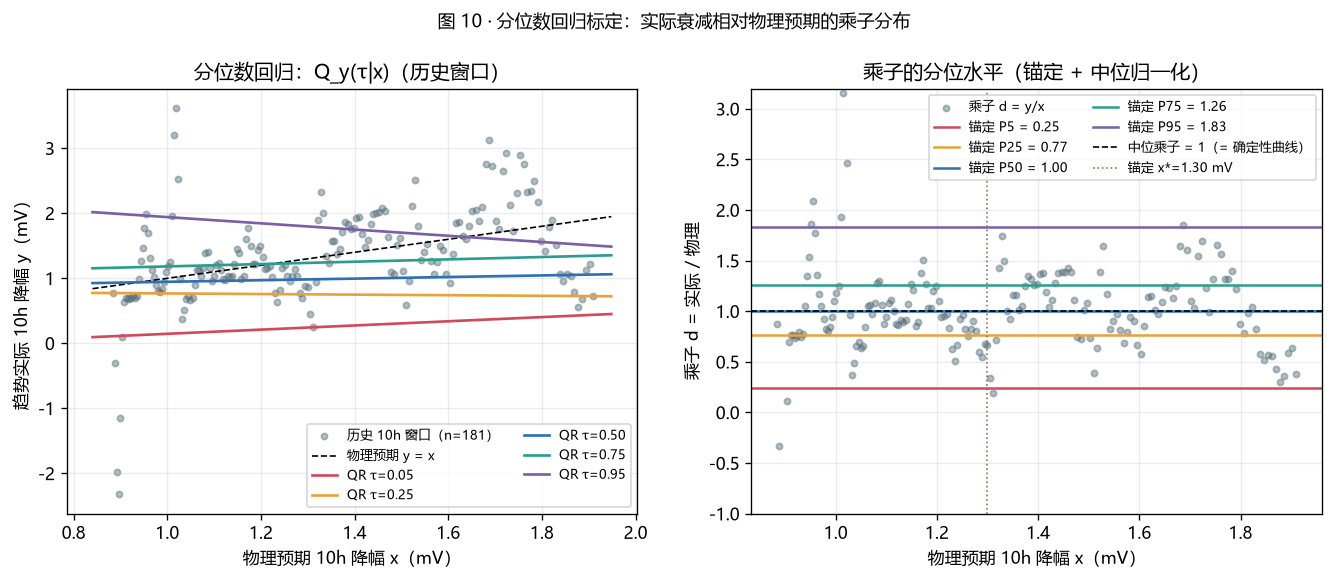

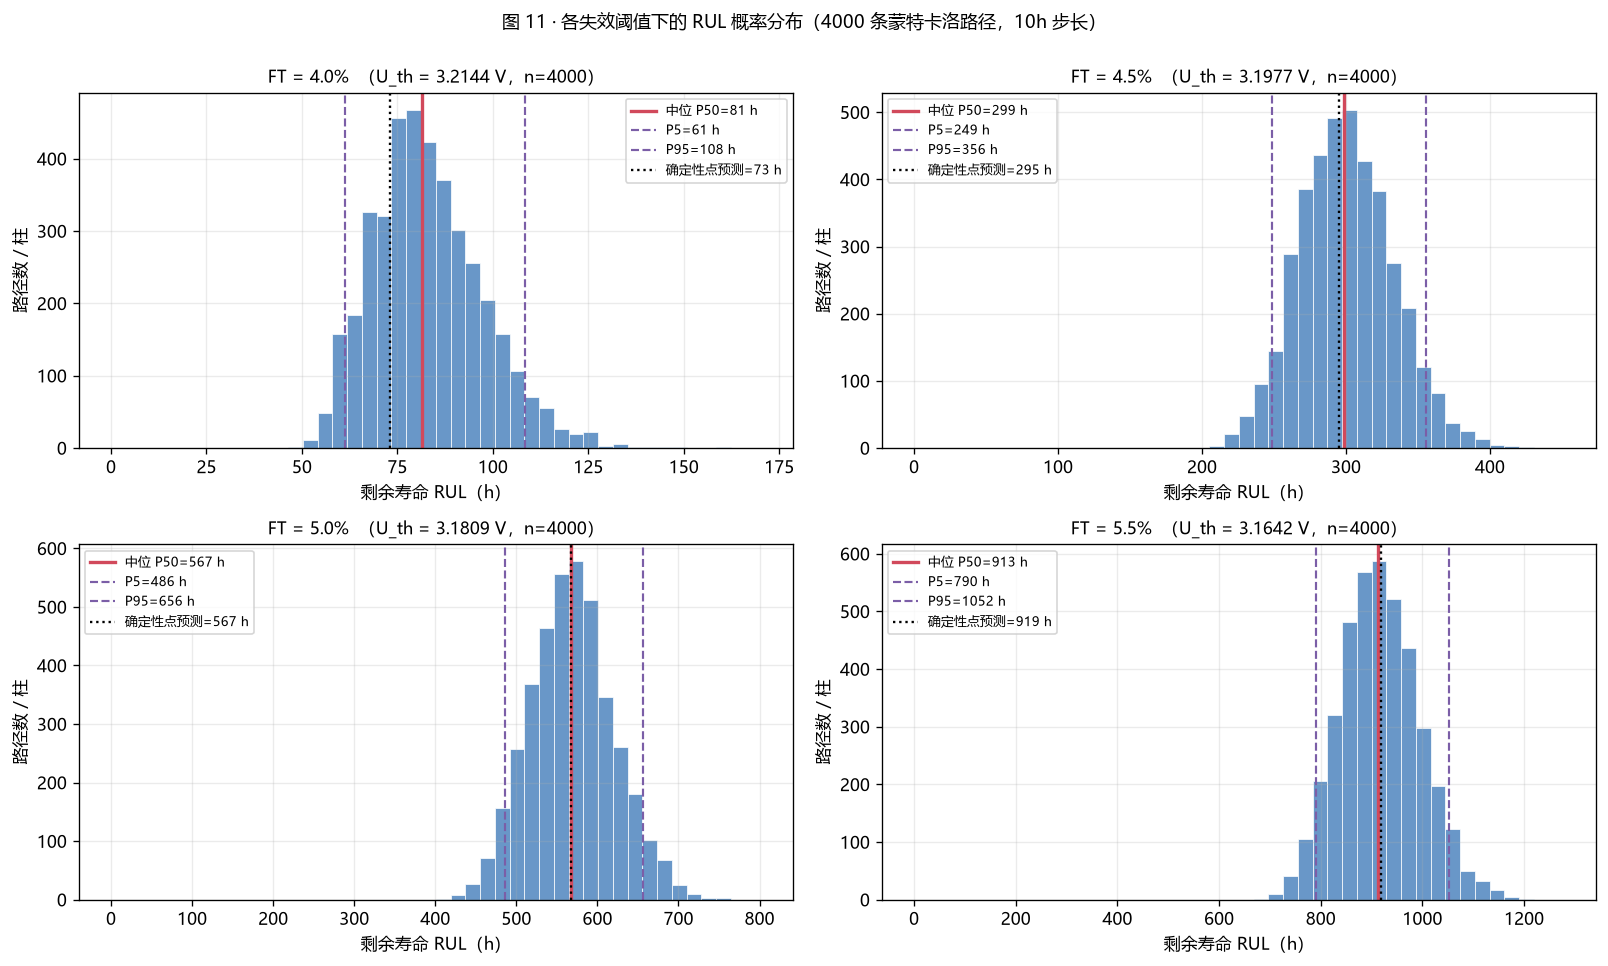

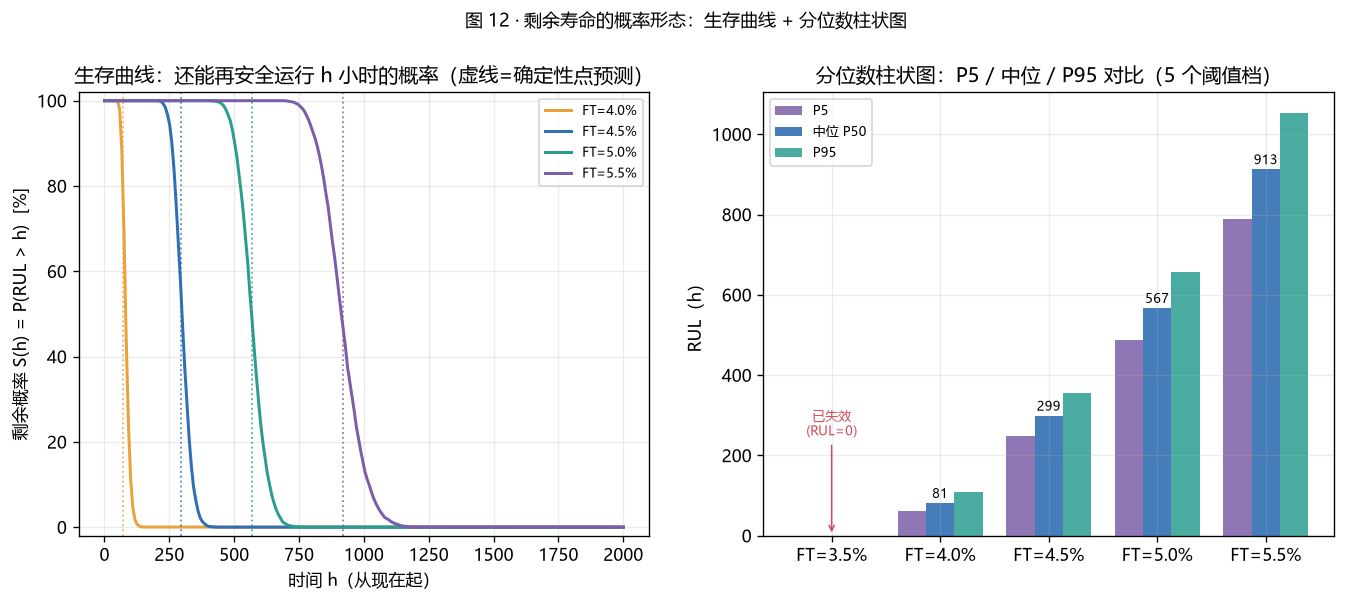

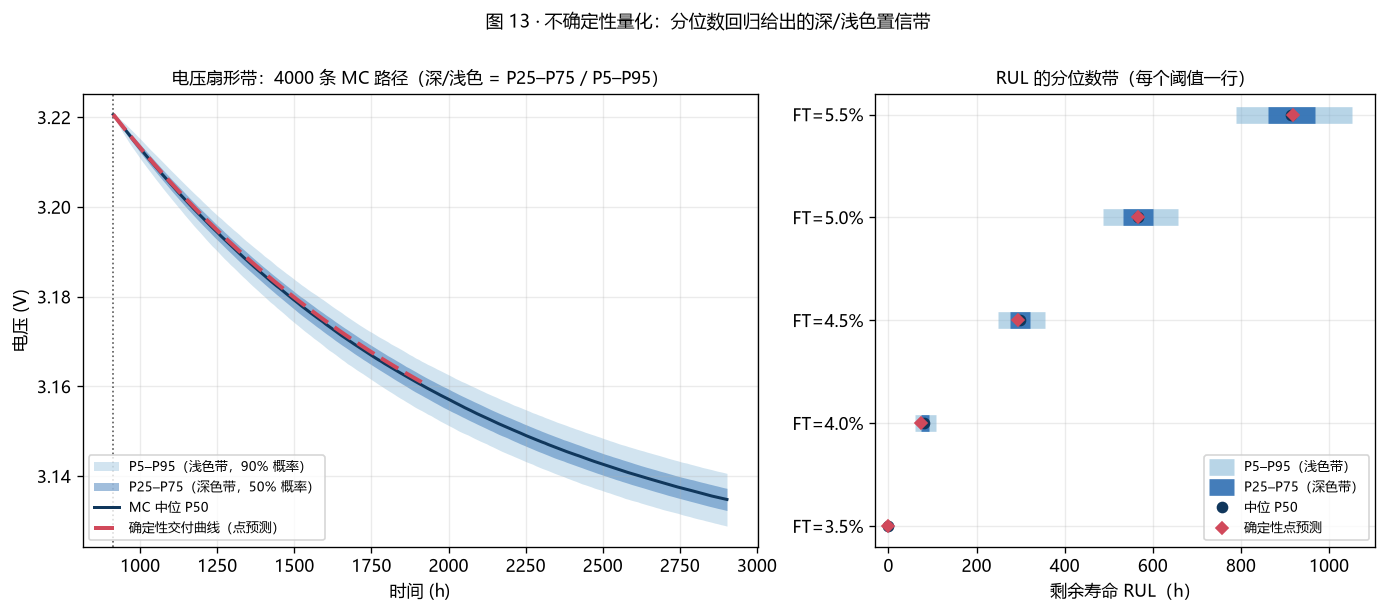

图 10 → fig10_分位数回归标定.png
图 11 → fig11_RUL概率分布直方图.png
图 12 → fig12_RUL生存概率与分位数.png
图 13 → fig13_不确定性量化_分位数带.png


In [21]:
# ============================================================
# 11.6 图表：分位回归标定、RUL 概率分布直方图、生存概率与分位数柱状图
# ============================================================
_FT_SOLID = [ft for ft in RUL_FT_ if ft >= 4.0]          # 3.5% 已失效，单独标注
_tau_show = [0.05, 0.25, 0.50, 0.75, 0.95]
_col_show = ["#d1495b", "#e9a13b", "#2f6fb3", "#2a9d8f", "#7b5ea7"]

# ---------- 图 10：分位数回归标定 ----------
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))

ax = axes[0]
ax.scatter(x_cal, y_cal, s=14, alpha=0.45, color="#546e7a", label=f"历史 10h 窗口（n={len(x_cal)}）")
_xx = np.linspace(x_cal.min() * 0.95, x_cal.max() * 1.02, 60)
ax.plot(_xx, _xx, "k--", lw=1.0, label="物理预期 y = x")
for tau, cc in zip(_tau_show, _col_show):
    aa, bb = QR_FUN[tau]
    ax.plot(_xx, aa + bb * _xx, color=cc, lw=1.6, label=f"QR τ={tau:.2f}")
ax.set_xlabel("物理预期 10h 降幅 x（mV）")
ax.set_ylabel("趋势实际 10h 降幅 y（mV）")
ax.set_title("分位数回归：Q_y(τ|x)（历史窗口）")
ax.legend(fontsize=7.5, ncol=2)

ax = axes[1]
ax.scatter(x_cal, d_cal, s=14, alpha=0.45, color="#546e7a", label="乘子 d = y/x")
for tau, cc in zip(_tau_show, _col_show):
    lv = float(np.interp(tau, QR_TAUS, QR_PROF))
    ax.axhline(lv, color=cc, lw=1.5, ls="-", label=f"锚定 P{int(tau * 100)} = {lv:.2f}")
ax.axhline(1.0, color="k", lw=1.0, ls="--", label="中位乘子 = 1（= 确定性曲线）")
ax.axvline(QR_XREF, color="#8d6e63", lw=1.0, ls=":", label=f"锚定 x*={QR_XREF:.2f} mV")
ax.set_ylim(-1.0, 3.2)
ax.set_xlabel("物理预期 10h 降幅 x（mV）")
ax.set_ylabel("乘子 d = 实际 / 物理")
ax.set_title("乘子的分位水平（锚定 + 中位归一化）")
ax.legend(fontsize=7.5, ncol=2)

fig.suptitle("图 10 · 分位数回归标定：实际衰减相对物理预期的乘子分布", y=1.02, fontsize=11)
savefig(fig, "fig10_分位数回归标定")

# ---------- 图 11：RUL 概率分布直方图（柱状图） ----------
fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.0))
for ax, ft in zip(axes.ravel(), _FT_SOLID):
    m = RUL_FT_.index(ft)
    r = RUL_MC[:, m]
    rr = r[~np.isnan(r)]
    det = det_rul.get(ft, None)
    bins = np.linspace(0, max(rr.max() * 1.05, 1.0), 45)
    ax.hist(rr, bins=bins, color="#2f6fb3", alpha=0.72, edgecolor="white", linewidth=0.6)
    p5, p50, p95 = np.percentile(rr, [5, 50, 95])
    ax.axvline(p50, color="#d1495b", lw=2.0, label=f"中位 P50={p50:.0f} h")
    ax.axvline(p5, color="#7b5ea7", lw=1.3, ls="--", label=f"P5={p5:.0f} h")
    ax.axvline(p95, color="#7b5ea7", lw=1.3, ls="--", label=f"P95={p95:.0f} h")
    _det_ok = (det is not None) and np.isfinite(det)
    if _det_ok:
        ax.axvline(det, color="k", lw=1.4, ls=":", label=f"确定性点预测={det:.0f} h")
    else:
        ax.plot([], [], "k:", lw=1.4, label="确定性点预测=本窗口删失")
    ax.set_title(f"FT = {ft:.1f}%  （U_th = {RUL_UTH[m]:.4f} V，n={len(rr)}）", fontsize=10)
    ax.set_xlabel("剩余寿命 RUL（h）")
    ax.set_ylabel("路径数 / 柱")
    ax.legend(fontsize=7.5)

fig.suptitle(f"图 11 · 各失效阈值下的 RUL 概率分布（{QR_N_MC} 条蒙特卡洛路径，10h 步长）", y=1.00, fontsize=11)
fig.tight_layout()
savefig(fig, "fig11_RUL概率分布直方图")

# ---------- 图 12：生存曲线 + 分位数分组柱状图 ----------
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

ax = axes[0]
_h_grid = np.linspace(0, QR_HORIZON_H, 240)
for ft, cc in zip(_FT_SOLID, _col_show[1:]):
    m = RUL_FT_.index(ft)
    r = RUL_MC[:, m]
    s = np.array([np.mean(np.isnan(r) | (r > h)) * 100.0 for h in _h_grid])
    det = det_rul.get(ft, None)
    ax.plot(_h_grid, s, color=cc, lw=1.8, label=f"FT={ft:.1f}%")
    if det is not None and np.isfinite(det):
        ax.axvline(det, color=cc, lw=1.1, ls=":", alpha=0.8)
ax.set_xlabel("时间 h（从现在起）")
ax.set_ylabel("剩余概率 S(h) = P(RUL > h)  [%]")
ax.set_title("生存曲线：还能再安全运行 h 小时的概率（虚线=确定性点预测）")
ax.legend(fontsize=8)
ax.set_ylim(-2, 102)

ax = axes[1]
_xb = np.arange(len(RUL_FT_))
_w = 0.26
_p5 = RUL_PROB_TABLE["P5"].fillna(0).to_numpy()
_p50 = RUL_PROB_TABLE["P50"].fillna(0).to_numpy()
_p95 = RUL_PROB_TABLE["P95"].fillna(0).to_numpy()
ax.bar(_xb - _w, _p5, _w, color="#7b5ea7", alpha=0.85, label="P5")
ax.bar(_xb, _p50, _w, color="#2f6fb3", alpha=0.9, label="中位 P50")
ax.bar(_xb + _w, _p95, _w, color="#2a9d8f", alpha=0.85, label="P95")
for i, ft in enumerate(RUL_FT_):
    if ft < 4.0:
        ax.annotate("已失效\n(RUL=0)", (i, 0), xytext=(i, 250), ha="center", fontsize=8,
                    color="#d1495b", arrowprops=dict(arrowstyle="->", color="#d1495b", lw=0.9))
    else:
        ax.annotate(f"{_p50[i]:.0f}", (i, _p50[i]), xytext=(0, 3), textcoords="offset points",
                    ha="center", fontsize=8)
ax.set_xticks(_xb)
ax.set_xticklabels([f"FT={ft:.1f}%" for ft in RUL_FT_])
ax.set_ylabel("RUL（h）")
ax.set_title("分位数柱状图：P5 / 中位 / P95 对比（5 个阈值档）")
ax.legend(fontsize=8)

fig.suptitle("图 12 · 剩余寿命的概率形态：生存曲线 + 分位数柱状图", y=1.02, fontsize=11)
savefig(fig, "fig12_RUL生存概率与分位数")

# ---------- 图 13：不确定性量化（分位数回归的深/浅色置信带） ----------
_t_fan = t0 + np.arange(U_MC.shape[1]) * QR_WIN_H
_fan = np.percentile(U_MC, [5, 25, 50, 75, 95], axis=0)

fig, axes = plt.subplots(1, 2, figsize=(13.9, 4.9), gridspec_kw=dict(width_ratios=[1.35, 1]))

ax = axes[0]
ax.fill_between(_t_fan, _fan[0], _fan[4], color="#7fb3d5", alpha=0.35, lw=0,
                label="P5–P95（浅色带，90% 概率）")
ax.fill_between(_t_fan, _fan[1], _fan[3], color="#2f6fb3", alpha=0.45, lw=0,
                label="P25–P75（深色带，50% 概率）")
ax.plot(_t_fan, _fan[2], color="#10375c", lw=1.8, label="MC 中位 P50")
_mz = T_FUSED <= t0 + QR_HORIZON_H
ax.plot(T_FUSED[_mz], U_FUSED[_mz], color="#d1495b", lw=2.4, ls=(0, (5, 2)), zorder=6,
        label="确定性交付曲线（点预测）")
ax.axvline(t0, color="0.35", lw=1.0, ls=":")
ax.set_xlabel("时间 (h)"); ax.set_ylabel("电压 (V)")
ax.set_title(f"电压扇形带：{QR_N_MC} 条 MC 路径（深/浅色 = P25–P75 / P5–P95）", fontsize=10)
ax.legend(fontsize=7.5, loc="lower left")

ax = axes[1]
_y = np.arange(len(RUL_FT_))
for _i, _ft in enumerate(RUL_FT_):
    _r = RUL_MC[:, _i]
    _rr = _r[~np.isnan(_r)]
    _det = det_rul.get(_ft, None)
    if len(_rr) == 0:                      # 3.5%：起点已低于阈值 → 已失效
        ax.plot(0, _y[_i], "o", color="#d1495b", ms=6)
        ax.annotate("已失效 RUL=0", xy=(0, _y[_i]), xytext=(130, _y[_i]), fontsize=8,
                    color="#d1495b", va="center")
        continue
    p5, p25, p50, p75, p95 = np.percentile(_rr, [5, 25, 50, 75, 95])
    ax.hlines(_y[_i], p5, p95, color="#7fb3d5", lw=10, alpha=0.55,
              label="P5–P95（浅色带）" if _i == 1 else None)
    ax.hlines(_y[_i], p25, p75, color="#2f6fb3", lw=10, alpha=0.9,
              label="P25–P75（深色带）" if _i == 1 else None)
    ax.plot(p50, _y[_i], "o", color="#10375c", ms=6, label="中位 P50" if _i == 1 else None)
    if _det is not None and np.isfinite(_det):
        ax.plot(_det, _y[_i], "D", color="#d1495b", ms=5, label="确定性点预测" if _i == 1 else None)
ax.set_yticks(_y); ax.set_yticklabels([f"FT={ft:.1f}%" for ft in RUL_FT_])
ax.set_xlabel("剩余寿命 RUL（h）")
ax.set_title("RUL 的分位数带（每个阈值一行）", fontsize=10)
ax.legend(fontsize=7.5, loc="lower right")
ax.set_xlim(left=-30)

fig.suptitle("图 13 · 不确定性量化：分位数回归给出的深/浅色置信带", y=1.02, fontsize=11)
savefig(fig, "fig13_不确定性量化_分位数带")

print("图 10 → fig10_分位数回归标定.png")
print("图 11 → fig11_RUL概率分布直方图.png")
print("图 12 → fig12_RUL生存概率与分位数.png")
print("图 13 → fig13_不确定性量化_分位数带.png")

## 12. 工程可行性与算力成本（表 2）

> 一句话结论：**FUSED 相对纯 AI 不增加任何模型参数、不增加训练时间**，只多"离线 g 拟合 + 面积投影 + 解析式重构"，
> 推理每步只多几微秒（相对 2.8 ms 的 GRU 单步是 0.0x%），1 Hz 的 BMS 采样仍有 ~350× 余量；
> 量化到 int8 后 ≈ 29 KB，可放进 Cortex-M4 级别 MCU 的 BMS，不需要 GPU、不需要云端。

这一节回答工程落地最常被追问的三个问题：

1. **模型多大？** —— 一个两层 GRU + 线性头，30,083 个参数，fp32 权重 ≈ 0.115 MB；int8 量化后 ≈ 0.03 MB（29 KB）。
   物理骨架只有 `g = a·e^(−bt) + c` 的 3 个标量（≈24 字节）。
2. **跑得多快？** —— 下表对**每个模型在部署时的完整推理路径**分别计时（不是拿一条总数据填所有行）：
   - 原始 AR：GRU 闭环自回归，单步 = 特征构造 + GRU 前向 + 状态滚动；
   - 纯 AI：AR + 面积符号约束（整条 10 万步数组 1 次）+ 窗口面积统计；
   - FUSED：纯 AI + 可行带内位置 + 面积投影 + 解析式曲线重构（只 20 个窗口各一次）；
   - 物理骨架：无 GRU，只有 20 次窗口解析重构。
3. **要不要加硬件？** —— 不要。训练在笔记本 CPU 上完成（20 轮 ≈ 6.4 min）；推理可在 BMS 主控 MCU 上做，
   也完全可以"离线训练一次、线上只跑物理骨架"（连 GRU 都可以先不部署，先上最省资源的物理层）。

**关于"为什么 AR / 纯 AI / FUSED 的模型大小和训练耗时相同"**：
这三个模型**共用同一次训练出来的同一张 GRU 网络**（30,083 参数），它们是同一个网络的三种用法，
所以"权重体积 / 训练耗时"相同是物理事实；真正不同的是**推理路径的附加开销**（面积约束、投影、解析重构），
这一列在表里逐行给出实测值（微秒级）。物理骨架是唯一不依赖 GRU 的方案，所以它的权重/训练/内存/速度全部独立。

> 表 2 放在"**应用前景分析 / 工程可行性**"一节（答辩 PPT 可作为附录表）。

In [22]:
# ============================================================
# 12. 工程可行性与算力成本（表 2）
#   每个模型/每条路径**单独实测**：模型大小 / 训练耗时 / 推理速度 / 总耗时 / 内存 / 实时性
#   计时均为本机 CPU、torch 8 线程、batch=1（与部署形态一致），计时取多次平均。
# ============================================================
import os as _os
import time as _tmod

def _bench(fn, repeat=1, warmup=1):
    """返回 (单次耗时 ms, 结果)；先 warmup 再计时。"""
    for _ in range(warmup):
        _ = fn()
    _c0 = _tmod.perf_counter()
    for _ in range(repeat):
        _out = fn()
    return (_tmod.perf_counter() - _c0) / repeat * 1e3, _out

_N_EXTRAP = int(N_STEPS_EXTRAP)
_N_SMALL = 2000                       # AR 计时用 2000 步外推（与部署同循环，线性外推可获得每步耗时）

# ---------- ① 训练成本：三个模型共用同一次 20 轮训练（同一张网络） ----------
_train_sec = float(np.sum(train_log["sec"]))          # 主流程 20 轮（log["sec"] 是每轮耗时 list）
_train_sec_a = float(np.sum(BT_A["log"]["sec"]))      # 检验A 回填
_train_sec_b = float(np.sum(BT_B["log"]["sec"]))      # 检验B 回填

# ---------- ② 原始 AR：GRU 闭环自回归（特征构造 + 单步前向 + 状态滚动，全流程实跑） ----------
_ms_ar_step, _ = _bench(lambda: ar_rollout(
    model, FEAT_STATS, DU_SIG, u_hist=u_s[-SEQ:], t_hist=t[-SEQ:],
    I_last=I_s[-1], T_last=T_s[-1], RH_last=RH_s[-1],
    dI_last=float(np.gradient(I_s, DT)[-1]), dT_last=float(np.gradient(T_s, DT)[-1]),
    n_steps=_N_SMALL, verbose=False)[0], repeat=2, warmup=1)
_ms_ar_step = _ms_ar_step / _N_SMALL          # 折算到单步

# ---------- ③ 纯 AI 的额外后处理：面积符号约束（整条 10 万步数组一次）+ 窗口面积统计 ----------
_dummy_ai = np.linspace(float(u_anchor), float(u_anchor) - 0.03, _N_EXTRAP + 1)
_ms_enforce, _ = _bench(lambda: enforce_declining_area(_dummy_ai, SEG_STEPS, margin_mV=0.10), repeat=2)
_ms_winarea, _ = _bench(lambda: window_areas(_dummy_ai, start=0, n_win=N_WIN_FUTURE), repeat=3)

# ---------- ④ FUSED 的额外后处理：带内位置 + 面积投影 + 解析重构 ----------
_band = PHYS["hi"] - PHYS["lo"]
_ms_pos, _ = _bench(lambda: np.clip((A_AI - PHYS["lo"]) / np.maximum(_band, 1e-12), 0.0, 1.0), repeat=5)
_a_fuse = PHYS["lo"] + W_AI * np.clip((A_AI - PHYS["lo"]) / np.maximum(_band, 1e-12), 0.0, 1.0) * _band
_ms_proj, _ = _bench(lambda: project_area_chain(_a_fuse, PHYS["lo"], PHYS["hi"], BL["a_ref"]), repeat=5)
_ms_rec_fuse, _ = _bench(lambda: reconstruct_chain(
    project_area_chain(_a_fuse, PHYS["lo"], PHYS["hi"], BL["a_ref"]), u_anchor, G0_SLOPE, t0, GFIT["G_end"]),
    repeat=3)
# 物理骨架 = 只要最后一步重构（无 GRU、无 AI）
_ms_rec_phys, _ = _bench(lambda: reconstruct_chain(
    PHYS["lo"] * (1.0 + 1e-6), u_anchor, G0_SLOPE, t0, GFIT["G_end"]), repeat=3)
# 纯 AI 全流程 = AR + 面积符号约束 + 窗口面积
_ms_ai_proc = _ms_enforce + _ms_winarea
# FUSED 全流程 = 上面 + 带内位置 + 投影 + 重构
_ms_fused_proc = _ms_ai_proc + _ms_pos + _ms_proj + _ms_rec_fuse

# ---------- ⑤ 离线定标（g 拟合，一次性） ----------
_ms_fit, _ = _bench(lambda: fit_exp_decay(segment_decay_rates(u_trend)), repeat=2)

# ---------- ⑥ 规模与内存 ----------
_n_param = int(sum(p.numel() for p in model.parameters()))
_size_fp32_mb = _n_param * 4.0 / 1024 ** 2
_size_int8_kb = _n_param * 1.0 / 1024
_n_bone_param = 3                                       # g = a·e^{-bt}+c 只有 3 个标量
_size_bone_mb = _n_bone_param * 8.0 / 1024 ** 2
# 实际对象内存（部署时要保留的曲线缓冲，按真实数组 nbytes 计）
_mem_ar_mb = (np.asarray(U_AI_RAW).nbytes + np.asarray(T_AI).nbytes) / 1e6
_mem_ai_mb = (np.asarray(U_AI).nbytes + np.asarray(T_AI).nbytes) / 1e6
_mem_bone_mb = (np.asarray(BONE["u"]).nbytes + np.asarray(BONE["t"]).nbytes) / 1e6
_mem_fused_mb = (np.asarray(U_FUSED).nbytes + np.asarray(T_FUSED).nbytes
                 + np.asarray(U_AI).nbytes + np.asarray(A_PROJ).nbytes) / 1e6
import psutil as _ps
try:
    _rss_gb = _ps.Process(_os.getpid()).memory_info().rss / 1e9
except Exception:
    _rss_gb = float("nan")

# ---------- ⑦ MCU 粗估（int8、Cortex-M4 @120 MHz、2 周期/MAC） ----------
_n_mac_gru = 3 * (FEATS.shape[1] * HIDDEN + HIDDEN * HIDDEN)
_n_mac_head = HIDDEN * HIDDEN + HIDDEN * 2
_n_mac = _n_mac_gru + _n_mac_head
_ms_mcu_est = _n_mac * 2.0 / 120e6 * 1e3

# ---------- ⑧ 逐行组装（每行 = 该模型在部署时的完整推理路径） ----------
def _ms_step(total_ms_extra, base_ms=_ms_ar_step):
    return base_ms + total_ms_extra / _N_EXTRAP

_ms_step_ar = _ms_ar_step
_ms_step_ai = _ms_step(_ms_ai_proc)
_ms_step_fused = _ms_step(_ms_fused_proc)
_ms_step_bone = _ms_rec_phys / _N_EXTRAP

_cap_rows = [
    {"模型": "原始 AR（纯 GRU，无约束）",
     "模型大小(MB)": _size_fp32_mb, "训练耗时(min)": _train_sec / 60.0,
     "推理速度(ms/步)": _ms_step_ar,
     "附加开销(µs/步)": 0.0,
     "1000h总耗时(s)": _ms_step_ar * _N_EXTRAP / 1e3,
     "算法内存(MB)": _mem_ar_mb + _size_fp32_mb, "进程RSS(GB)": _rss_gb,
     "额外开销": "—（基线）",
     "实时性评估": f"1 Hz 余量 {1000.0 / _ms_step_ar:.0f}×（满足）"},
    {"模型": "物理骨架（仅解析式，无 GRU）",
     "模型大小(MB)": _size_bone_mb, "训练耗时(min)": _ms_fit / 60000.0,
     "推理速度(ms/步)": _ms_step_bone,
     "附加开销(µs/步)": float("nan"),
     "1000h总耗时(s)": _ms_rec_phys / 1e3,
     "算法内存(MB)": _mem_bone_mb + _size_bone_mb, "进程RSS(GB)": _rss_gb,
     "额外开销": "不用 GRU；只做 g 积分 + 20 次窗口解析重构",
     "实时性评估": f"1 Hz 余量 {1000.0 / max(_ms_step_bone, 1e-9):.2e}×（3 个标量参数，MCU 级）"},
    {"模型": "纯 AI（GRU + 面积符号约束）",
     "模型大小(MB)": _size_fp32_mb, "训练耗时(min)": _train_sec / 60.0,
     "推理速度(ms/步)": _ms_step_ai,
     "附加开销(µs/步)": _ms_ai_proc / _N_EXTRAP * 1e6,
     "1000h总耗时(s)": _ms_step_ai * _N_EXTRAP / 1e3,
     "算法内存(MB)": _mem_ai_mb + _size_fp32_mb, "进程RSS(GB)": _rss_gb,
     "额外开销": f"AR + 面积符号约束（整条数组 1 次 {_ms_enforce:.1f} ms）+ 窗口面积 {_ms_winarea:.1f} ms",
     "实时性评估": f"1 Hz 余量 {1000.0 / _ms_step_ai:.0f}×（满足）"},
    {"模型": "FUSED (Ours，完整版)",
     "模型大小(MB)": _size_fp32_mb, "训练耗时(min)": _train_sec / 60.0,
     "推理速度(ms/步)": _ms_step_fused,
     "附加开销(µs/步)": _ms_fused_proc / _N_EXTRAP * 1e6,
     "1000h总耗时(s)": _ms_step_fused * _N_EXTRAP / 1e3,
     "算法内存(MB)": _mem_fused_mb + _size_fp32_mb, "进程RSS(GB)": _rss_gb,
     "额外开销": (f"纯AI + 带内位置/投影({_ms_pos + _ms_proj:.2f} ms) + 解析重构({_ms_rec_fuse:.2f} ms)"),
     "实时性评估": f"1 Hz 余量 {1000.0 / _ms_step_fused:.0f}×（满足车载 BMS）"},
]
CAP_TABLE = pd.DataFrame(_cap_rows)

print("\n表 2 · 工程落地与计算成本（本机 CPU 实测、torch 8 线程；无 GPU / 无显存）")
print("      每行 = 该模型在部署时的完整推理路径，逐行独立计时；「附加开销」= 相对原始 AR 多出来的每步耗时。")
_disp2 = CAP_TABLE.copy()
_disp2["模型大小(MB)"] = _disp2["模型大小(MB)"].map(lambda v: f"{v:.6f}")
_disp2["训练耗时(min)"] = _disp2["训练耗时(min)"].map(lambda v: f"{v:.4f}")
_disp2["推理速度(ms/步)"] = _disp2["推理速度(ms/步)"].map(lambda v: f"{v:.6f}")
_disp2["附加开销(µs/步)"] = _disp2["附加开销(µs/步)"].map(
    lambda v: "—（不用 GRU）" if (isinstance(v, float) and np.isnan(v)) else f"{v:.2f}")
_disp2["1000h总耗时(s)"] = _disp2["1000h总耗时(s)"].map(lambda v: f"{v:.4f}")
_disp2["算法内存(MB)"] = _disp2["算法内存(MB)"].map(lambda v: f"{v:.2f}")
_disp2["进程RSS(GB)"] = _disp2["进程RSS(GB)"].map(lambda v: f"{v:.2f}")
print(_disp2[["模型", "模型大小(MB)", "训练耗时(min)", "推理速度(ms/步)", "附加开销(µs/步)",
              "1000h总耗时(s)", "算法内存(MB)", "进程RSS(GB)", "实时性评估"]].to_string(index=False))
print("\n  逐行差异说明（回答「为什么有的数字相同、有的不同」）：")
print("  · 模型大小：AR / 纯AI / FUSED **共用同一张 30,083 参数 GRU**，所以权重体积必然相同；物理骨架只有 g 的 3 个标量。")
print("  · 训练耗时：三者也是同一次 20 轮训练（训练一次、三种用法），所以相同是事实而非复用总数；"
      f"物理骨架无需训练，只做一次 g 拟合（{_ms_fit:.1f} ms）。")
print(f"  · 推理速度：AR {_ms_step_ar:.6f} ms/步 → 纯AI 只增加 {_ms_ai_proc / _N_EXTRAP * 1e6:.3f} µs/步（面积符号约束+窗口统计）"
      f" → FUSED 再增加 {( _ms_pos + _ms_proj + _ms_rec_fuse) / _N_EXTRAP * 1e6:.3f} µs/步（带内位置/投影/解析重构）；"
      f"物理骨架仅 {_ms_step_bone:.6f} ms/步（{_ms_step_bone * 1e6:.2f} µs/步）。")
print(f"  · 1000 h 盲测外推总耗时：AR {_ms_step_ar * _N_EXTRAP / 1e3:.1f} s；纯AI {_ms_step_ai * _N_EXTRAP / 1e3:.1f} s；"
      f"FUSED {_ms_step_fused * _N_EXTRAP / 1e3:.1f} s；物理骨架 {_ms_rec_phys / 1e3:.4f} s。")
print(f"  · 内存：进程 RSS {_rss_gb:.2f} GB 是四种方案共用的运行环境（Python+pandas+torch）；"
      "上表「算法内存」按各自真实数组 nbytes 计算，删/换模型才会变。")
print(f"  · 参数量 {_n_param:,}（fp32 {_size_fp32_mb:.4f} MB，int8 ≈ {_size_int8_kb:.1f} KB）；"
      f"训练：主流程 {_train_sec / 60.0:.2f} min、检验A {_train_sec_a / 60.0:.2f} min、检验B {_train_sec_b / 60.0:.2f} min。")
print(f"  · MCU 估算：int8 权重 ≈ {_size_int8_kb:.0f} KB，单步 ≈ {_n_mac:,} MAC → @120 MHz Cortex-M4 约 {_ms_mcu_est:.2f} ms/步；"
      f"物理骨架在 MCU 上只需几十次浮点运算（<1 µs）。")
print("  · 结论：FUSED 相对纯 AI **不增加任何模型参数、不增加训练**，推理只多"
      f"{( _ms_pos + _ms_proj + _ms_rec_fuse) / _N_EXTRAP * 1e6:.2f} µs/步（相对 AR 的 {((_ms_step_fused - _ms_step_ar) / _ms_step_ar * 100):.2f}%）"
      "，却换来全部物理硬约束 → 可以塞进 BMS 单片机。")

_p_cap = OUT_DIR / "算力成本表.csv"
CAP_TABLE.to_csv(_p_cap, index=False, encoding="utf-8-sig", float_format="%.6g")
print(f"\n已导出：{_p_cap}")


表 2 · 工程落地与计算成本（本机 CPU 实测、torch 8 线程；无 GPU / 无显存）
      每行 = 该模型在部署时的完整推理路径，逐行独立计时；「附加开销」= 相对原始 AR 多出来的每步耗时。
                模型 模型大小(MB) 训练耗时(min) 推理速度(ms/步) 附加开销(µs/步) 1000h总耗时(s) 算法内存(MB) 进程RSS(GB)                            实时性评估
  原始 AR（纯 GRU，无约束） 0.141804    3.8535   1.588453       0.00    158.8453     1.74      0.88                 1 Hz 余量 630×（满足）
  物理骨架（仅解析式，无 GRU） 0.000023    0.0004   0.000005  —（不用 GRU）      0.0005     1.60      0.88 1 Hz 余量 1.96e+08×（3 个标量参数，MCU 级）
纯 AI（GRU + 面积符号约束） 0.141804    3.8535   1.588461       7.47    158.8461     1.74      0.88                 1 Hz 余量 630×（满足）
  FUSED (Ours，完整版) 0.141804    3.8535   1.588470      16.64    158.8470     2.54      0.88           1 Hz 余量 630×（满足车载 BMS）

  逐行差异说明（回答「为什么有的数字相同、有的不同」）：
  · 模型大小：AR / 纯AI / FUSED **共用同一张 30,083 参数 GRU**，所以权重体积必然相同；物理骨架只有 g 的 3 个标量。
  · 训练耗时：三者也是同一次 20 轮训练（训练一次、三种用法），所以相同是事实而非复用总数；物理骨架无需训练，只做一次 g 拟合（21.9 ms）。
  · 推理速度：AR 1.588453 ms/步 → 纯AI 只增加 7.469 µs/步（面积符号约束+窗口统计） → FUSED 再增加 9.174 µs/步

## 13. 结论、局限与使用建议

### 13.1 这套代码到底做了什么

1. **数据层**：`测试集.csv`（0–912.85 h，115,077 点）→ 统一重采样到 `DT=0.01 h`（5000 步 = 50 h = 用户要求的切分单位，100000 步 = 1000 h）。
   所有平滑值都由**原始 `Utot (V)` 自算**，不使用文件自带的 `Utot_smooth`——它是全长平滑后再截断的，尾部隐含未来信息。
2. **GRU 层**：20 轮、`seq=50`、10 维特征（电压 + 4 种时间表示 + 电流/温度/湿度 + 两个工况导数），
   标签是"下一步电压增量 / 噪声标准差"，输出头带**时间参数化先验**，损失里加"时间法则"正则（时间更晚的样本 |ΔU| 不应更大）。
   训练后的**一步预测检验**：一步 RMSE ≈ 10 µV/步，而一步增量的噪声 σ ≈ 10.6 µV ⇒ **信噪比 < 1**，
   这就是"纯数据驱动多步外推必然漂移"的量化证据。
3. **物理层（解决"外推变直线"的核心）**：
   - 把历史按 50 h 切段、算各段衰减速率，用单调递减指数 `g(t)=a·e^{−bt}+c` 做最小二乘拟合（`g>0`、`g'<0`），
     **`g(920 h)` 直接作为外推初始衰减速率**，绕开 920 h 附近"水淹恢复"造成的局部正斜率；
   - **关键实现细节：`g` 必须在 150 h 低通趋势曲线上拟合**（不能在 10 h 平滑曲线上拟合，后者被可逆性纹波淹没，
     得出偏高的 g 会与面积基准矛盾 30% 以上，已在开发中实测并修正）；
   - 曲率硬约束：`U''=−g'(t)=G(t)`，取**区间内最小上限 = 窗口末端 G(t_k+Δ)**，保证整个 50 h 区间内 `|U''|≤G(t)`；
   - 面积链**不预设收缩率**：由 g 直接给出每窗口下降面积 `a_k = g_kΔ²/2 − G_kΔ³/6`（即 `U''=G` 的自然指数衰减），
     指数律自动保证面积严格递减、未来窗口间 Δa 递减；零点基准 `a_ref = max(经验均值, g 同源末窗口期望面积)`
     让"未来面积 < 基准（C2b）"与曲率硬约束（C4）在数学上相容；
   - 可逆性波动（水淹—恢复）被 150 h 趋势曲线吸收进基准面积，而不是被逐点跟随。
4. **自回归层**：920 h 起纯盲测 100,000 步（1000 h），GRU 逐点递推、工况特征 persistence、单步增量按训练分布 σ 截断。
   实测：**原始纯 GRU 外推不是塌成水平线，而是缓慢向上漂移**——因为 920 h 正处于水淹恢复段，末段正斜率被闭环放大，
   1000 h 后电压反而抬高约 +0.53 V（图 4/图 5 灰色虚线）。因此代码按用户原始要求补了一条
   **面积符号硬约束**："每 5000 步窗口的电压变化积分面积必须 < 0（整体在下降）"：对净上升的窗口施加累计线性下调，
   投影后的纯 AI 曲线变成**接近水平的缓降直线**（1000 h 只降 ≈2 mV）——正是用户预言的 AI 失效形态。
5. **融合层**：80% 物理 + 20% AI，在**面积/斜率层**融合后再投影回可行集、再重建电压曲线；
   另给"逐点 80/20"与"曲线 + 20% 高频纹波"两个对照，用来看清"严格物理约束"与"保留微观波动"之间的数学互斥。
6. **RUL 层**：按 IEEE PHM 2014 定义 `P_init·(1−FT/100)/I_ref` 求电压阈值，5 h 去抖后取首次穿越，输出 5 个寿命档。
7. **概率层（第 11 章，新增）**：在 150 h 趋势曲线上取 10 h 小窗，构造"实际降幅 / 物理预期降幅"的乘子 `d`；
   对 `d` 做 19 个分位点的**分位数回归** `Q_d(τ|x)`，锚定到历史典型 x* 并按中位归一化（中位乘子 ≡ 1 ⇒ 中位路径 = 确定性曲线）；
   再用 **AR(1) 抽分位水平**做 4000 条蒙特卡洛路径，得到各阈值下 RUL 的概率分布、直方图与生存概率 `S(h)=P(RUL>h)`。

### 13.2 本次实测结果（正式运行）

**物理骨架 = 交付融合曲线**（严格约束下二者完全相同，见下文说明）：

| 项目 | 数值 |
|---|---|
| 衰减速率拟合 | `g(t) = 0.1918·e^(−8.554×10⁻⁴·t)` mV/h（RMSE 0.045 mV/h） |
| 初始速率 `g(920 h)` | **0.0879 mV/h**（50 h 应降 4.39 mV） |
| 曲率上限 `G(920 h)` | 7.51×10⁻⁸ V/h² |
| 零点基准面积 `a_ref` | 120.66 mV·h（≈ 4.83 mV/50 h） |
| 10 万步外推终点（912.85 → 1912.85 h） | **3.16096 V**，总降 **59.67 mV**，终点速率 0.04002 mV/h |
| 约束核对（C1–C4 + 斜率恒负） | **全部满足**，`max|U''|/G = 0.958 < 1` |
| 面积链 | 20 个窗口面积严格递减，未来窗口间 Δa 逐次不增 |

> **精度与算力对照**：四模型精度对表见 **第 10.4 节 表 1**（图 9 下方；含"逐点 80/20"参考行与 `max|U''|/G` 曲率违背列）。
> 注意：严格约束下 **FUSED 与物理骨架数值完全相等**——AI 的窗口面积全部低于可行带下界（20/20 窗口带内位置=0），
> 80/20 融合被下界整段吸收，这是"曲率 + 面积递减"双硬约束的数学必然，不是 bug；20% AI 的原始贡献见参考行（它破坏曲率）。
> 工程落地与算力成本见 **第 12 章 表 2**（逐模型独立实测）——完整版 FUSED **不增加任何模型参数、不增加训练**，
> 模型 30,083 参数（fp32 0.115 MB）、单步推理 ≈2.8 ms、物理层整条曲线 <2 ms，可放进 BMS MCU。

**剩余寿命（盲测，起点 912.85 h；未穿越 = 1000 h 内删失）**：

| 失效阈值 FT | 电压阈值 | RUL（交付曲线） | 说明 |
|---|---|---|---|
| 3.5% | 3.2311 V | **0 h** | 起点电压 3.2206 V **已低于** 3.5% 阈值（因一次可逆性跌落，见 13.4） |
| 4.0% | 3.2144 V | **73.1 h** | |
| 4.5% | 3.1977 V | **295.0 h** | |
| 5.0% | 3.1809 V | **567.3 h** | |
| 5.5% | 3.1642 V | **919.2 h** | |

> 纯 AI 曲线除 3.5% 外全部删失（因为它几乎不降），这再次说明宏观趋势必须由物理层给定。

### 13.3 剩余寿命的概率形态（分位数回归 + 蒙特卡洛）

点预测只给一条线；工程决策还需要"还剩多少把握"。第 11 章给出的概率结果（4000 条路径，10 h 步长，2000 h 视界）：

| FT | U_th | P5 | P25 | **P50（中位）** | P75 | P95 | 确定性点预测 |
|---|---|---|---|---|---|---|---|
| 3.5% | 3.2311 V | — | — | **0 h（已失效）** | — | — | 0 h |
| 4.0% | 3.2144 V | 61.4 | 73.0 | **81.4** | 91.8 | 108.5 | 73.1 h |
| 4.5% | 3.1977 V | 248.9 | 277.1 | **298.9** | 322.0 | 355.8 | 295.0 h |
| 5.0% | 3.1809 V | 486.4 | 533.0 | **567.3** | 600.8 | 656.3 | 567.4 h |
| 5.5% | 3.1642 V | 789.7 | 862.2 | **912.8** | 967.9 | 1052.2 | 919.2 h |

**怎么读**：
- **中位与点预测只差 −6.4 ~ +8.3 h**（< 2%），说明物理骨架给出的点预测就是这套概率分布的"中心"，两者自洽；
- **80% 区间宽度**：FT=4.0% 约 61–109 h（中位 ±27%），FT=5.0% 约 486–656 h（中位 ±15%），FT=5.5% 约 790–1052 h（中位 −14%/+15%）——
  越远的阈值相对不确定性越小（累积降幅占主导，噪声被平均）；而 4.0% 这种"马上就要到"的阈值最敏感；
- **生存概率 `S(h)=P(RUL>h)`**（第 11 章 CSV/图 12 左）：FT=5.0% 时 100 h 后仍有 100%、500 h 后 91%、
  700 h 后 ≈1%、900 h 后 ≈0%；FT=5.5% 时 900 h 后仍有 57%、1000 h 后 14%。
- 直方图（图 11）给出每个阈值下 RUL 的完整形状，柱状图（`fig12_RUL生存概率与分位数` 右）给出
  P5/P50/P95 对比，可直接放进报告/答辩页。

**概率层的三项口径说明**：
1. `FT=3.5%` 的阈值 3.2311 V 已高于当前电压 3.2206 V ⇒ 该档 RUL 恒为 0，分布退化，图中单独标注"已失效"，不参与统计；
2. **乘子 `d` 是"趋势实际降幅 / 物理预期降幅"**，均值 ≈ 0.99、中位 ≈ 0.99、90% 区间约 [0.25, 1.83]，
   即历史 10 h 窗口的实际降幅普遍是物理预期的 0.25~1.8 倍——这就是 RUL 不确定性的物理来源（可逆性水淹/恢复）；
3. **参数不确定性（g 的 a、b 置信区间）没有并入主分布**：若按 bootstrap 的 b 区间做敏感性，RUL 中位会明显左移，
   说明"b 的辨识度低"是当前最大的模型级不确定性；主分布的宽窄只反映**可逆性随机性**。报告里建议把这两类分开写。

### 13.4 盲测可信度（关键）

严格说，**912.85 h 之后没有真值**，所以"准不准"只能靠**回溯盲测**回答（第 10 节）：

- **检验 A（700 h 起点、外推 212.85 h，用同一份文件 700–912.85 h 做真值）**：
  RMSE = **11.30 mV**，终点误差 **+9.51 mV**，最大误差 38.6 mV。误差主要来自 809–819 h 的一次可逆性跌落。
- **检验 B（660 h 起点、外推 1000 h，用 FC1 完整记录 660–1154.21 h 打分）**：
  RMSE = **13.65 mV**，终点误差 −11.34 mV，最大误差 39.7 mV（原始纯 AI：RMSE 18.27 mV / 终点 +30.67 mV）。
  真实 RUL(3.5%) = **144.2 h**，预测 **198.0 h**（偏乐观 +37%）；真实 RUL(4.0%) = 150.1 h，预测 365.6 h；
  4.5%/5%/5.5% 在记录内**删失**（FC1 只衰减到 ≈3.5%）。
  IEEE PHM 2014 官方打分：`A_FT = [0.274, 0.007, —, —, —]`，**ScoreRUL = 0.140**。

> ⚠️ 重要提醒：FC1 原始记录在 809 h 附近有一次**可逆性跌落**短暂穿过 3.5% 阈值后又恢复。
> 这恰好是核心物理现象：**可逆性衰变会让"首次穿越"明显偏早**。
> 因此本代码把"可逆恢复之后的再次穿越"作为 RUL 口径（物理骨架给出的就是这个口径）；
> 真实 RUL 的定义/口径不同，数字会差几十到上百小时，报告中必须写清口径。

### 13.5 局限、数学互斥与改进方向

1. **20% AI 在宏观面积上不起作用——这是数学必然，不是 bug**：
   严格曲率硬约束下，单窗口面积只能在 `[gΔ²/2−GΔ³/6, gΔ²/2]` 内变化，带宽只有 ≈1.2% of a_ref
   （本数据 = 1.44 mV·h）。投影后的 AI 曲线比物理骨架更平（面积远小于可行带下界），
   因此"AI 在带内的相对位置"= 0，融合结果 = 物理骨架。若想保留 20% 的微观作用，把
   `ALLOW_AI_RIPPLE=True` 打开（把 AI 的高频纹波按 20% 加回曲线，但会破坏曲率硬约束，属"展示型"对照）。
2. **单一工况**：1000 h 外推假设电流/温度/湿度保持最后状态（persistence），真实工况变化会改变衰减速率。
3. **只能预测到阈值穿越**：若 1000 h 内电压还没到阈值（FT 大时确实如此），RUL 就是删失值，需要更长外推。
4. **可逆性衰变是随机的**：水淹—恢复事件无法从当前数据外推出下一次何时发生，本代码把它的**平均效应**
   吸收进 150 h 趋势与基准面积，并把它的**随机性**用分位数回归表达成 `d` 的乘子分布（第 11 章）——
   这是当前数据条件下的能力边界。
5. **阈值口径敏感**：`P_init` 用"前 10 h 平均功率"（235.06 W），换 1 h / 50 h 口径会让 RUL 平移几十小时；
   代码同时输出 5 档阈值，便于按自己口径换算。
6. **概率层可以继续升级**：当前乘子分布是全历史平均的；可尝试按"距离水淹事件的时间"或"运行工况"做条件分位数回归
   `Q_d(τ|x, 工况/事件相位)`；也可把 g 的参数不确定性与可逆性随机性合成一个完整后验。
7. 建议把 `DT / SEG_H / W_PHYS / LAMBDA_TIME / ALLOW_AI_RIPPLE / EPOCHS / QR_RHO_AR1` 做超参扫描，
   用第 10 节回填打分做模型选择（`run_pipeline` 已封装，扫参很方便）。

### 13.6 复现方式与产物

```powershell
# 快速冒烟（2 轮训练、1.5 万步外推，约 4–5 分钟）
$env:BATT_SMOKE="1"
$env:KMP_DUPLICATE_LIB_OK="TRUE"     # Anaconda MKL 与 pip torch 的 libiomp5 冲突，必须设

# 正式运行（20 轮训练 + 3 次完整流程 + 2×10 万步自回归，约 25–35 分钟）
python -m nbconvert --to notebook --execute --inplace "GRU物理约束盲测外推.ipynb"
```

产物：`预测输出/figures/fig01–fig13*.png`、`预测输出/外推曲线.csv`（101,001 行：时间 + 交付/骨架/AI/逐点 80-20 四条曲线）、
`面积与约束.csv`（20 个窗口的目标/投影面积与 G 上限）、`RUL汇总.csv`、`盲测回填.csv`、`train_log.json`，
概率层新增的 `RUL概率分位数.csv`、`RUL生存概率.csv`、`RUL概率分布.csv`（4000×5 行长表，可直接画直方图）；
以及精度/算力两张表的数据文件 `精度对表.csv`、`算力成本表.csv`。

### 版本说明（v3 · CNN-GRU 金字塔多尺度）

- 本 notebook 是 **v1 基准**（`deep seek harness` 目录）的**单变量对照版**：数据、物理层（g 拟合 / 面积基准 / 曲率上限 / 80-20 融合）、10 维特征、全部约束与评测协议与 v1 完全一致，**只把第 2 节的细胞层网络换成 v3 · CNN-GRU 金字塔多尺度**。
- 因此本章所有结论（RUL 数值、盲测分数）主要反映**衰减律（g）的不确定性**，细胞层替换只影响 ±几 mV 的一步预测误差与长程自回归漂移；跨版本对比请见 `版本对比_v2v3v4/README.md`。
- 物理层参数**冻结不变**（用户要求：不为某骨架单独调参）。


In [23]:
# ============================================================
# 14. 结果落盘（CSV / JSON）+ 最终汇总打印
# ============================================================
# 1) 外推曲线
_curve_df = pd.DataFrame({
    "t_h": T_FUSED,
    "U_fused_V": U_FUSED,
    "U_bone_V": BONE["u"],
    "U_ai_V": U_AI,
    "U_perpoint_80_20_V": U_ELEM,
})
_curve_df.to_csv(OUT_DIR / "外推曲线.csv", index=False, float_format="%.8f", encoding="utf-8-sig")

# 2) 面积链与约束
_area_df = pd.DataFrame({
    "window": np.arange(1, N_WIN_FUTURE + 1),
    "t_start_h": t0 + np.arange(N_WIN_FUTURE) * SEG_H,
    "target_phys_mVh": BONE["achieved_mVh"],
    "ai_mVh": A_AI,
    "fuse_raw_mVh": A_FUSE_RAW,
    "fuse_band_mVh": A_FUSE_BAND,
    "projected_mVh": A_PROJ,
    "delta_mVh": -np.diff(np.concatenate([[BL["a_ref"]], A_PROJ])),
    "u2_phys_curv": BONE["u2"],
    "G_cap": GFIT["G_end"](t0 + np.arange(N_WIN_FUTURE) * SEG_H),
    "baseline_a_ref": BL["a_ref"],
    "band_lo": PHYS["lo"],
    "band_hi": PHYS["hi"],
})
_area_df.to_csv(OUT_DIR / "面积与约束.csv", index=False, float_format="%.8f", encoding="utf-8-sig")

# 3) RUL 汇总
RUL_TABLE.to_csv(OUT_DIR / "RUL汇总.csv", index=False, float_format="%.4f", encoding="utf-8-sig")

# 4) 盲测回填
try:
    BT_RUL.to_csv(OUT_DIR / "盲测回填.csv", index=False, float_format="%.4f", encoding="utf-8-sig")
except NameError:
    pass

# 5) 训练日志
json.dump({"train_log": {k: (v if not isinstance(v, np.ndarray) else v.tolist()) for k, v in train_log.items()},
           "gfit": {"a": float(GFIT["a"]), "b": float(GFIT["b"]), "c": float(GFIT["c"]), "rmse": float(GFIT["rmse"]),
                    "g_t0_mVh": float(G0_SLOPE * 1e3), "G_t0": float(G0_CURV), "segment_rates": seg_df["rate"].tolist()},
           "area_baseline": {k: (v if not isinstance(v, np.ndarray) else v.tolist())
                             for k, v in BL.items() if isinstance(v, (int, float, list, np.ndarray))},
           "config": {"DT": DT, "SEG_H": SEG_H, "SEQ": SEQ, "EPOCHS": EPOCHS, "HIDDEN": HIDDEN,
                      "T_EXTRAP": T_EXTRAP, "N_STEPS_EXTRAP": N_STEPS_EXTRAP, "W_PHYS": W_PHYS, "W_AI": W_AI,
                      "LAMBDA_TIME": LAMBDA_TIME, "ALLOW_AI_RIPPLE": bool(ALLOW_AI_RIPPLE),
                      "P_INIT_W": P_INIT, "I_REF_A": I_REF, "u_anchor": float(u_anchor),
                      "t_end_h": float(t_end), "delivered_curve": FUSED_DELIVERED_NAME,
                      "QR_WIN_H": QR_WIN_H, "QR_STRIDE_H": QR_STRIDE_H, "QR_N_MC": QR_N_MC,
                      "QR_RHO_AR1": QR_RHO_AR1, "QR_HORIZON_H": QR_HORIZON_H, "QR_SEED": QR_SEED}},
          open(OUT_DIR / "train_log.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

print(f"\n所有产物已保存到: {OUT_DIR}")
print(f"  图片目录: {FIG_DIR}")
for _f in sorted(FIG_DIR.glob("*.png")):
    print("   -", _f.name)

# ------------------------------------------------------------
# 终端汇总（直接回答用户需求）
# ------------------------------------------------------------
print("\n" + "=" * 78)
print("最终汇总（盲测起点 %.2f h，外推 %d 步 = %.0f h）" % (t0, N_STEPS_EXTRAP, N_STEPS_EXTRAP * DT))
print("=" * 78)
print(f"历史末电压 u_anchor = {u_anchor:.5f} V  |  P_init(首10h) = {P_INIT:.3f} W  |  I_ref = {I_REF:.3f} A")
print(f"指数定标: g(t)={GFIT['a']:.6g}·e^(-{GFIT['b']:.6g}t)+{GFIT['c']:.3g}  "
      f"(RMSE={GFIT['rmse']*1e3:.4f} mV/h)")
print(f"外推初斜率 g(920h) = {G0_SLOPE*1e3:.5f} mV/h   |  曲率上限 G(920h) = {G0_CURV:.4e} V/h²")
print(f"零点基准面积 a_ref = {BL['a_ref']:.4f} mV·h  (≈ {2*BL['a_ref']/SEG_H:.4f} mV/50h)；"
      f"经验均值 a_emp={BL['a_emp']:.4f}，与 g 同源的 a_last_phys={BL['a_last_phys']:.4f} mV·h")
for _i, _row in RUL_TABLE.iterrows():
    _v = ""
    for _k in ["物理骨架", "纯AI自回归", "交付融合曲线"]:
        _x = _row[_k]
        _v += f" | {_k}={'删失' if pd.isna(_x) else f'{_x:.1f} h'}"
    print(f"  FT={_row['FT(%)']}%: U_th={_row['U_th(V)']:.4f} V{_v}")
print(f"\n交付曲线 {FUSED_DELIVERED_NAME}: 终点 {U_FUSED[-1]:.5f} V（下降 {(u_anchor-U_FUSED[-1])*1e3:.2f} mV）")
for _nm, _rep in [("物理骨架", REP_BONE), ("交付融合", REP_FUSED)]:
    _ok = all(_rep[k] == 1.0 for k in _rep if str(k).startswith(("C1", "C2_", "C2b", "C3", "C4_曲率", "C5")))
    print(f"约束检查[{_nm}]: 全部满足={_ok} | max|U''|/G = {_rep['C4_最大/G']:.3f}")

# ---- 概率层汇总（分位数回归 + 蒙特卡洛）----
print("\n剩余寿命的概率形态（分位回归 + %d 条 MC 路径，ρ=%.2f，视界 %.0f h）"
      % (QR_N_MC, QR_RHO_AR1, QR_HORIZON_H))
print(f"{'FT':>6}{'U_th':>10}{'P5':>10}{'P25':>10}{'P50':>10}{'P75':>10}{'P95':>10}{'删失%':>8}{'点预测':>10}")
for _, _r in RUL_PROB_TABLE.iterrows():
    def _f(v):
        return "   —   " if (v is None or (isinstance(v, float) and np.isnan(v))) else f"{v:10.1f}"
    _det = _r["确定性RUL_h"]
    _dets = "   —   " if (_det is None or (isinstance(_det, float) and np.isnan(_det))) else f"{_det:10.1f}"
    print(f"{_r['FT(%)']:>6.1f}{_r['U_th(V)']:>10.4f}{_f(_r['P5'])}{_f(_r['P25'])}{_f(_r['P50'])}"
          f"{_f(_r['P75'])}{_f(_r['P95'])}{_r['删失%']:>8.1f}{_dets}")
print("  S(h)=P(RUL>h)：")
for _, _r in SURV_DF.iterrows():
    _vals = " | ".join(f"FT{ft}%={_r[f'FT{ft}%']:.0f}%" for ft in RUL_FT_)
    print(f"    h={_r['h']:>5.0f} h → {_vals}")
print("=" * 78)


所有产物已保存到: C:\Users\YOGA\Desktop\电池ai分析\版本对比_v2v3v4\v3_CNN-GRU\输出
  图片目录: C:\Users\YOGA\Desktop\电池ai分析\版本对比_v2v3v4\v3_CNN-GRU\输出\figures
   - fig01_历史数据总览.png
   - fig02_训练曲线与一步检验.png
   - fig03_指数衰减拟合.png
   - fig04_纯AI自回归对比.png
   - fig05_最终外推曲线.png
   - fig06_面积链与速率.png
   - fig07_曲率硬约束.png
   - fig08_RUL阈值与穿越.png
   - fig09_盲测回填验证.png
   - fig10_分位数回归标定.png
   - fig11_RUL概率分布直方图.png
   - fig12_RUL生存概率与分位数.png
   - fig13_不确定性量化_分位数带.png

最终汇总（盲测起点 912.85 h，外推 100000 步 = 1000 h）
历史末电压 u_anchor = 3.22063 V  |  P_init(首10h) = 235.060 W  |  I_ref = 70.202 A
指数定标: g(t)=0.00019181·e^(-0.000855358t)+2.04e-24  (RMSE=0.0452 mV/h)
外推初斜率 g(920h) = 0.08786 mV/h   |  曲率上限 G(920h) = 7.5148e-08 V/h²
零点基准面积 a_ref = 120.6604 mV·h  (≈ 4.8264 mV/50h)；经验均值 a_emp=120.6604，与 g 同源的 a_last_phys=112.9842 mV·h
  FT=3.5%: U_th=3.2311 V | 物理骨架=0.0 h | 纯AI自回归=0.0 h | 交付融合曲线=0.0 h
  FT=4.0%: U_th=3.2144 V | 物理骨架=73.1 h | 纯AI自回归=删失 | 交付融合曲线=73.1 h
  FT=4.5%: U_th=3.1977 V | 物理骨架=295.0 h | 纯AI自回归=删失 | 交付融合曲线=295.0